In [ ]:
!pip install pandas matplotlib seaborn

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import auth
auth.authenticate_user()

import gspread
from google.auth import default
creds, _ = default()
gc = gspread.authorize(creds)

In [ ]:
from google.colab import auth
import gspread
from google.auth import default
import pandas as pd
import matplotlib.pyplot as plt

# Authenticate your Google account
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# Open the Spreadsheet by URL
spreadsheet_url = "https://docs.google.com/spreadsheets/d/17cSsi5b1aMQFjjc7PHKgz0oeBlnQ9jiNXKdYWJ4Gjqk/edit?usp=sharing"
ss = gc.open_by_url(spreadsheet_url)

# Load the 3rd sheet (Index 2)
worksheet = ss.get_worksheet(3)
raw_rows = worksheet.get_all_values()

In [ ]:
import pandas as pd

# Define the personas we want to extract
# We include 'neutral' as requested for the 3rd page of the CSV
target_personas = [
    'man_explicit_1', 'man_implicit_1', 'man_implicit_2', 'man_implicit_3',
    'woman_explicit_1', 'woman_implicit_1', 'woman_implicit_2', 'woman_implicit_3',
    'neutral'
]

clean_records = []

for row in raw_rows:
    # Skip headers, empty rows, or metadata rows
    if not row or row[0] in ['model_name', 'persona_folder'] or "Model:" in row[0]:
        continue

    # Extract only if the persona (column index 1) matches our target list
    if len(row) > 1 and row[1] in target_personas:
        try:
            # Convert string values to float to enable mathematical operations later
            record = {
                'Model': row[0],
                'Persona': row[1],
                'Accuracy': float(row[4]) if row[4] else 0,
                'Sum_Prompt_Tokens': float(row[8]) if row[8] else 0,
                'Sum_Completion_Tokens': float(row[9]) if row[9] else 0,
                'Sum_Reasoning_Tokens': float(row[10]) if row[10] else 0,
                'Sum_Total_Tokens': float(row[11]) if row[11] else 0,
                'Avg_Prompt_Tokens': float(row[12]) if row[12] else 0,
                'Avg_Completion_Tokens': float(row[13]) if row[13] else 0,
                'Avg_Reasoning_Tokens': float(row[14]) if row[14] else 0,
                'Avg_Total_Tokens': float(row[15]) if row[15] else 0
            }
            clean_records.append(record)
        except (ValueError, IndexError):
            # Skip rows with corrupted or missing numeric data
            continue

# Initialize the raw DataFrame
df_raw = pd.DataFrame(clean_records)

df_raw.head(20)

,Model,Persona,Accuracy,Sum_Prompt_Tokens,Sum_Completion_Tokens,Sum_Reasoning_Tokens,Sum_Total_Tokens,Avg_Prompt_Tokens,Avg_Completion_Tokens,Avg_Reasoning_Tokens,Avg_Total_Tokens
0,allenai_olmo-3-32b-think,man_explicit_1,0.948400,0.0,2017600.0,108.74,1420.90,0.00,1529.64,0.0,1529.64
1,allenai_olmo-3-32b-think,man_implicit_1,0.942400,0.0,3636377.0,1439.84,1317.08,0.00,2756.92,0.0,2756.92
2,allenai_olmo-3-32b-think,man_implicit_2,0.953800,0.0,2120424.0,344.75,1262.85,0.00,1607.60,0.0,1607.60
3,allenai_olmo-3-32b-think,man_implicit_3,0.947700,0.0,2065200.0,303.55,1262.18,0.00,1565.73,0.0,1565.73
4,allenai_olmo-3-32b-think,woman_explicit_1,0.945400,0.0,2041935.0,108.73,1439.36,0.00,1548.09,0.0,1548.09
5,allenai_olmo-3-32b-think,woman_implicit_1,0.913600,0.0,3004264.0,1028.40,1249.28,0.00,2277.68,0.0,2277.68
6,allenai_olmo-3-32b-think,woman_implicit_2,0.911300,0.0,1879607.0,308.94,1116.08,0.00,1425.02,0.0,1425.02
7,allenai_olmo-3-32b-think,woman_implicit_3,0.934000,0.0,1895975.0,249.67,1187.76,0.00,1437.43,0.0,1437.43
8,allenai_olmo-3-32b-think,neutral,0.897400,0.0,1784683.0,104.70,1251.44,0.00,1356.14,0.0,1356.14
9,DeepSeek V3.2,man_explicit_1,0.953000,107757.0,314469.0,0.00,422226.00,81.70,238.41,0.0,320.11


In [ ]:
def get_category_eng(name):
    """
    Categorizes the persona based on string patterns.
    Note: We check for 'woman' first because the string 'woman' contains 'man'.
    """
    if 'woman_explicit' in name:
        return 'Woman Explicit'
    if 'woman_implicit' in name:
        return 'Woman Implicit (Avg)'
    if 'man_explicit' in name:
        return 'Man Explicit'
    if 'man_implicit' in name:
        return 'Man Implicit (Avg)'

    # Check for 'neutral' (using lowercase to ensure robustness)
    if 'neutral' in name.lower():
        return 'Neutral'

    return 'Other'

# Apply the mapping function to create the 'Category' column
df_raw['Category'] = df_raw['Persona'].apply(get_category_eng)

# Quick verification of the labeling
display(df_raw[['Model', 'Persona', 'Category']].head(10))

,Model,Persona,Category
0,allenai_olmo-3-32b-think,man_explicit_1,Man Explicit
1,allenai_olmo-3-32b-think,man_implicit_1,Man Implicit (Avg)
2,allenai_olmo-3-32b-think,man_implicit_2,Man Implicit (Avg)
3,allenai_olmo-3-32b-think,man_implicit_3,Man Implicit (Avg)
4,allenai_olmo-3-32b-think,woman_explicit_1,Woman Explicit
5,allenai_olmo-3-32b-think,woman_implicit_1,Woman Implicit (Avg)
6,allenai_olmo-3-32b-think,woman_implicit_2,Woman Implicit (Avg)
7,allenai_olmo-3-32b-think,woman_implicit_3,Woman Implicit (Avg)
8,allenai_olmo-3-32b-think,neutral,Neutral
9,DeepSeek V3.2,man_explicit_1,Man Explicit


In [ ]:
# Group by Model and Category, then calculate the mean for all numeric columns
# This merges 'implicit_1', 'implicit_2', and 'implicit_3' into a single 'Avg' row
df_full = df_raw.groupby(['Model', 'Category']).mean(numeric_only=True).reset_index()

# Sort for better readability
df_full = df_full.sort_values(['Model', 'Category'])

# Final verification of results
print("Final Aggregated Data (Averaged by Category):")
display(df_full.head(20))

Final Aggregated Data (Averaged by Category):


,Model,Category,Accuracy,Sum_Prompt_Tokens,Sum_Completion_Tokens,Sum_Reasoning_Tokens,Sum_Total_Tokens,Avg_Prompt_Tokens,Avg_Completion_Tokens,Avg_Reasoning_Tokens,Avg_Total_Tokens
0,DeepSeek V3.2,Man Explicit,0.953000,107757.000000,314469.000000,0.0,4.222260e+05,81.700000,238.410000,0.0,320.110000
1,DeepSeek V3.2,Man Implicit (Avg),0.956267,440994.333333,302962.666667,0.0,7.439570e+05,334.353333,229.690000,0.0,564.030000
2,DeepSeek V3.2,Neutral,0.958900,93225.000000,286591.000000,0.0,3.798160e+05,76.540000,235.300000,0.0,311.840000
3,DeepSeek V3.2,Woman Explicit,0.952200,107758.000000,314306.000000,0.0,4.220640e+05,81.700000,238.290000,0.0,319.990000
4,DeepSeek V3.2,Woman Implicit (Avg),0.956033,448583.333333,303586.666667,0.0,7.521700e+05,340.093333,230.163333,0.0,570.256667
5,Google Gemini 2.5 Flash,Man Explicit,0.951478,106209.000000,231976.000000,0.0,3.381850e+05,80.520000,175.870000,0.0,256.390000
6,Google Gemini 2.5 Flash,Man Implicit (Avg),0.953753,871854.000000,268540.000000,0.0,1.140394e+06,660.993333,203.590000,0.0,864.593333
7,Google Gemini 2.5 Flash,Neutral,0.951331,99325.000000,276903.000000,0.0,3.762280e+05,75.530000,210.570000,0.0,286.100000
8,Google Gemini 2.5 Flash,Woman Explicit,0.947688,106209.000000,235735.000000,0.0,3.419440e+05,80.520000,178.720000,0.0,259.240000
9,Google Gemini 2.5 Flash,Woman Implicit (Avg),0.958302,730893.666667,265104.333333,0.0,9.959980e+05,554.126667,200.990000,0.0,755.116667


In [ ]:
# Transform table: Model as rows, Category as columns
# We use 'df_full' because this is the dataframe where we stored the aggregated means
df_pivot = df_full.pivot(index='Model', columns='Category', values='Accuracy')

# Define the exact column order, including the newly added 'Neutral' persona
# Abel, make sure these names perfectly match the output of get_category_eng function
column_order = [
    'Man Explicit',
    'Man Implicit (Avg)',
    'Woman Explicit',
    'Woman Implicit (Avg)',
    'Neutral'
]

# Use reindex to safely apply the column order.
# Thinking ahead: If a model is missing a category, this prevents KeyError.
df_pivot = df_pivot.reindex(columns=column_order)

# Display the finalized wide-format table
print("Final Pivot Table (Wide Format):")
display(df_pivot)

Final Pivot Table (Wide Format):


Category,Man Explicit,Man Implicit (Avg),Woman Explicit,Woman Implicit (Avg),Neutral
Model,,,,,
DeepSeek V3.2,0.953000,0.956267,0.952200,0.956033,0.958900
Google Gemini 2.5 Flash,0.951478,0.953753,0.947688,0.958302,0.951331
Google Gemma 2 9B,0.867324,0.876674,0.880970,0.879960,0.873293
Google Gemma 3 27B,0.941622,0.947941,0.941622,0.946584,0.944600
Meta Llama 3.1 8B Instruct,0.832449,0.834723,0.826384,0.839020,0.843063
Meta Llama 3.3 70B Instruct,0.924943,0.934294,0.918878,0.938085,0.919575
Mistral Ministral 8B,0.934041,0.930503,0.931766,0.934278,0.934750
OpenAI GPT-OSS-120B,0.960600,0.962367,0.960600,0.959567,0.961300
OpenAI GPT-OSS-20B,0.947688,0.947435,0.946929,0.951479,0.939302


In [ ]:
# Calculate Average Performance per Gender first to make formulas cleaner
# Thinking ahead: We use these averages for both the Gender Gap and Neutral Deviation
df_pivot['Avg Man'] = (df_pivot['Man Explicit'] + df_pivot['Man Implicit (Avg)']) / 2
df_pivot['Avg Woman'] = (df_pivot['Woman Explicit'] + df_pivot['Woman Implicit (Avg)']) / 2

# 1. Calculate Delta: Difference between Implicit and Explicit performance
# This measures how sensitive the model is to direct vs indirect persona prompting
df_pivot['Delta Man (Imp-Exp)'] = df_pivot['Man Implicit (Avg)'] - df_pivot['Man Explicit']
df_pivot['Delta Woman (Imp-Exp)'] = df_pivot['Woman Implicit (Avg)'] - df_pivot['Woman Explicit']

# 2. Calculate Gender Gap: Average Man accuracy minus Average Woman accuracy
# Positive value means bias towards Man, negative means bias towards Woman
df_pivot['Gender Gap (Man-Woman)'] = df_pivot['Avg Man'] - df_pivot['Avg Woman']

# 3. Calculate Deviation from Baseline (Integrating the 'Neutral' Persona)
# Scientific justification: 'Neutral' acts as the control group.
# We measure how much introducing a specific gender alters the baseline accuracy.
df_pivot['Deviation Man vs Neutral'] = df_pivot['Avg Man'] - df_pivot['Neutral']
df_pivot['Deviation Woman vs Neutral'] = df_pivot['Avg Woman'] - df_pivot['Neutral']

# Optional: Drop the temporary average columns to keep the table clean
df_pivot = df_pivot.drop(columns=['Avg Man', 'Avg Woman'])

# Display the fully updated table with all calculated metrics
print("Final Pivot Table with Delta, Gender Gap, and Neutral Deviation:")
display(df_pivot)

Final Pivot Table with Delta, Gender Gap, and Neutral Deviation:


Category,Man Explicit,Man Implicit (Avg),Woman Explicit,Woman Implicit (Avg),Neutral,Delta Man (Imp-Exp),Delta Woman (Imp-Exp),Gender Gap (Man-Woman),Deviation Man vs Neutral,Deviation Woman vs Neutral
Model,,,,,,,,,,
DeepSeek V3.2,0.953000,0.956267,0.952200,0.956033,0.958900,0.003267,0.003833,0.000517,-0.004267,-0.004783
Google Gemini 2.5 Flash,0.951478,0.953753,0.947688,0.958302,0.951331,0.002275,0.010614,-0.000379,0.001285,0.001664
Google Gemma 2 9B,0.867324,0.876674,0.880970,0.879960,0.873293,0.009350,-0.001010,-0.008466,-0.001294,0.007172
Google Gemma 3 27B,0.941622,0.947941,0.941622,0.946584,0.944600,0.006319,0.004962,0.000678,0.000181,-0.000497
Meta Llama 3.1 8B Instruct,0.832449,0.834723,0.826384,0.839020,0.843063,0.002274,0.012636,0.000884,-0.009477,-0.010361
Meta Llama 3.3 70B Instruct,0.924943,0.934294,0.918878,0.938085,0.919575,0.009351,0.019207,0.001137,0.010043,0.008906
Mistral Ministral 8B,0.934041,0.930503,0.931766,0.934278,0.934750,-0.003538,0.002512,-0.000750,-0.002478,-0.001728
OpenAI GPT-OSS-120B,0.960600,0.962367,0.960600,0.959567,0.961300,0.001767,-0.001033,0.001400,0.000183,-0.001217
OpenAI GPT-OSS-20B,0.947688,0.947435,0.946929,0.951479,0.939302,-0.000253,0.004550,-0.001642,0.008259,0.009902


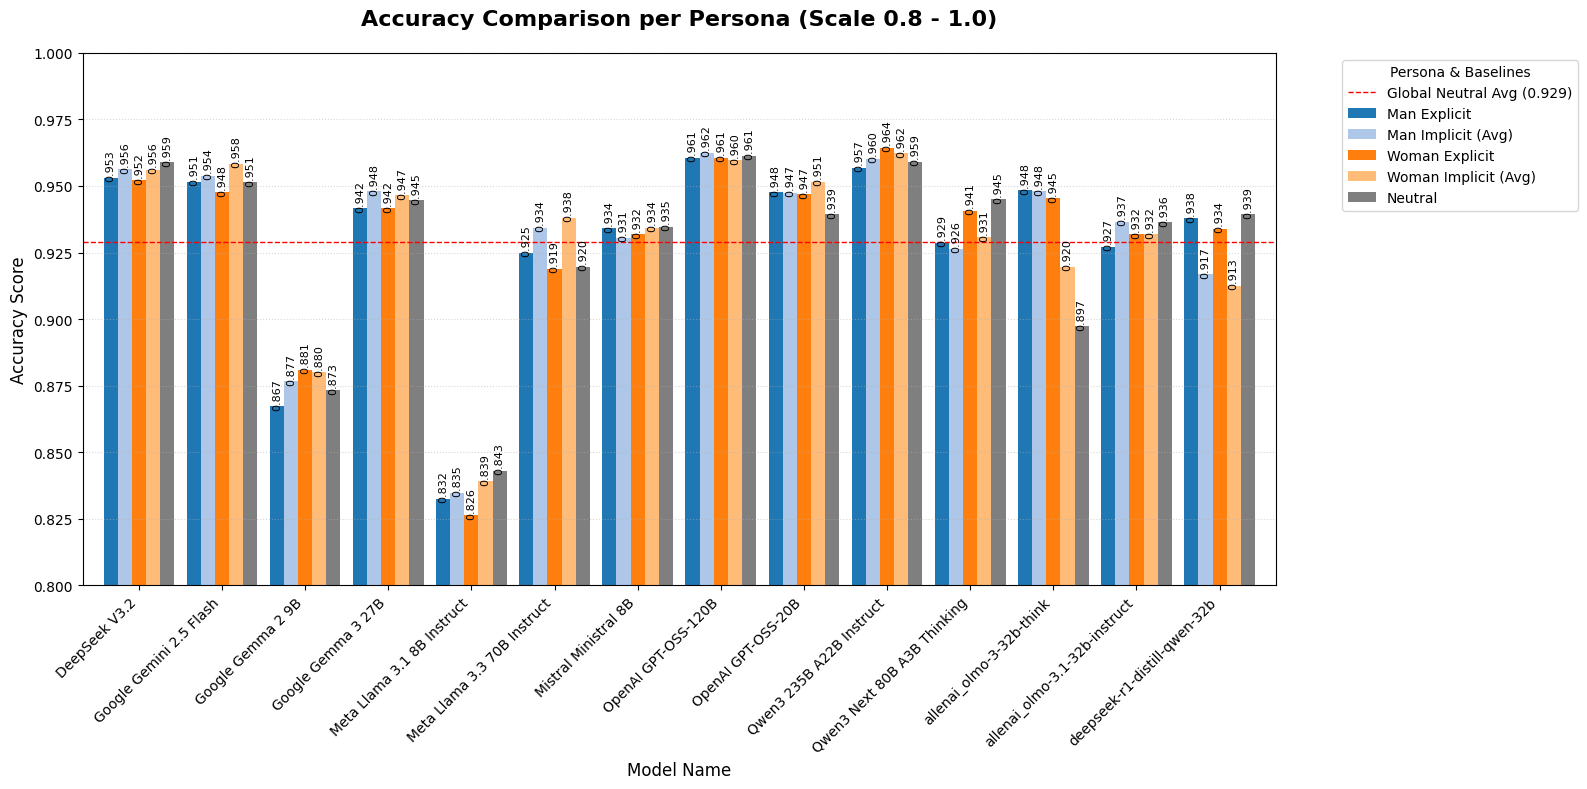

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Define the exact column order, placing 'Neutral' at the end as the control group
column_order = [
    'Man Explicit',
    'Man Implicit (Avg)',
    'Woman Explicit',
    'Woman Implicit (Avg)',
    'Neutral'
]

# Custom colors: Blue tones for Man, Orange tones for Woman, Gray for Neutral
custom_colors = ['#1f77b4', '#aec7e8', '#ff7f0e', '#ffbb78', '#7f7f7f']

# Create the main bar plot
ax = df_pivot[column_order].plot(
    kind='bar',
    figsize=(16, 8),
    width=0.85,
    color=custom_colors
)

# SET SCALE: Range 0.8 to 1.0 (ensure data doesn't drop below 0.8)
plt.ylim(0.8, 1.0)

# ----------------------------------------------------------------------
# NEW ADDITION: Global Baseline for Neutral Persona
# ----------------------------------------------------------------------
# Cermat calculation: Find the mean of the 'Neutral' column across ALL models
overall_neutral_avg = df_pivot['Neutral'].mean()

# Draw the horizontal dashed line using axhline
plt.axhline(
    y=overall_neutral_avg,
    color='red',
    linestyle='--',
    linewidth=1,
    label=f'Global Neutral Avg ({overall_neutral_avg:.3f})' # Adding exact value to legend
)
# ----------------------------------------------------------------------

# ADD NUMBERS: Label on top of each bar for precise reading
for p in ax.patches:
    # Thinking ahead: Only annotate if height is > 0 to prevent messy overlapping
    if p.get_height() > 0:
        ax.annotate(f'{p.get_height():.3f}',
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center',
                    xytext=(0, 9),
                    textcoords='offset points',
                    fontsize=8, rotation=90)

# Formatting the chart for an academic/professional look
plt.title('Accuracy Comparison per Persona (Scale 0.8 - 1.0)', fontsize=16, pad=20, fontweight='bold')
plt.ylabel('Accuracy Score', fontsize=12)
plt.xlabel('Model Name', fontsize=12)

# Update legend to include the new horizontal line
# Placed outside the plot to avoid blocking the bars or the new line
plt.legend(title='Persona & Baselines', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add subtle grid lines for the y-axis
plt.grid(axis='y', linestyle=':', alpha=0.5)
plt.xticks(rotation=45, ha='right')

# Ensure layout is neat before displaying or saving
plt.tight_layout()
plt.show()

### Statistical Significance Testing (T-Tests) per Model

Analisis ini bertujuan untuk menentukan apakah perbedaan akurasi yang kita lihat pada visualisasi sebelumnya signifikan secara statistik atau hanya kebetulan.

**Metode:** Welch's T-test (karena jumlah sampel dan varians antar persona mungkin berbeda).
**Hipotesis:**
- $H_0$: Tidak ada perbedaan performa antara dua persona.
- $H_a$: Terdapat perbedaan performa yang signifikan ($p < 0.05$).

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Menyiapkan data p-value dari df_sig_final yang sudah ada di kernel
df_viz_sig = df_sig_final.set_index('Model')

plt.figure(figsize=(20, 10), dpi=100)
plt.rcParams['font.family'] = 'serif'

# Visualisasi menggunakan Heatmap
# Warna merah menunjukkan signifikansi (p < 0.05)
ax = sns.heatmap(
    df_viz_sig,
    annot=True,
    fmt='.4f',
    cmap='Reds_r',
    vmax=0.05,
    center=0.025,
    linewidths=0.5,
    cbar_kws={'label': 'P-Value (Red indicates statistical significance < 0.05)'}
)

plt.title('Statistical Significance Heatmap\n(Comparing Genders, Explicit vs Implicit, and Neutral Baseline)', fontsize=18, fontweight='bold', pad=30)
plt.ylabel('Model Architecture', fontsize=12)
plt.xlabel('Statistical Comparison Categories', fontsize=12)

plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

NameError: name 'df_sig_final' is not defined

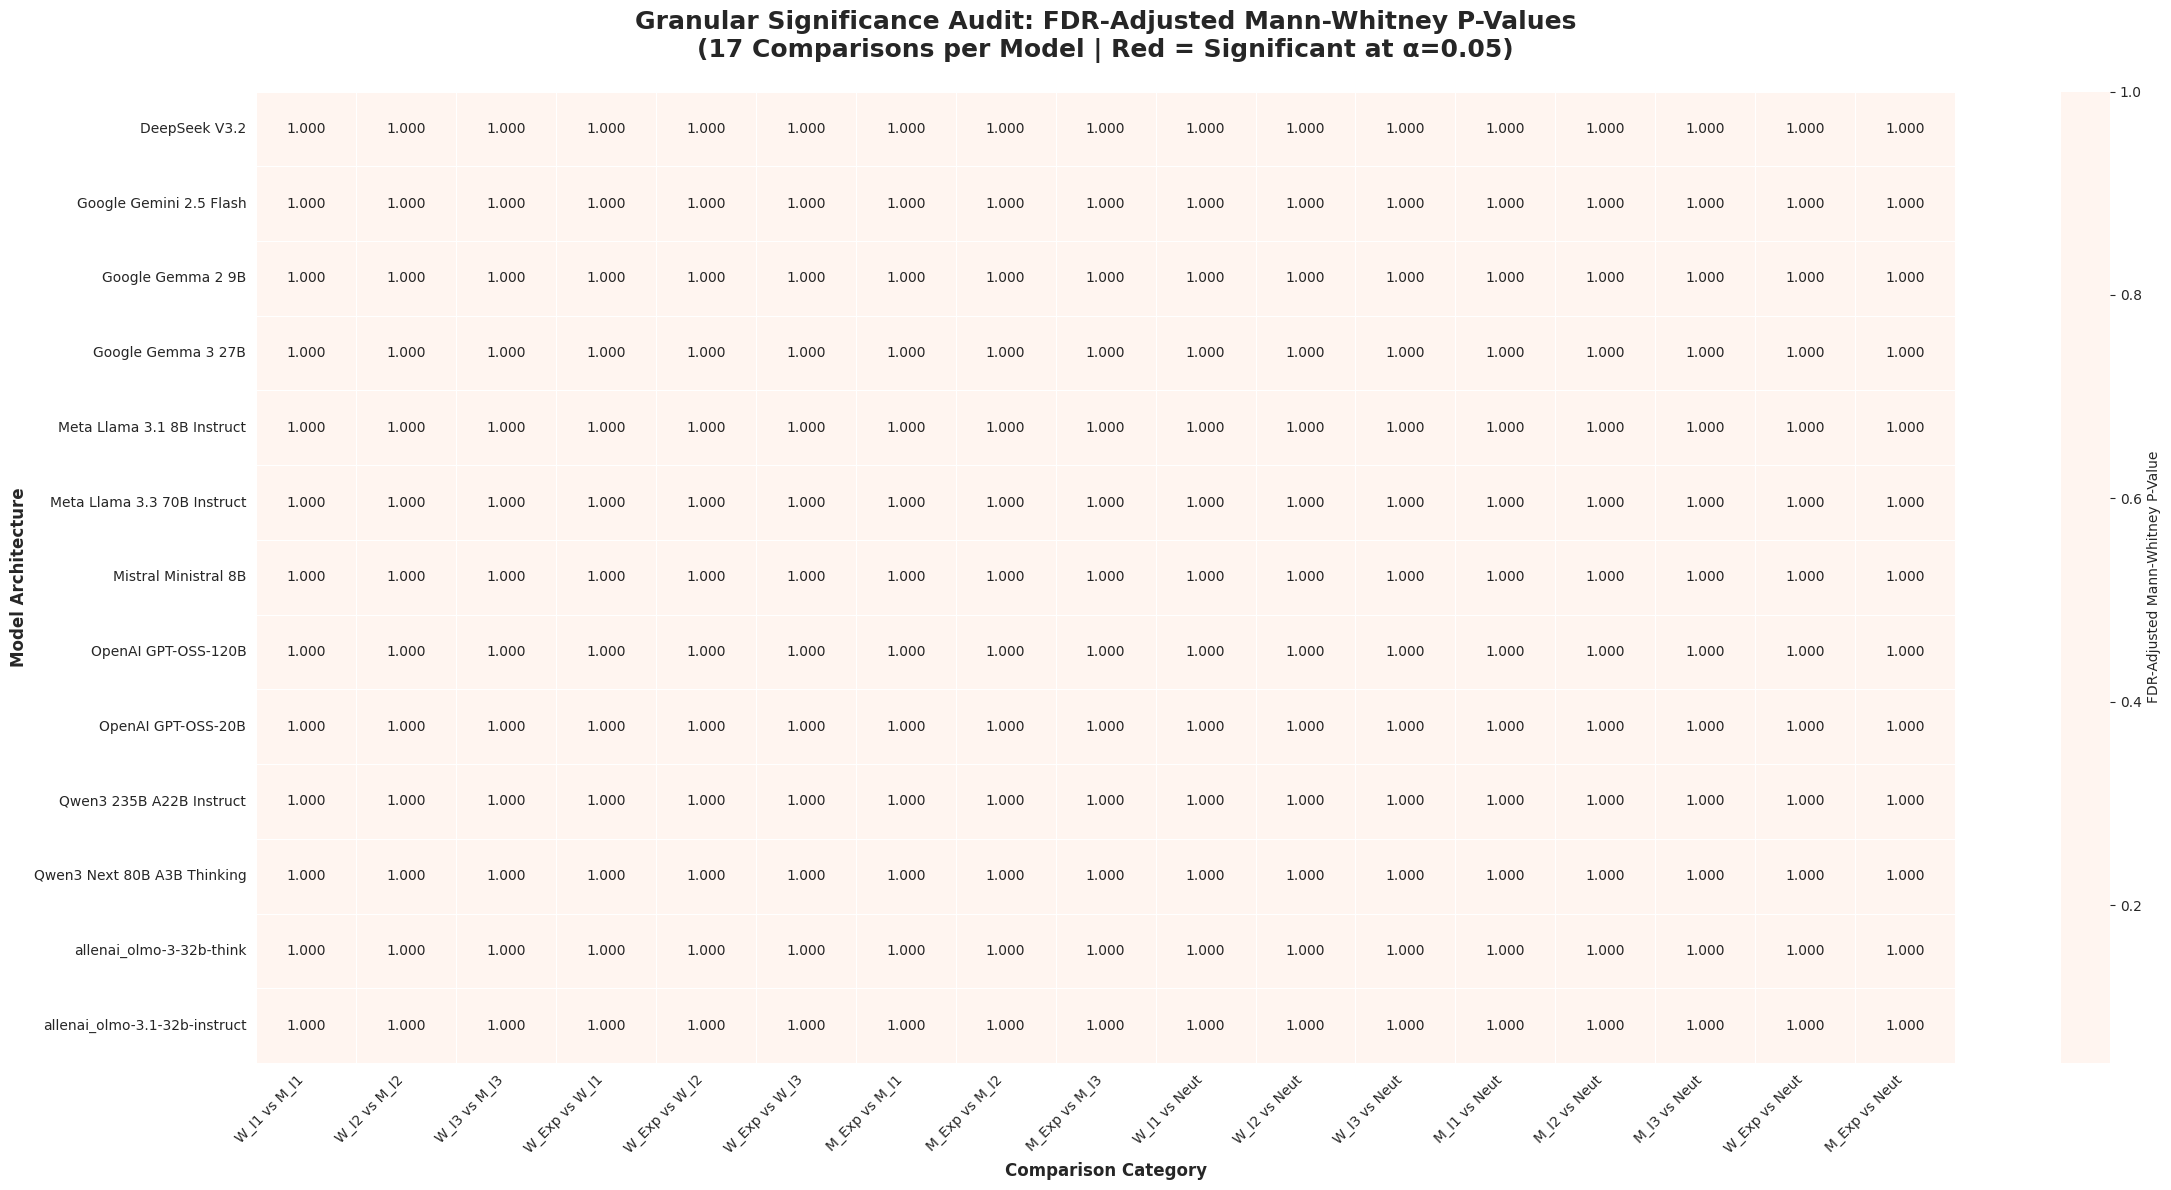

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Using P_Value_U_Adj as it is more robust for non-parametric comparisons
# and was successfully created for all comparisons in the previous step.
df_heat = df_granular_stats.pivot(index='Model', columns='Comparison', values='P_Value_U_Adj')

# Define the logical grouping order for columns
column_order = [
    'W_I1 vs M_I1', 'W_I2 vs M_I2', 'W_I3 vs M_I3',
    'W_Exp vs W_I1', 'W_Exp vs W_I2', 'W_Exp vs W_I3',
    'M_Exp vs M_I1', 'M_Exp vs M_I2', 'M_Exp vs M_I3',
    'W_I1 vs Neut', 'W_I2 vs Neut', 'W_I3 vs Neut',
    'M_I1 vs Neut', 'M_I2 vs Neut', 'M_I3 vs Neut',
    'W_Exp vs Neut', 'M_Exp vs Neut'
]

# Ensure we match the exact requested order and handle any potentially missing columns safely
df_heat = df_heat.reindex(columns=column_order)

plt.figure(figsize=(24, 12), dpi=100)
sns.set_style("white")

# Plot the heatmap
ax = sns.heatmap(df_heat, annot=True, fmt='.3f', cmap='Reds_r', vmax=0.05, center=0.025,
                 linewidths=.5, cbar_kws={'label': 'FDR-Adjusted Mann-Whitney P-Value'})

plt.title('Granular Significance Audit: FDR-Adjusted Mann-Whitney P-Values\n(17 Comparisons per Model | Red = Significant at α=0.05)', fontsize=18, fontweight='bold', pad=25)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.ylabel('Model Architecture', fontsize=12, fontweight='bold')
plt.xlabel('Comparison Category', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

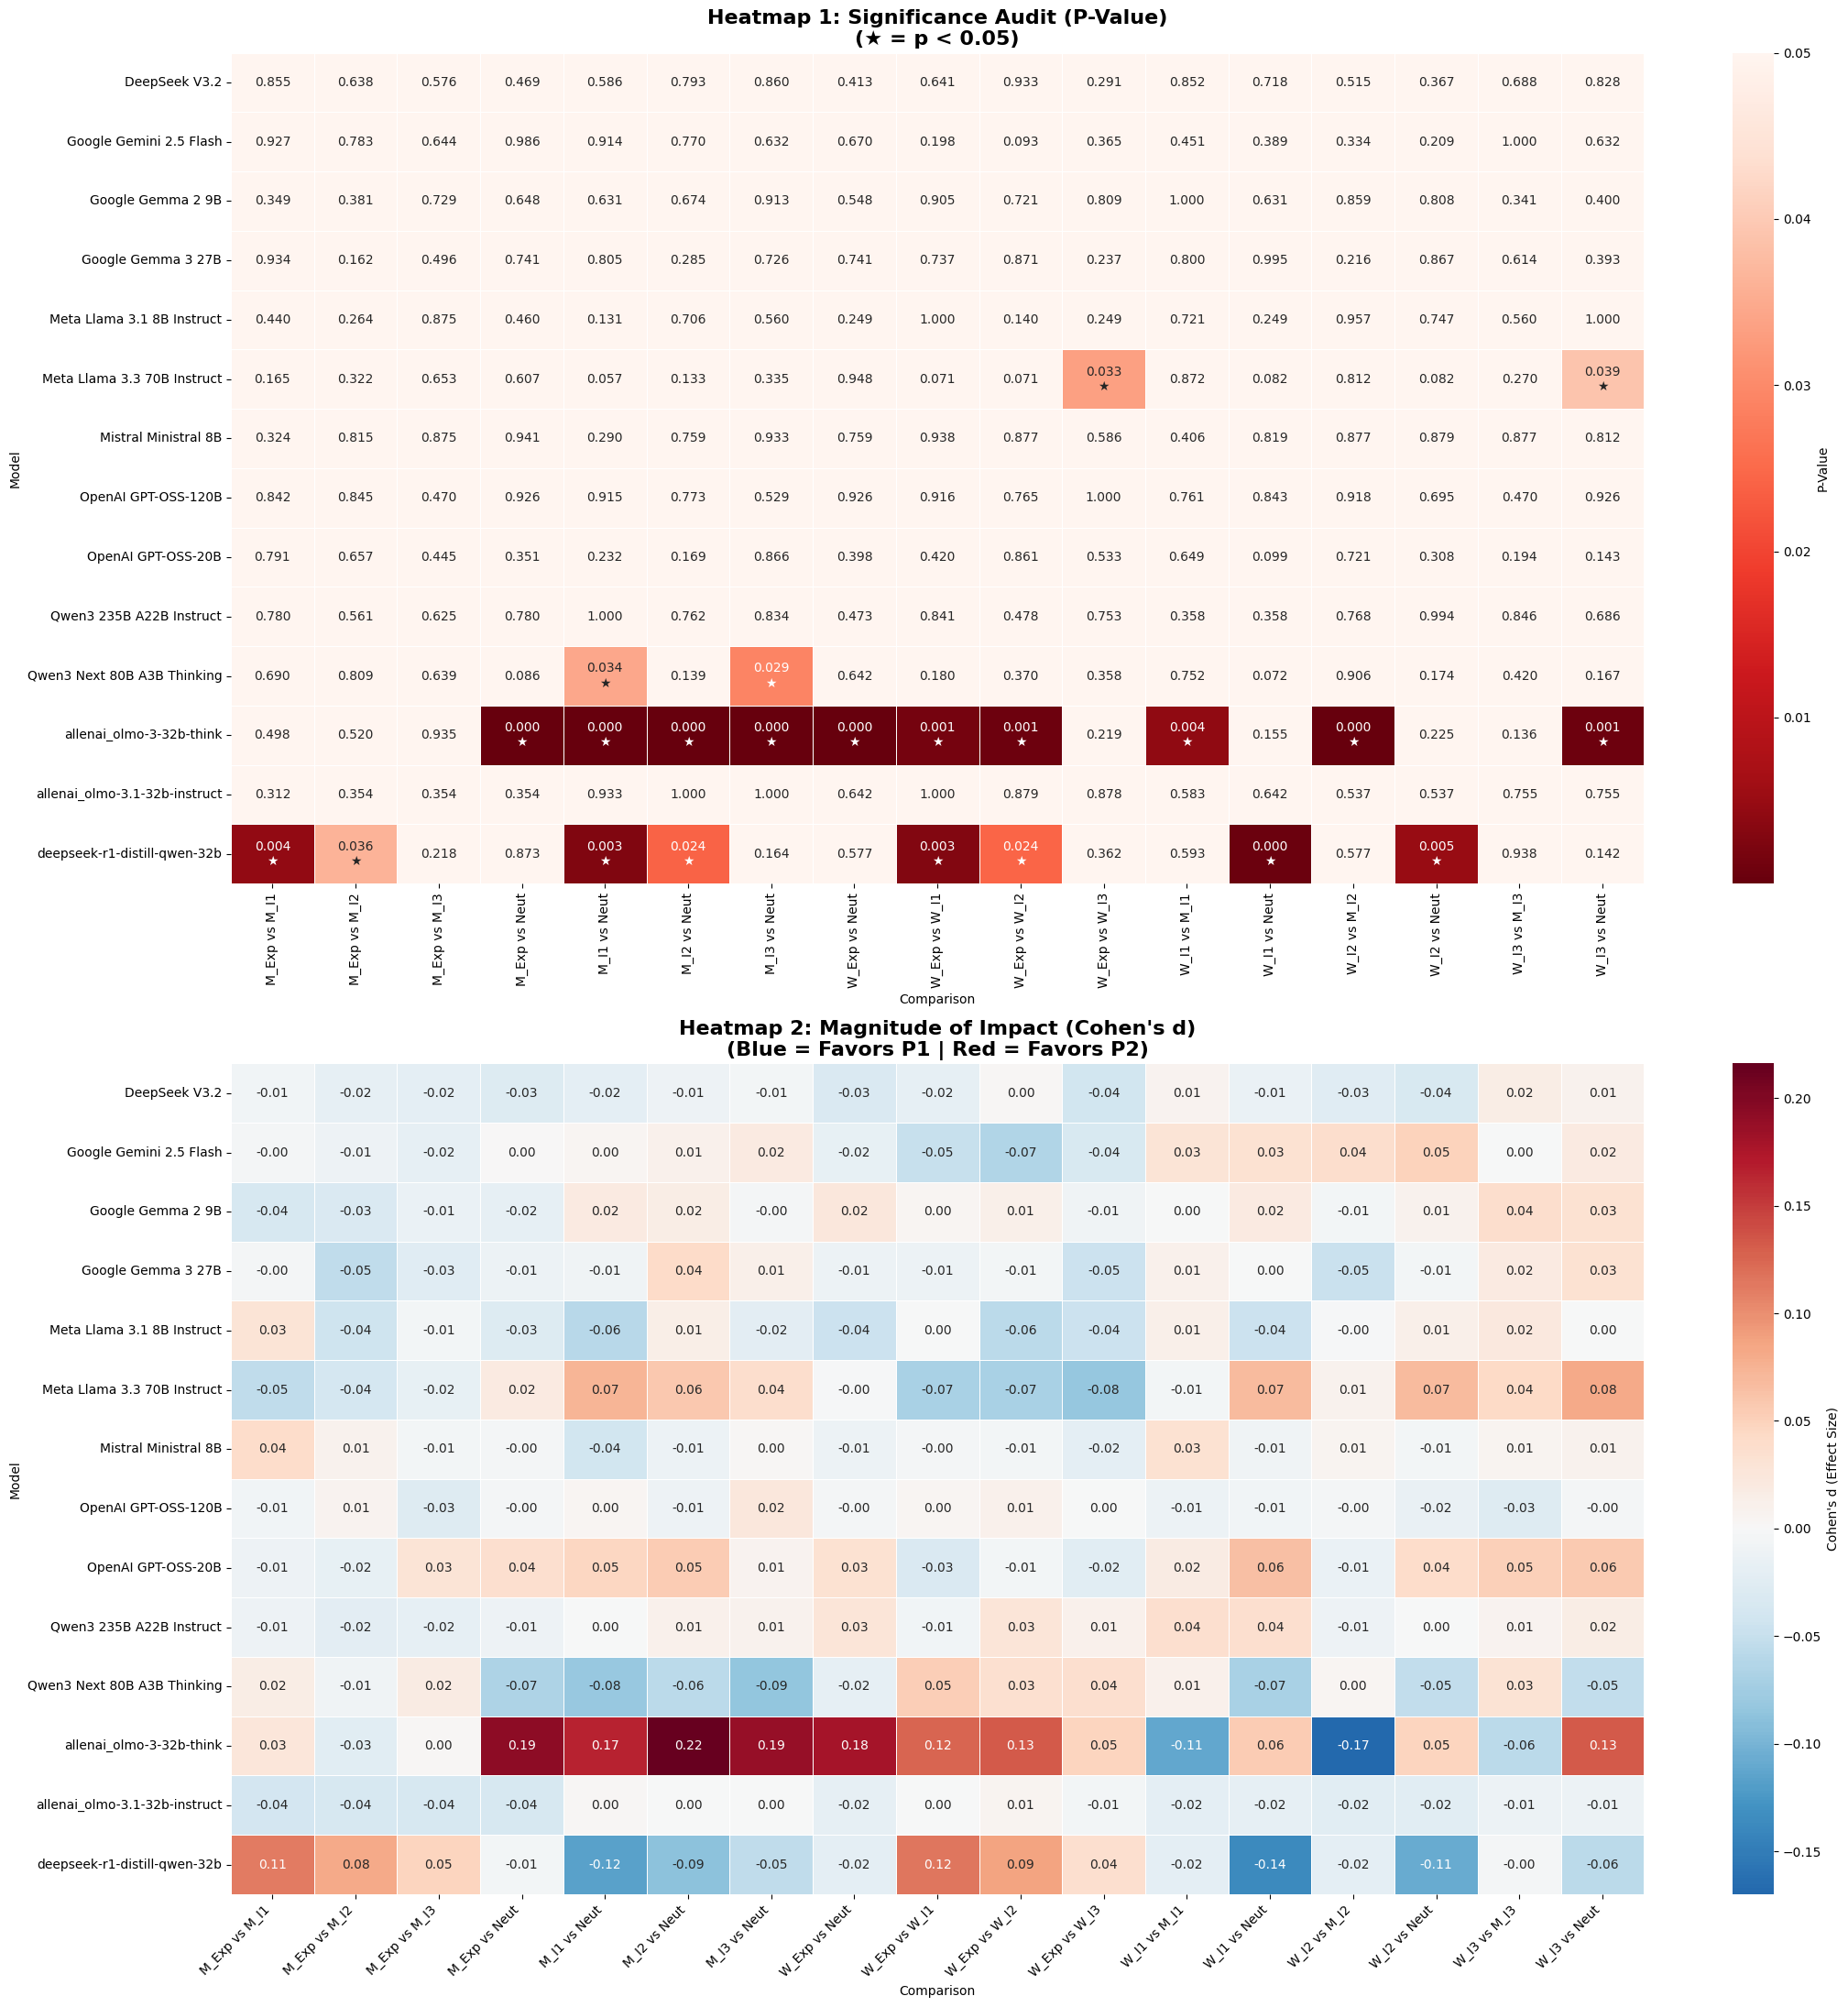

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import gspread
from google.colab import auth
from google.auth import default
from scipy.stats import ttest_ind_from_stats

# 1. Authentication and Data Loading
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

spreadsheet_url = "https://docs.google.com/spreadsheets/d/17cSsi5b1aMQFjjc7PHKgz0oeBlnQ9jiNXKdYWJ4Gjqk/edit?usp=sharing"
ss = gc.open_by_url(spreadsheet_url)

# Load the 4th sheet (Index 3)
worksheet = ss.get_worksheet(3)
raw_rows = worksheet.get_all_values()

# 2. Data Cleaning & Extraction
target_personas = [
    'man_explicit_1', 'man_implicit_1', 'man_implicit_2', 'man_implicit_3',
    'woman_explicit_1', 'woman_implicit_1', 'woman_implicit_2', 'woman_implicit_3',
    'neutral'
]

clean_records = []
current_model = None

for row in raw_rows:
    if not row: continue
    for val in row:
        if isinstance(val, str) and "Model:" in val:
            current_model = val.replace("Model:", "").strip()
            break
    if isinstance(row[0], str) and row[0] not in ['model_name', 'ALL', 'nan', ''] and "Model:" not in row[0]:
        current_model = row[0].strip()
    if len(row) >= 5 and row[1] in target_personas:
        model_name = row[0].strip() if row[0] not in ['nan', ''] else current_model
        try:
            record = {
                'Model': model_name,
                'Persona': row[1],
                'Correct': float(row[2]),
                'Total': float(row[3]),
                'Accuracy': float(row[4])
            }
            clean_records.append(record)
        except (ValueError, IndexError):
            continue

df_clean = pd.DataFrame(clean_records)

# 3. Calculate Standard Deviation, P-Value, and Cohen's d
def calc_std(r):
    p = r['Accuracy']
    n = r['Total']
    var = (p * (1 - p)) * (n / (n - 1)) if n > 1 else 0
    return np.sqrt(var)

df_clean['Std'] = df_clean.apply(calc_std, axis=1)

comp_mapping = {
    'W_I1 vs M_I1': ('woman_implicit_1', 'man_implicit_1'),
    'W_I2 vs M_I2': ('woman_implicit_2', 'man_implicit_2'),
    'W_I3 vs M_I3': ('woman_implicit_3', 'man_implicit_3'),
    'W_Exp vs W_I1': ('woman_explicit_1', 'woman_implicit_1'),
    'W_Exp vs W_I2': ('woman_explicit_1', 'woman_implicit_2'),
    'W_Exp vs W_I3': ('woman_explicit_1', 'woman_implicit_3'),
    'M_Exp vs M_I1': ('man_explicit_1', 'man_implicit_1'),
    'M_Exp vs M_I2': ('man_explicit_1', 'man_implicit_2'),
    'M_Exp vs M_I3': ('man_explicit_1', 'man_implicit_3'),
    'W_I1 vs Neut': ('woman_implicit_1', 'neutral'),
    'W_I2 vs Neut': ('woman_implicit_2', 'neutral'),
    'W_I3 vs Neut': ('woman_implicit_3', 'neutral'),
    'M_I1 vs Neut': ('man_implicit_1', 'neutral'),
    'M_I2 vs Neut': ('man_implicit_2', 'neutral'),
    'M_I3 vs Neut': ('man_implicit_3', 'neutral'),
    'W_Exp vs Neut': ('woman_explicit_1', 'neutral'),
    'M_Exp vs Neut': ('man_explicit_1', 'neutral'),
}

stats_records = []
for model in df_clean['Model'].unique():
    model_df = df_clean[df_clean['Model'] == model].set_index('Persona')
    for comp_name, (p1, p2) in comp_mapping.items():
        if p1 in model_df.index and p2 in model_df.index:
            r1, r2 = model_df.loc[p1], model_df.loc[p2]
            t_stat, p_val = ttest_ind_from_stats(
                mean1=r1['Accuracy'], std1=r1['Std'], nobs1=r1['Total'],
                mean2=r2['Accuracy'], std2=r2['Std'], nobs2=r2['Total'],
                equal_var=False
            )
            n1, n2 = r1['Total'], r2['Total']
            s1, s2 = r1['Std'], r2['Std']
            pooled_sd = np.sqrt(((n1-1)*s1**2 + (n2-1)*s2**2) / (n1+n2-2))
            d = (r1['Accuracy'] - r2['Accuracy']) / pooled_sd if pooled_sd != 0 else 0
            stats_records.append({'Model': model, 'Comparison': comp_name, 'P_Value': p_val, 'Cohens_D': d})

df_stats = pd.DataFrame(stats_records)

# 4. Visualization: Dual Heatmaps (English)
pivot_p = df_stats.pivot(index="Model", columns="Comparison", values="P_Value").dropna(how='all', axis=0).dropna(how='all', axis=1).sort_index()
pivot_d = df_stats.pivot(index="Model", columns="Comparison", values="Cohens_D").reindex(index=pivot_p.index, columns=pivot_p.columns)

def annotate_sig(val):
    if pd.isna(val): return ""
    return f"{val:.3f}\n★" if val < 0.05 else f"{val:.3f}"

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(22, 22))
sns.heatmap(pivot_p, cmap="Reds_r", annot=pivot_p.map(annotate_sig), fmt="", vmax=0.05, center=0.025, linewidths=0.5, ax=ax1, cbar_kws={'label': 'P-Value'})
ax1.set_title("Heatmap 1: Significance Audit (P-Value)\n(★ = p < 0.05)", fontsize=16, fontweight='bold')
sns.heatmap(pivot_d, cmap="RdBu_r", annot=True, fmt=".2f", center=0, linewidths=0.5, ax=ax2, cbar_kws={'label': "Cohen's d (Effect Size)"})
ax2.set_title("Heatmap 2: Magnitude of Impact (Cohen's d)\n(Blue = Favors P1 | Red = Favors P2)", fontsize=16, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Prepare the data from the existing significance results
df_viz_sig = df_sig_final.set_index('Model')

plt.figure(figsize=(18, 10), dpi=100)
plt.rcParams['font.family'] = 'serif'

# Create the Heatmap
# Values < 0.05 will appear in darker red
ax = sns.heatmap(
    df_viz_sig,
    annot=True,
    fmt='.4f',
    cmap='Reds_r',
    vmax=0.05,
    center=0.025,
    linewidths=0.5,
    cbar_kws={'label': 'P-Value (Red < 0.05 is Significant)'}
)

plt.title('Statistical Significance Audit Heatmap\n(Cross-Gender and Persona vs. Neutral Baseline)', fontsize=16, fontweight='bold', pad=25)
plt.ylabel('Model Architecture', fontsize=12)
plt.xlabel('Statistical Comparison Type', fontsize=12)

plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

NameError: name 'df_sig_final' is not defined

In [ ]:
df_raw['Persona'].unique()

array(['man_explicit_1', 'man_implicit_1', 'man_implicit_2',
       'man_implicit_3', 'woman_explicit_1', 'woman_implicit_1',
       'woman_implicit_2', 'woman_implicit_3', 'neutral'], dtype=object)

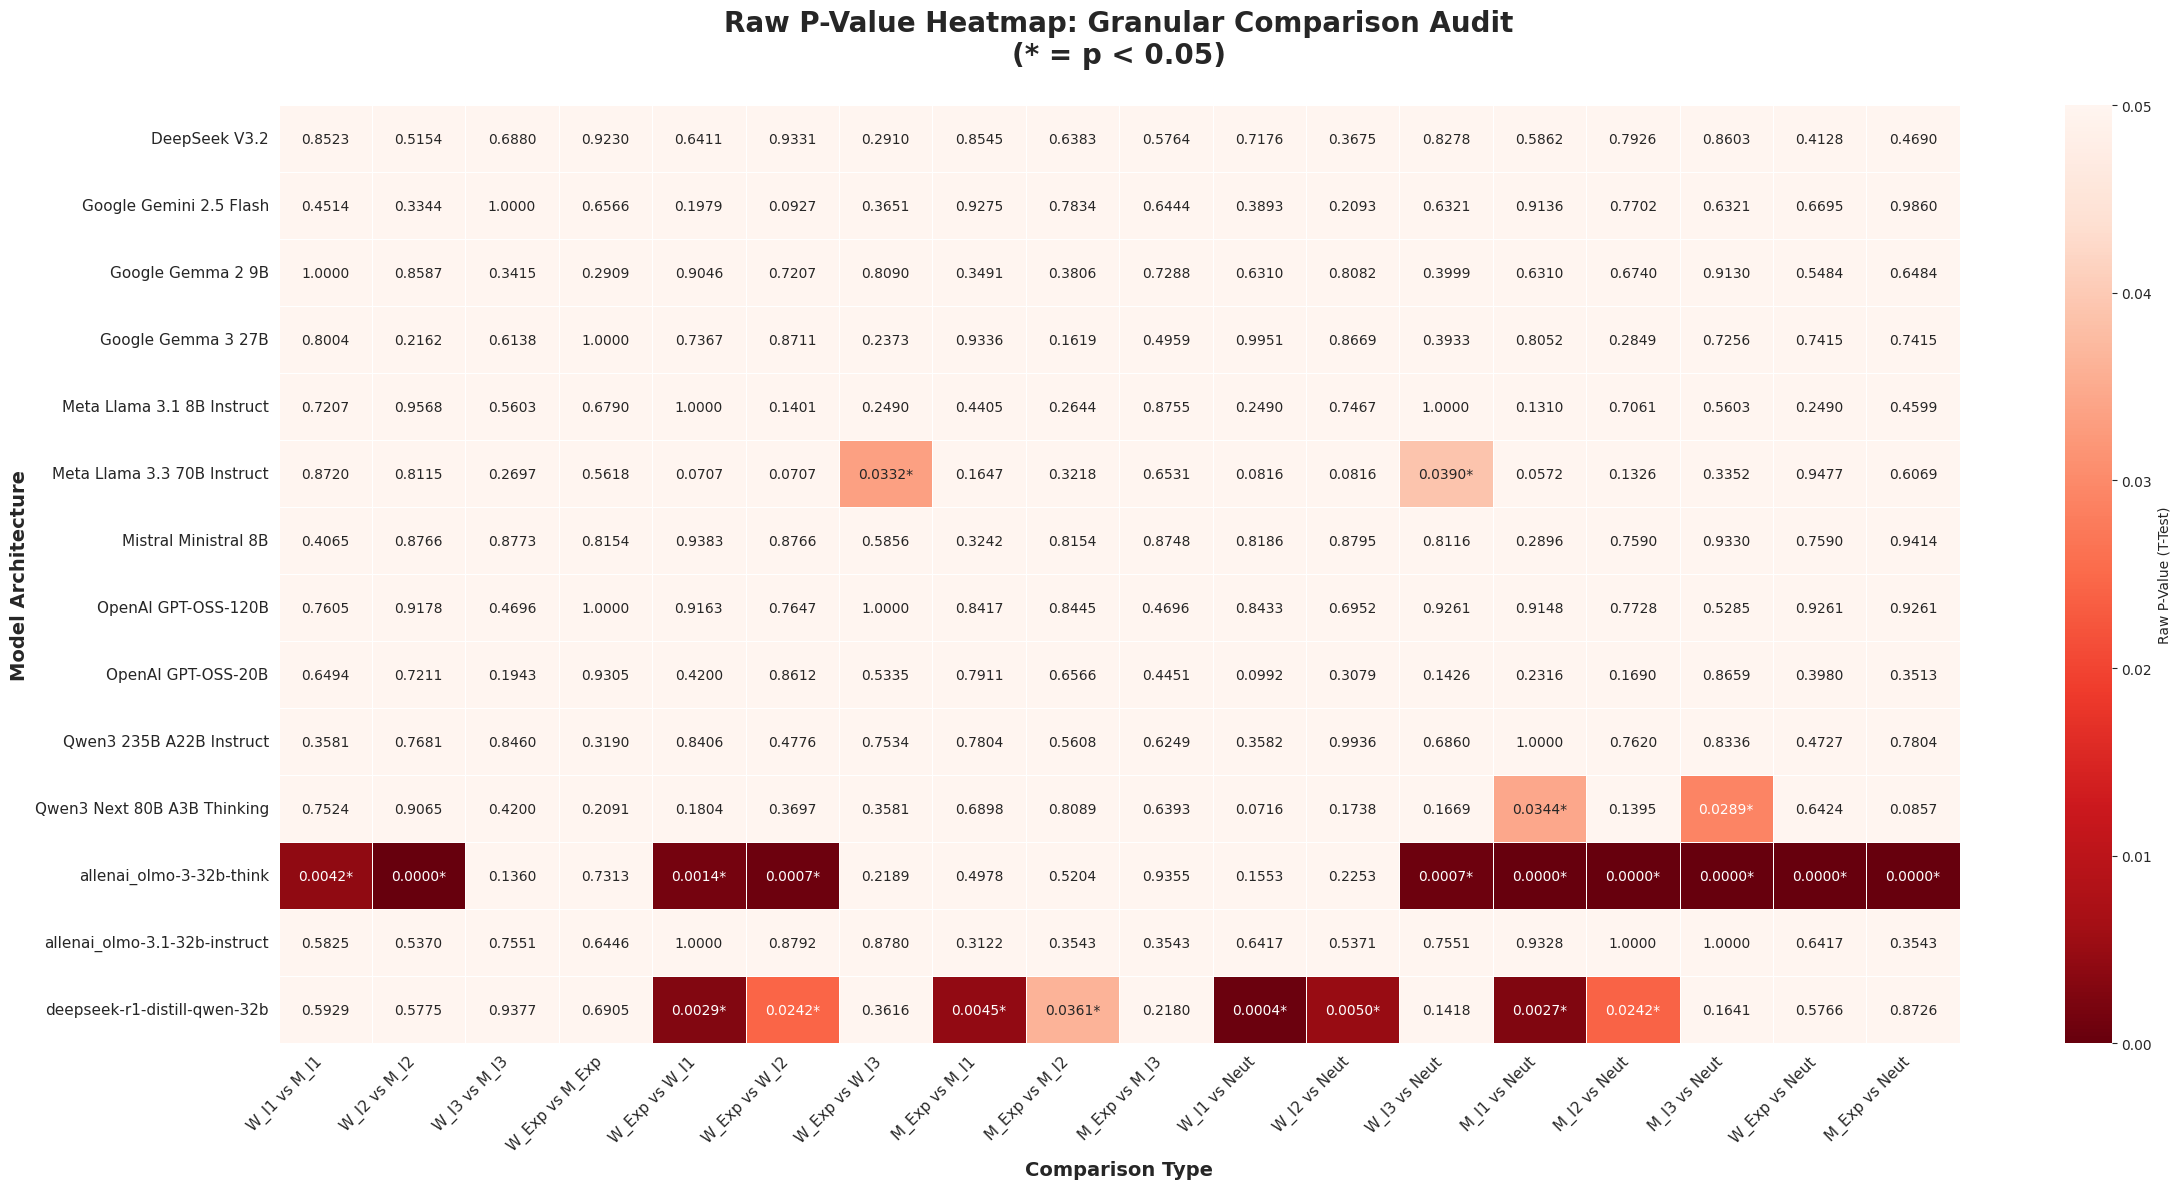

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import gspread
from google.colab import auth
from google.auth import default
from scipy.stats import ttest_ind_from_stats

# 1. Authentication and Data Loading
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

spreadsheet_url = "https://docs.google.com/spreadsheets/d/17cSsi5b1aMQFjjc7PHKgz0oeBlnQ9jiNXKdYWJ4Gjqk/edit?usp=sharing"
ss = gc.open_by_url(spreadsheet_url)

# Load the 4th sheet (Index 3)
worksheet = ss.get_worksheet(3)
raw_rows = worksheet.get_all_values()

# 2. Data Cleaning & Extraction
target_personas = [
    'man_explicit_1', 'man_implicit_1', 'man_implicit_2', 'man_implicit_3',
    'woman_explicit_1', 'woman_implicit_1', 'woman_implicit_2', 'woman_implicit_3',
    'neutral'
]

clean_records = []
current_model = None

for row in raw_rows:
    if not row: continue

    for val in row:
        if isinstance(val, str) and "Model:" in val:
            current_model = val.replace("Model:", "").strip()
            break

    if isinstance(row[0], str) and row[0] not in ['model_name', 'ALL', 'nan', ''] and "Model:" not in row[0]:
        current_model = row[0].strip()

    if len(row) >= 5 and row[1] in target_personas:
        model_name = row[0].strip() if row[0] not in ['nan', ''] else current_model
        try:
            record = {
                'Model': model_name,
                'Persona': row[1],
                'Correct': float(row[2]),
                'Total': float(row[3]),
                'Accuracy': float(row[4])
            }
            clean_records.append(record)
        except (ValueError, IndexError):
            continue

df_clean = pd.DataFrame(clean_records)

# 3. Hitung Standard Deviation & P-Value
def calc_std(r):
    p = r['Accuracy']
    n = r['Total']
    var = (p * (1 - p)) * (n / (n - 1)) if n > 1 else 0
    return np.sqrt(var)

df_clean['Std'] = df_clean.apply(calc_std, axis=1)

comp_mapping = {
    'W_I1 vs M_I1': ('woman_implicit_1', 'man_implicit_1'),
    'W_I2 vs M_I2': ('woman_implicit_2', 'man_implicit_2'),
    'W_I3 vs M_I3': ('woman_implicit_3', 'man_implicit_3'),
    'W_Exp vs M_Exp': ('woman_explicit_1', 'man_explicit_1'),
    'W_Exp vs W_I1': ('woman_explicit_1', 'woman_implicit_1'),
    'W_Exp vs W_I2': ('woman_explicit_1', 'woman_implicit_2'),
    'W_Exp vs W_I3': ('woman_explicit_1', 'woman_implicit_3'),
    'M_Exp vs M_I1': ('man_explicit_1', 'man_implicit_1'),
    'M_Exp vs M_I2': ('man_explicit_1', 'man_implicit_2'),
    'M_Exp vs M_I3': ('man_explicit_1', 'man_implicit_3'),
    'W_I1 vs Neut': ('woman_implicit_1', 'neutral'),
    'W_I2 vs Neut': ('woman_implicit_2', 'neutral'),
    'W_I3 vs Neut': ('woman_implicit_3', 'neutral'),
    'M_I1 vs Neut': ('man_implicit_1', 'neutral'),
    'M_I2 vs Neut': ('man_implicit_2', 'neutral'),
    'M_I3 vs Neut': ('man_implicit_3', 'neutral'),
    'W_Exp vs Neut': ('woman_explicit_1', 'neutral'),
    'M_Exp vs Neut': ('man_explicit_1', 'neutral'),
}

p_value_records = []
for model in df_clean['Model'].unique():
    model_df = df_clean[df_clean['Model'] == model].set_index('Persona')
    for comp_name, (p1, p2) in comp_mapping.items():
        if p1 in model_df.index and p2 in model_df.index:
            row1, row2 = model_df.loc[p1], model_df.loc[p2]
            t_stat, p_val = ttest_ind_from_stats(
                mean1=row1['Accuracy'], std1=row1['Std'], nobs1=row1['Total'],
                mean2=row2['Accuracy'], std2=row2['Std'], nobs2=row2['Total'],
                equal_var=False
            )
            p_value_records.append({'Model': model, 'Comparison': comp_name, 'P_Value_T': p_val})

df_raw_p = pd.DataFrame(p_value_records).pivot(index='Model', columns='Comparison', values='P_Value_T')

# 4. Plotting
column_order = list(comp_mapping.keys())
df_raw_p = df_raw_p.reindex(columns=column_order)

def format_p(val):
    if pd.isna(val): return ""
    return f"{val:.4f}*" if val < 0.05 else f"{val:.4f}"

annot_matrix = df_raw_p.map(format_p)

plt.figure(figsize=(24, 12), dpi=100)
sns.set_style("white")

ax = sns.heatmap(
    df_raw_p, annot=annot_matrix, fmt="", cmap='Reds_r',
    vmax=0.05, vmin=0, center=0.025, linewidths=0.5,
    cbar_kws={'label': 'Raw P-Value (T-Test)'}
)

plt.title('Raw P-Value Heatmap: Granular Comparison Audit\n(* = p < 0.05)',
          fontsize=20, fontweight='bold', pad=30)
plt.xticks(rotation=45, ha='right', fontsize=11)
plt.yticks(fontsize=11)
plt.ylabel('Model Architecture', fontsize=14, fontweight='bold')
plt.xlabel('Comparison Type', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
# Pastikan code ini di-run SETELAH code heatmap sebelumnya (membutuhkan df_raw_p dan df_stats)

# 1. Definisi Kolom untuk Masing-Masing Kategori
wm_cols = ['W_I1 vs M_I1', 'W_I2 vs M_I2', 'W_I3 vs M_I3']

exp_imp_cols = [
    'W_Exp vs W_I1', 'W_Exp vs W_I2', 'W_Exp vs W_I3',
    'M_Exp vs M_I1', 'M_Exp vs M_I2', 'M_Exp vs M_I3'
]

neutral_cols = [
    'W_I1 vs Neut', 'W_I2 vs Neut', 'W_I3 vs Neut',
    'M_I1 vs Neut', 'M_I2 vs Neut', 'M_I3 vs Neut',
    'W_Exp vs Neut', 'M_Exp vs Neut'
]

# ---------------------------------------------------------
# PEMBUATAN TABEL 1: FOKUS W-M (Ditambah Cohen's d)
# ---------------------------------------------------------
df_summary_1 = pd.DataFrame(index=df_raw_p.index)

# Hitung jumlah p-value < 0.05 dan rata-rata p-value
df_summary_1['Significant W-M (Max 3)'] = (df_raw_p[wm_cols] < 0.05).sum(axis=1)
df_summary_1['Avg P-Value (W-M)'] = df_raw_p[wm_cols].mean(axis=1)

# Ambil Cohen's d dari df_stats yang dibuat di cell 4c4d9949
pivot_d = df_stats.pivot(index='Model', columns='Comparison', values='Cohens_D')
df_summary_1['Avg Cohen\'s d (W-M)'] = pivot_d[wm_cols].mean(axis=1)

# Tambahkan baris Grand Total
grand_total_1 = pd.DataFrame({
    'Significant W-M (Max 3)': [df_summary_1['Significant W-M (Max 3)'].sum()],
    'Avg P-Value (W-M)': [df_summary_1['Avg P-Value (W-M)'].mean()],
    'Avg Cohen\'s d (W-M)': [df_summary_1['Avg Cohen\'s d (W-M)'].mean()]
}, index=['Grand Total'])

df_summary_1 = pd.concat([df_summary_1, grand_total_1])

# ---------------------------------------------------------
# PEMBUATAN TABEL 2: REKAP 3 KATEGORI
# ---------------------------------------------------------
df_summary_2 = pd.DataFrame(index=df_raw_p.index)

df_summary_2['Sig W-M (3)'] = (df_raw_p[wm_cols] < 0.05).sum(axis=1)
df_summary_2['Sig Exp-Imp (6)'] = (df_raw_p[exp_imp_cols] < 0.05).sum(axis=1)
df_summary_2['Sig Neut (8)'] = (df_raw_p[neutral_cols] < 0.05).sum(axis=1)
df_summary_2['Avg Magnitude (Cohen\'s d)'] = pivot_d[wm_cols].abs().mean(axis=1)

# ---------------------------------------------------------
# TAMPILKAN HASILNYA
# ---------------------------------------------------------
print("="*60)
print("TABEL 1: W-M Comparisons Summary (Significance & Effect Size)")
print("="*60)
display(df_summary_1.style.format({
    'Avg P-Value (W-M)': "{:.4f}",
    'Avg Cohen\'s d (W-M)': "{:.4f}"
}))

print("\n" + "="*60)
print("TABEL 2: All Categories Significance Overview")
print("="*60)
display(df_summary_2.style.format({
    'Avg Magnitude (Cohen\'s d)': "{:.4f}"
}))

TABEL 1: W-M Comparisons Summary (Significance & Effect Size)


,Significant W-M (Max 3),Avg P-Value (W-M),Avg Cohen's d (W-M)
DeepSeek V3.2,0,0.6852,-0.0008
Google Gemini 2.5 Flash,0,0.5953,0.0223
Google Gemma 2 9B,0,0.7334,0.0100
Google Gemma 3 27B,0,0.5434,-0.0062
Meta Llama 3.1 8B Instruct,0,0.7459,0.0115
Meta Llama 3.3 70B Instruct,0,0.6511,0.0153
Mistral Ministral 8B,0,0.7201,0.0148
OpenAI GPT-OSS-120B,0,0.7160,-0.0147
OpenAI GPT-OSS-20B,0,0.5216,0.0181
Qwen3 235B A22B Instruct,0,0.6574,0.0106



TABEL 2: All Categories Significance Overview


,Sig W-M (3),Sig Exp-Imp (6),Sig Neut (8),Avg Magnitude (Cohen's d)
Model,,,,
DeepSeek V3.2,0,0,0,0.0161
Google Gemini 2.5 Flash,0,0,0,0.0223
Google Gemma 2 9B,0,0,0,0.0147
Google Gemma 3 27B,0,0,0,0.0259
Meta Llama 3.1 8B Instruct,0,0,0,0.0129
Meta Llama 3.3 70B Instruct,0,1,1,0.0195
Mistral Ministral 8B,0,0,0,0.0148
OpenAI GPT-OSS-120B,0,0,0,0.0147
OpenAI GPT-OSS-20B,0,0,0,0.0274


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Prepare data for visualization
# We'll use the results from the summary table created previously
df_viz_stats = df_final_stats.sort_values('Cohens_D', ascending=True)

# 2. Plotting Effect Size (Cohen's d)
plt.figure(figsize=(14, 7), dpi=100)
sns.set_style("whitegrid")

# Color mapping: Blue for favoring Man (Positive), Red for favoring Woman (Negative)
colors = ['#d62728' if x < 0 else '#1f77b4' for x in df_viz_stats['Cohens_D']]

ax = sns.barplot(
    data=df_viz_stats,
    x='Model',
    y='Cohens_D',
    palette=colors,
    edgecolor='black',
    hue='Model',
    legend=False
)

# Add interpretation zones for Cohen's d (Standard benchmarks)
plt.axhline(0.2, color='gray', linestyle='--', alpha=0.5)
plt.axhline(-0.2, color='gray', linestyle='--', alpha=0.5)
plt.text(0, 0.22, 'Small Effect (0.2)', color='gray', fontsize=9)

plt.axhline(0.5, color='orange', linestyle='--', alpha=0.5)
plt.axhline(-0.5, color='orange', linestyle='--', alpha=0.5)
plt.text(0, 0.52, 'Medium Effect (0.5)', color='orange', fontsize=9)

plt.axhline(0, color='black', linewidth=1.5)

# Annotate bars with exact values
for p in ax.patches:
    val = p.get_height()
    if abs(val) > 0:
        ax.annotate(f'{val:.3f}',
                    (p.get_x() + p.get_width() / 2., val),
                    ha='center', va='bottom' if val > 0 else 'top',
                    fontsize=9, fontweight='bold',
                    xytext=(0, 5 if val > 0 else -12),
                    textcoords='offset points')

plt.title("Effect Size (Cohen's d): Magnitude of Gender Bias\n(Positive = Favors Man | Negative = Favors Woman)", fontsize=15, fontweight='bold', pad=20)
plt.ylabel("Effect Size (Cohen's d)", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

NameError: name 'df_final_stats' is not defined

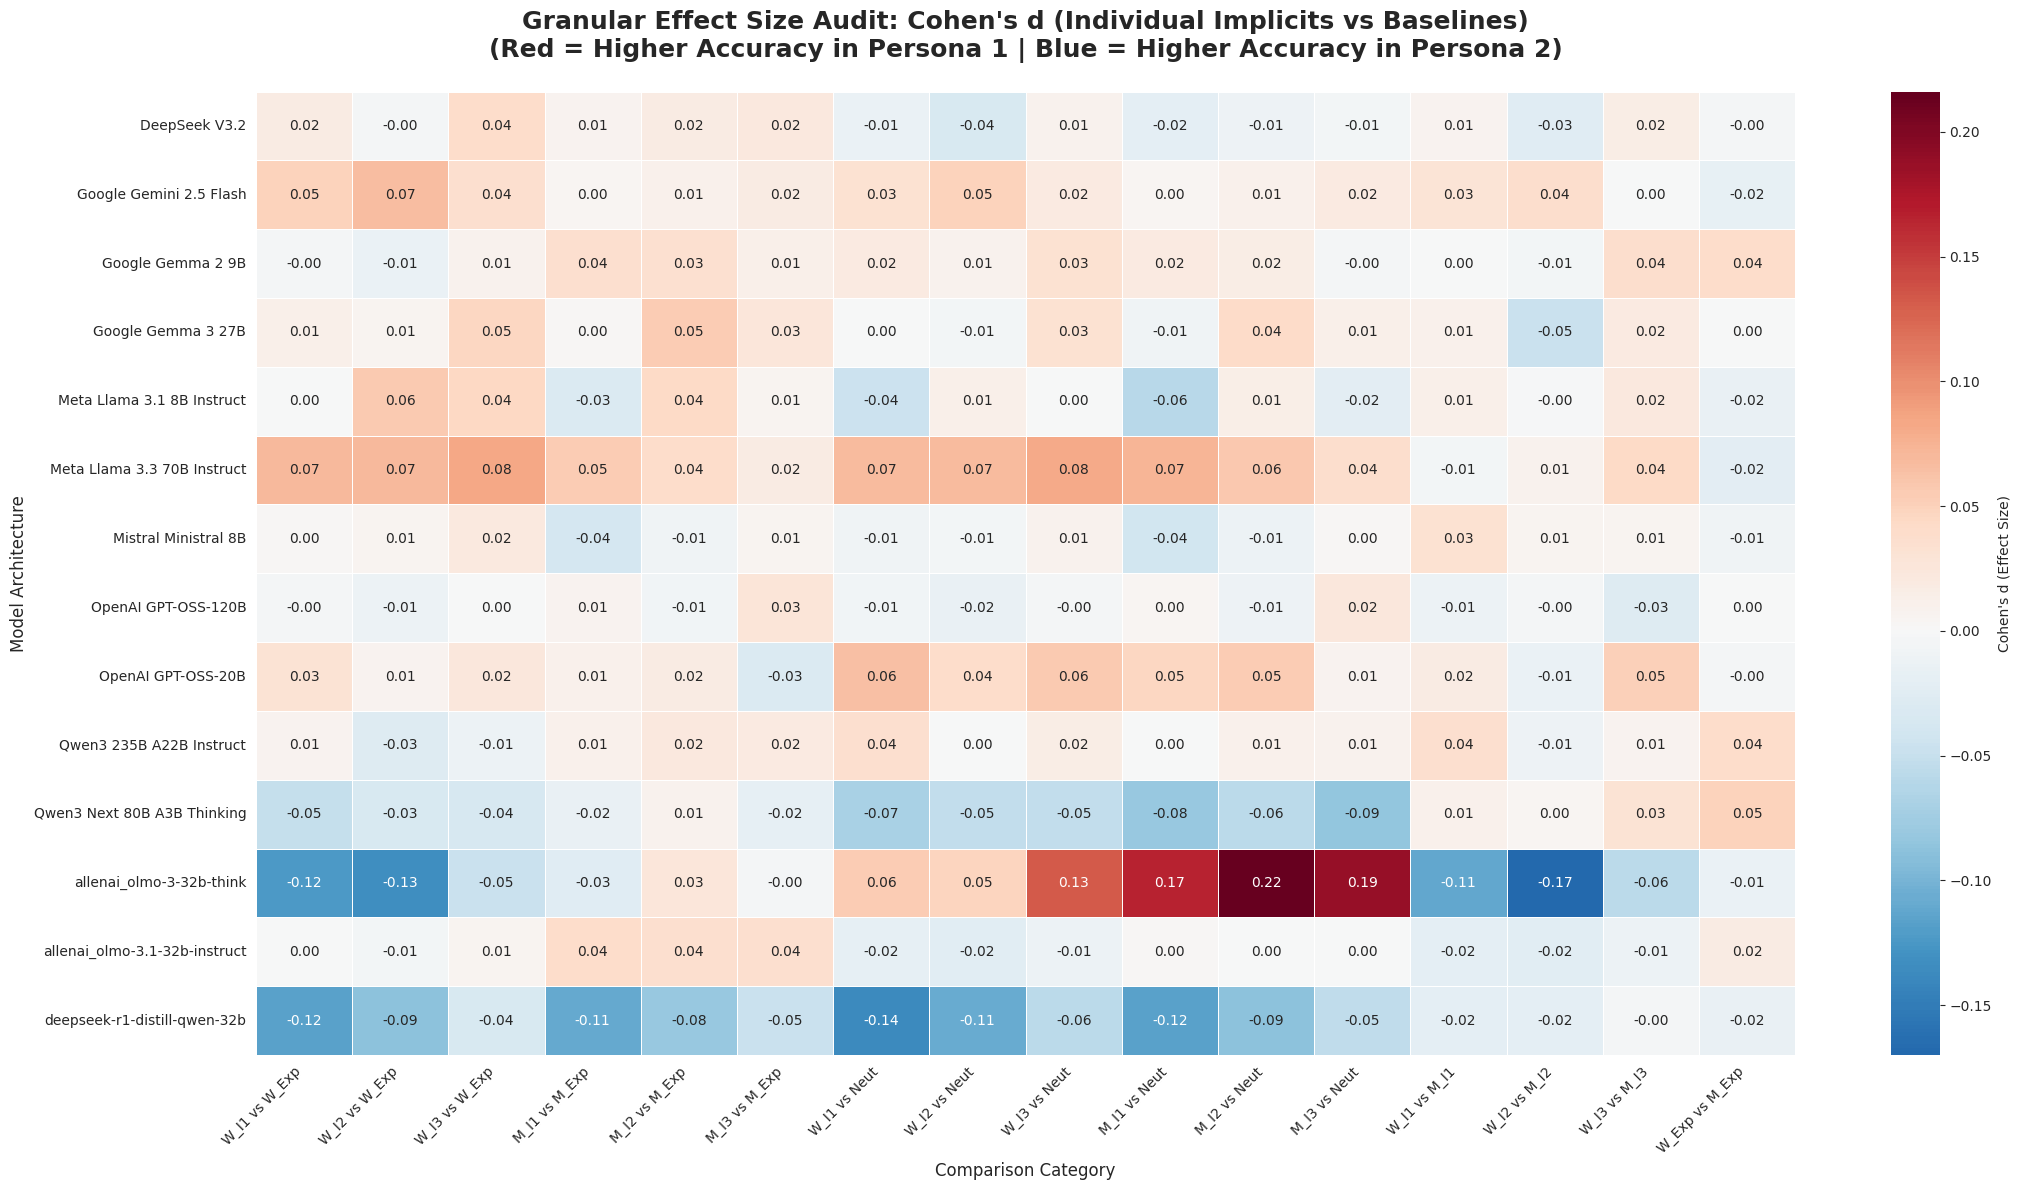

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Helper function for Cohen's d with pooled SD
def get_cohen_d(r1_acc, r1_std, n1, r2_acc, r2_std, n2):
    pooled_sd = np.sqrt(((n1 - 1) * r1_std**2 + (n2 - 1) * r2_std**2) / (n1 + n2 - 2))
    return (r1_acc - r2_acc) / pooled_sd if pooled_sd != 0 else 0

granular_stats_records = []

# Mapping for every specific comparison
# Focusing on each Implicit (1, 2, 3) vs Explicit and Neutral
comparisons = {
    'W_I1 vs W_Exp': ('woman_implicit_1', 'woman_explicit_1'),
    'W_I2 vs W_Exp': ('woman_implicit_2', 'woman_explicit_1'),
    'W_I3 vs W_Exp': ('woman_implicit_3', 'woman_explicit_1'),
    'M_I1 vs M_Exp': ('man_implicit_1', 'man_explicit_1'),
    'M_I2 vs M_Exp': ('man_implicit_2', 'man_explicit_1'),
    'M_I3 vs M_Exp': ('man_implicit_3', 'man_explicit_1'),
    'W_I1 vs Neut': ('woman_implicit_1', 'neutral'),
    'W_I2 vs Neut': ('woman_implicit_2', 'neutral'),
    'W_I3 vs Neut': ('woman_implicit_3', 'neutral'),
    'M_I1 vs Neut': ('man_implicit_1', 'neutral'),
    'M_I2 vs Neut': ('man_implicit_2', 'neutral'),
    'M_I3 vs Neut': ('man_implicit_3', 'neutral'),
    'W_I1 vs M_I1': ('woman_implicit_1', 'man_implicit_1'),
    'W_I2 vs M_I2': ('woman_implicit_2', 'man_implicit_2'),
    'W_I3 vs M_I3': ('woman_implicit_3', 'man_implicit_3'),
    'W_Exp vs M_Exp': ('woman_explicit_1', 'man_explicit_1'),
    'W_Exp vs Neut': ('woman_explicit_1', 'neutral'),
}

for model in df_clean['Model'].unique():
    model_df = df_clean[df_clean['Model'] == model].set_index('Persona')

    for label, (p1, p2) in comparisons.items():
        if p1 in model_df.index and p2 in model_df.index:
            r1, r2 = model_df.loc[p1], model_df.loc[p2]
            d = get_cohen_d(r1['Accuracy'], r1['Std'], r1['Total'],
                            r2['Accuracy'], r2['Std'], r2['Total'])
            granular_stats_records.append({'Model': model, 'Comparison': label, 'Cohens_D': d})

df_granular_d = pd.DataFrame(granular_stats_records).pivot(index='Model', columns='Comparison', values='Cohens_D')

# Ordering for logical flow
order = [
    'W_I1 vs W_Exp', 'W_I2 vs W_Exp', 'W_I3 vs W_Exp',
    'M_I1 vs M_Exp', 'M_I2 vs M_Exp', 'M_I3 vs M_Exp',
    'W_I1 vs Neut', 'W_I2 vs Neut', 'W_I3 vs Neut',
    'M_I1 vs Neut', 'M_I2 vs Neut', 'M_I3 vs Neut',
    'W_I1 vs M_I1', 'W_I2 vs M_I2', 'W_I3 vs M_I3', 'W_Exp vs M_Exp'
]
df_granular_d = df_granular_d.reindex(columns=order)

# Visualization
plt.figure(figsize=(22, 12), dpi=100)
sns.set_style("white")

ax = sns.heatmap(
    df_granular_d,
    annot=True,
    fmt=".2f",
    cmap='RdBu_r',
    center=0,
    linewidths=0.5,
    cbar_kws={'label': "Cohen's d (Effect Size)"}
)

plt.title("Granular Effect Size Audit: Cohen's d (Individual Implicits vs Baselines)\n(Red = Higher Accuracy in Persona 1 | Blue = Higher Accuracy in Persona 2)",
          fontsize=18, fontweight='bold', pad=25)
plt.ylabel('Model Architecture', fontsize=12)
plt.xlabel('Comparison Category', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

/tmp/ipykernel_1219/184387898.py:169: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) DejaVu Serif.
  plt.tight_layout() # Adjust layout to prevent overlapping
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) DejaVu Serif.
  fig.canvas.print_figure(bytes_io, **kw)


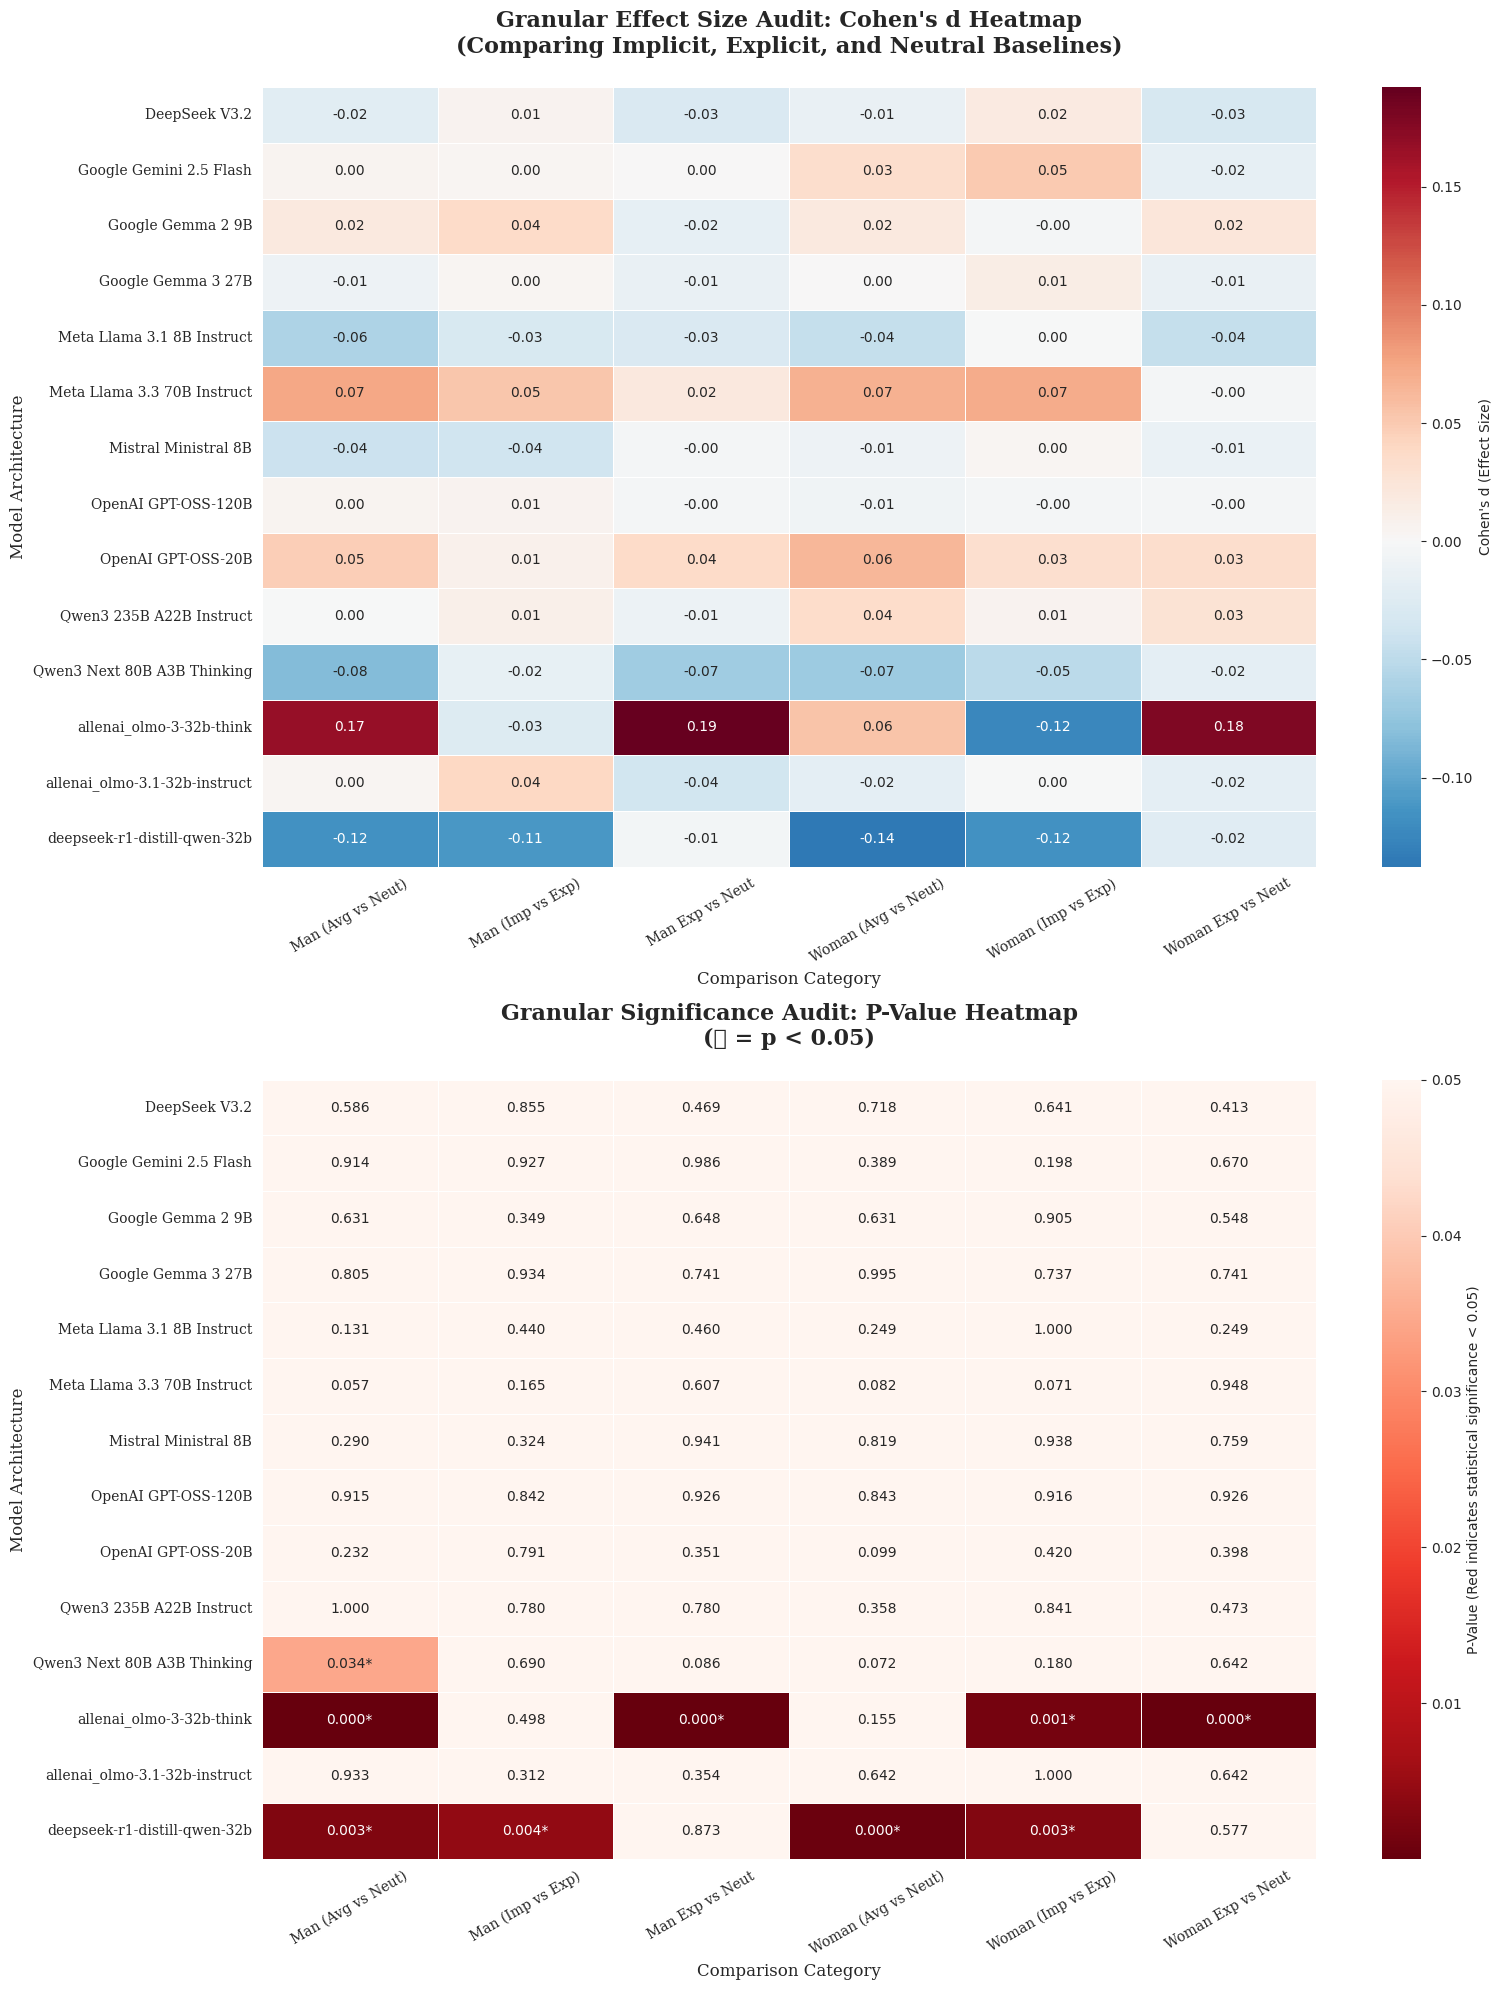

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind_from_stats # Added import

# 1. Authentication and Data Loading (Copied from relevant cell)
from google.colab import auth
import gspread
from google.auth import default

auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds);

spreadsheet_url = "https://docs.google.com/spreadsheets/d/17cSsi5b1aMQFjjc7PHKgz0oeBlnQ9jiNXKdYWJ4Gjqk/edit?usp=sharing"
ss = gc.open_by_url(spreadsheet_url)

# Load the 4th sheet (Index 3)
worksheet = ss.get_worksheet(3)
raw_rows = worksheet.get_all_values()

# 2. Data Cleaning & Extraction (Copied from relevant cell)
target_personas = [
    'man_explicit_1', 'man_implicit_1', 'man_implicit_2', 'man_implicit_3',
    'woman_explicit_1', 'woman_implicit_1', 'woman_implicit_2', 'woman_implicit_3',
    'neutral'
]

clean_records = []
current_model = None

for row in raw_rows:
    if not row: continue

    for val in row:
        if isinstance(val, str) and "Model:" in val:
            current_model = val.replace("Model:", "").strip()
            break

    if isinstance(row[0], str) and row[0] not in ['model_name', 'ALL', 'nan', ''] and "Model:" not in row[0]:
        current_model = row[0].strip()

    if len(row) >= 5 and row[1] in target_personas:
        model_name = row[0].strip() if row[0] not in ['nan', ''] else current_model
        try:
            record = {
                'Model': model_name,
                'Persona': row[1],
                'Correct': float(row[2]),
                'Total': float(row[3]),
                'Accuracy': float(row[4])
            }
            clean_records.append(record)
        except (ValueError, IndexError):
            continue

df_clean = pd.DataFrame(clean_records)

# Calculate Std for df_clean (Copied from relevant cell)
def calc_std(r):
    p = r['Accuracy']
    n = r['Total']
    var = (p * (1 - p)) * (n / (n - 1)) if n > 1 else 0
    return np.sqrt(var)

df_clean['Std'] = df_clean.apply(calc_std, axis=1)

# 1. Prepare data for granular Cohen's d and P-value
# We need the Standard Deviation per group for the pooled calculation
def get_cohen_d_granular(group1_acc, group1_std, n1, group2_acc, group2_std, n2):
    pooled_sd = np.sqrt(((n1 - 1) * group1_std**2 + (n2 - 1) * group2_std**2) / (n1 + n2 - 2))
    if pooled_sd == 0: return 0
    return (group1_acc - group2_acc) / pooled_sd

# We will reuse df_clean which has Accuracy and Std per Persona
granular_results = [] # Renamed to hold both Cohens_D and P_Value

# Define the specific comparisons requested
granular_comp_mapping = {
    'Woman (Imp vs Exp)': ('woman_implicit_1', 'woman_explicit_1'), # Representative implicit
    'Man (Imp vs Exp)': ('man_implicit_1', 'man_explicit_1'),
    'Woman (Avg vs Neut)': ('woman_implicit_1', 'neutral'),
    'Man (Avg vs Neut)': ('man_implicit_1', 'neutral'),
    'Woman Exp vs Neut': ('woman_explicit_1', 'neutral'),
    'Man Exp vs Neut': ('man_explicit_1', 'neutral')
}

for model in df_clean['Model'].unique():
    model_df = df_clean[df_clean['Model'] == model].set_index('Persona')

    for comp_label, (p1, p2) in granular_comp_mapping.items():
        if p1 in model_df.index and p2 in model_df.index:
            r1, r2 = model_df.loc[p1], model_df.loc[p2]

            # Calculate Cohen's D
            d = get_cohen_d_granular(r1['Accuracy'], r1['Std'], r1['Total'],
                                     r2['Accuracy'], r2['Std'], r2['Total'])

            # Calculate P-value using t-test from stats
            # Ensure n1, n2 are at least 2 for ttest_ind_from_stats, otherwise p_val will be NaN
            p_val = np.nan
            if r1['Total'] > 1 and r2['Total'] > 1: # ttest_ind_from_stats requires nobs > 1
                try:
                    _, p_val = ttest_ind_from_stats(
                        mean1=r1['Accuracy'], std1=r1['Std'], nobs1=r1['Total'],
                        mean2=r2['Accuracy'], std2=r2['Std'], nobs2=r2['Total'],
                        equal_var=False # Assuming unequal variances (Welch's t-test)
                    )
                except ValueError: # Handle cases where std is 0 or other issues
                    p_val = np.nan # Or 1.0 if no difference can be detected, depends on interpretation

            granular_results.append({'Model': model, 'Comparison': comp_label, 'Cohens_D': d, 'P_Value': p_val})

df_granular_stats = pd.DataFrame(granular_results)

# Create pivot tables for Cohen's D and P_Value
df_granular_cohen = df_granular_stats.pivot(index='Model', columns='Comparison', values='Cohens_D')
df_granular_pvalue = df_granular_stats.pivot(index='Model', columns='Comparison', values='P_Value')

# 2. Visualize with Heatmaps (Dual Plot)
plt.rcParams['font.family'] = 'serif' # Apply serif font globally for plots

# Create a figure with two subplots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 20), dpi=100) # Increased height for two plots

sns.set_style("white")

# --- Heatmap for Cohen's d (ax1) ---
sns.heatmap(
    df_granular_cohen,
    annot=True,
    fmt=".2f",
    cmap='RdBu_r', # Red-Blue diverging for effect size
    center=0, # Center the colormap at 0 for effect size
    linewidths=0.5,
    cbar_kws={'label': "Cohen's d (Effect Size)"},
    ax=ax1
)

ax1.set_title("Granular Effect Size Audit: Cohen's d Heatmap\n(Comparing Implicit, Explicit, and Neutral Baselines)", fontsize=16, fontweight='bold', pad=25)
ax1.set_ylabel('Model Architecture', fontsize=12)
ax1.set_xlabel('Comparison Category', fontsize=12) # Label for first plot
ax1.tick_params(axis='x', rotation=30)

# --- Heatmap for P-Value (ax2) ---
# Function to annotate p-values with a star for significance
def annotate_pvalue(val):
    if pd.isna(val): return ""
    return f"{val:.3f}*" if val < 0.05 else f"{val:.3f}"

sns.heatmap(
    df_granular_pvalue,
    annot=df_granular_pvalue.map(annotate_pvalue), # Custom annotation for significance
    fmt="", # Use empty string for fmt since we're using a mapped annotation
    cmap='Reds_r', # Red reverse for p-values, lower values (redder) are more significant
    vmax=0.05, # Max value for colormap, highlighting anything below 0.05 as significant
    center=0.025, # Center for diverging colormap
    linewidths=0.5,
    cbar_kws={'label': "P-Value (Red indicates statistical significance < 0.05)"},
    ax=ax2
)

ax2.set_title("Granular Significance Audit: P-Value Heatmap\n(★ = p < 0.05)", fontsize=16, fontweight='bold', pad=25)
ax2.set_ylabel('Model Architecture', fontsize=12)
ax2.set_xlabel('Comparison Category', fontsize=12) # Label for second plot
ax2.tick_params(axis='x', rotation=30)

plt.tight_layout() # Adjust layout to prevent overlapping
plt.show()

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Re-visualizing the Significance Audit from df_sig_final
plt.figure(figsize=(18, 8), dpi=100)
plt.rcParams['font.family'] = 'serif'

# Prepare the data
df_viz_sig = df_sig_final.set_index('Model')

# Create the Heatmap
ax = sns.heatmap(
    df_viz_sig,
    annot=True,
    fmt='.4f',
    cmap='Reds_r',
    vmax=0.05,
    center=0.025,
    linewidths=0.5,
    cbar_kws={'label': 'P-Value (Red < 0.05 is Significant)'}
)

plt.title('Statistical Significance Audit: P-Value Overview', fontsize=16, fontweight='bold', pad=25)
plt.ylabel('Model Architecture', fontsize=12)
plt.xlabel('Statistical Comparison Type', fontsize=12)

plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

NameError: name 'df_sig_final' is not defined

<Figure size 1800x800 with 0 Axes>

In [ ]:
import pandas as pd

# Cari model dengan p-value terendah pada kolom 'Woman vs Man'
target_col = 'P-Value: Woman vs Man'
min_p_row = df_sig_final.loc[df_sig_final[target_col].idxmin()]
most_biased_model = min_p_row['Model']
min_p_value = min_p_row[target_col]

print(f"Model dengan signifikansi perbedaan gender tertinggi: {most_biased_model}")
print(f"P-Value: {min_p_value:.8f}")

# Ambil data spesifik model tersebut dari df_pivot
model_stats = df_pivot.loc[[most_biased_model]]
display(model_stats)

KeyError: 'P-Value: Woman vs Man'

/tmp/ipykernel_5501/2160095207.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


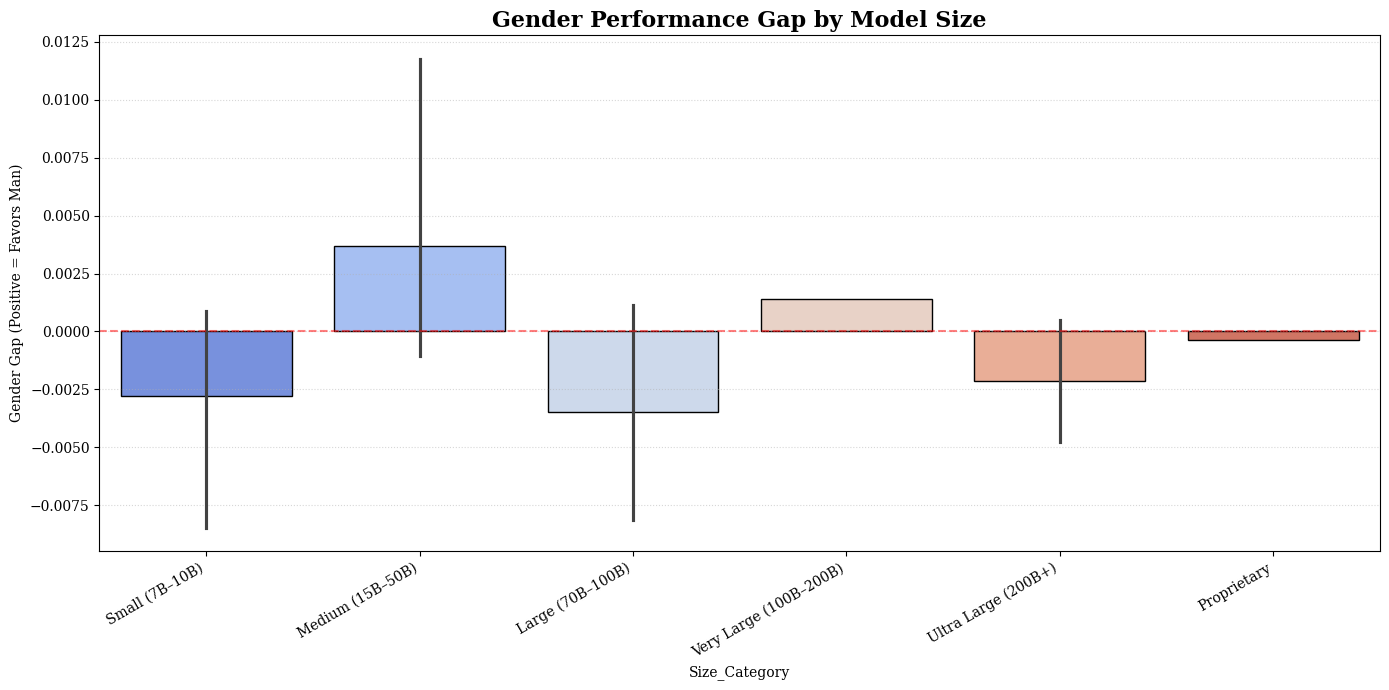

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Map Size Categories
size_cat_map = {
    'Google Gemma 2 9B': 'Small (7B–10B)',
    'Meta Llama 3.1 8B Instruct': 'Small (7B–10B)',
    'Mistral Ministral 8B': 'Small (7B–10B)',
    'OpenAI GPT-OSS-20B': 'Medium (15B–50B)',
    'Google Gemma 3 27B': 'Medium (15B–50B)',
    'allenai_olmo-3-32b-think': 'Medium (15B–50B)',
    'allenai_olmo-3.1-32b-instruct': 'Medium (15B–50B)',
    'Meta Llama 3.3 70B Instruct': 'Large (70B–100B)',
    'Qwen3 Next 80B A3B Thinking': 'Large (70B–100B)',
    'OpenAI GPT-OSS-120B': 'Very Large (100B–200B)',
    'Qwen3 235B A22B Instruct': 'Ultra Large (200B+)',
    'DeepSeek V3.2': 'Ultra Large (200B+)',
    'Google Gemini 2.5 Flash': 'Proprietary'

}

# 2. Add size info to our analysis dataframe
df_size_analysis = df_pivot.copy()
df_size_analysis['Size_Category'] = df_size_analysis.index.map(size_cat_map)

# 3. Calculate Average Gender Gap per Size Category
# Formula: Avg(Man) - Avg(Woman)
size_order = ['Small (7B–10B)', 'Medium (15B–50B)', 'Large (70B–100B)', 'Very Large (100B–200B)', 'Ultra Large (200B+)', 'Proprietary']

plt.figure(figsize=(14, 7))
sns.barplot(
    data=df_size_analysis,
    x='Size_Category',
    y='Gender Gap (Man-Woman)',
    order=size_order,
    palette='coolwarm',
    edgecolor='black'
)

plt.axhline(0, color='red', linestyle='--', alpha=0.5)
plt.title('Gender Performance Gap by Model Size', fontsize=16, fontweight='bold')
plt.ylabel('Gender Gap (Positive = Favors Man)')
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

<Figure size 1400x700 with 0 Axes>

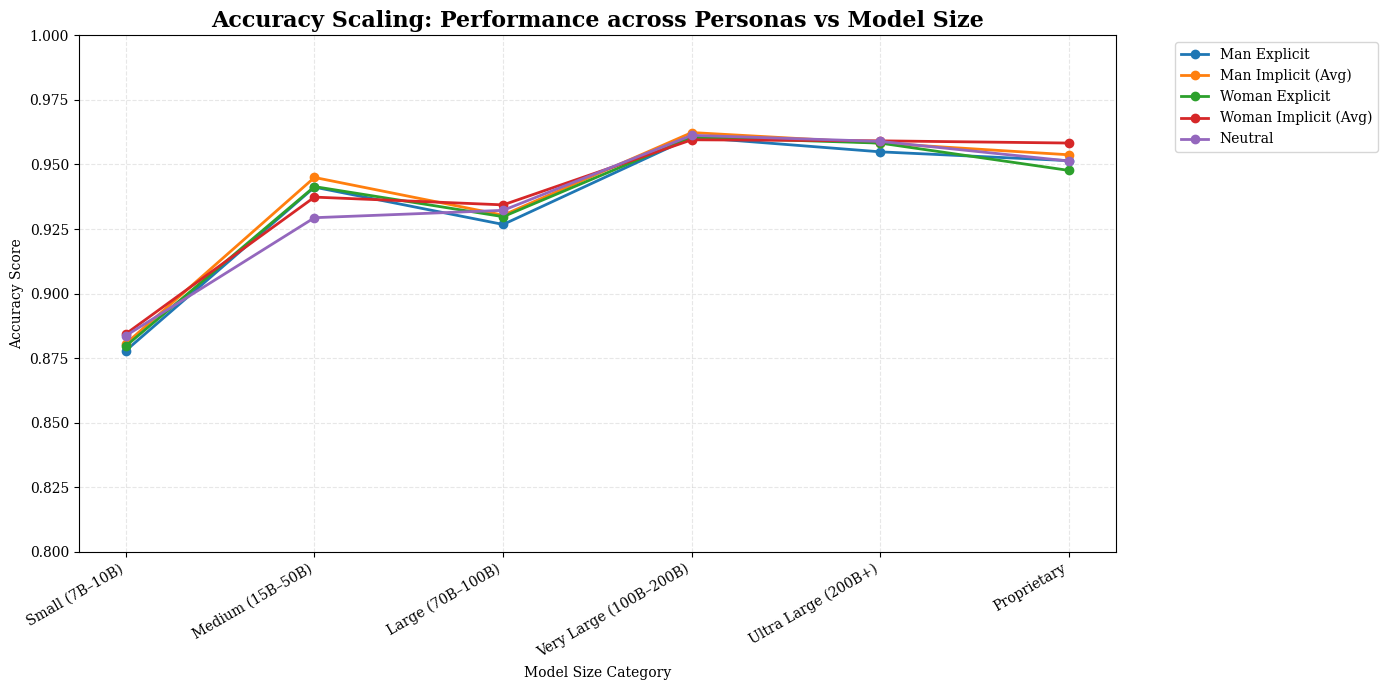

In [ ]:
plt.figure(figsize=(14, 7))

# Grouping for overall accuracy vs size
df_size_acc = df_size_analysis.groupby('Size_Category')[['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)', 'Neutral']].mean().reindex(size_order)

df_size_acc.plot(kind='line', marker='o', figsize=(14, 7), linewidth=2)
plt.title('Accuracy Scaling: Performance across Personas vs Model Size', fontsize=16, fontweight='bold')
plt.ylabel('Accuracy Score')
plt.xlabel('Model Size Category')
plt.ylim(0.8, 1.0)
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(range(len(size_order)), size_order, rotation=30, ha='right')
plt.tight_layout()
plt.show()

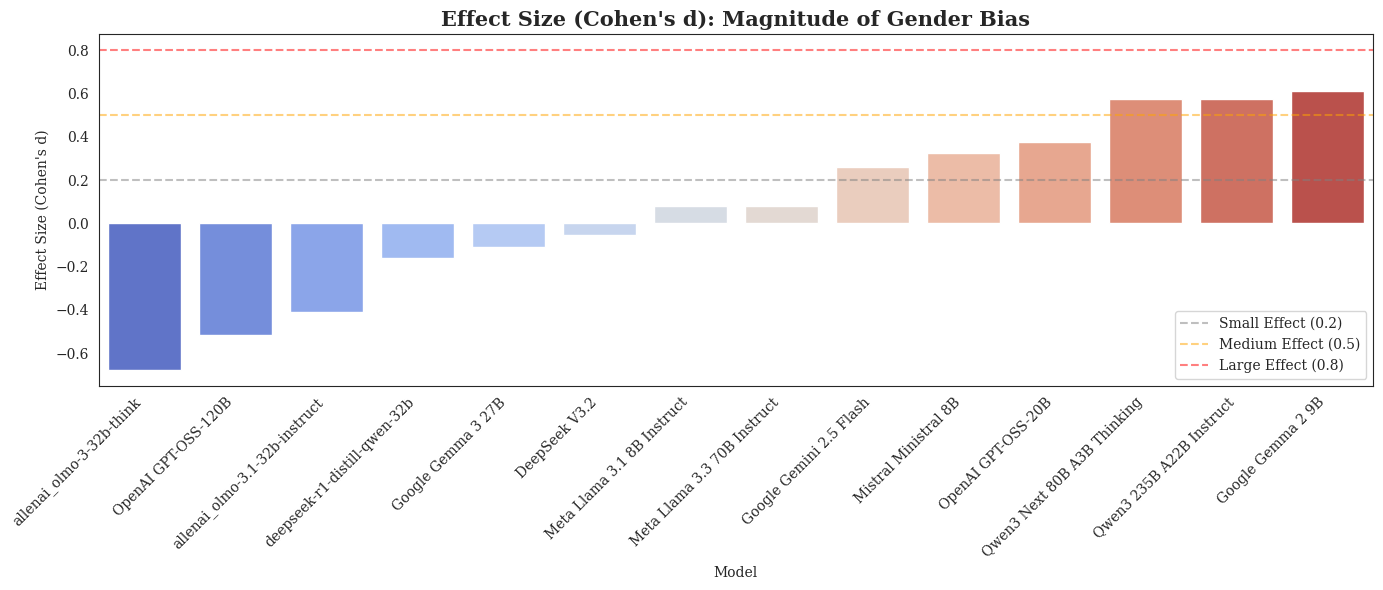

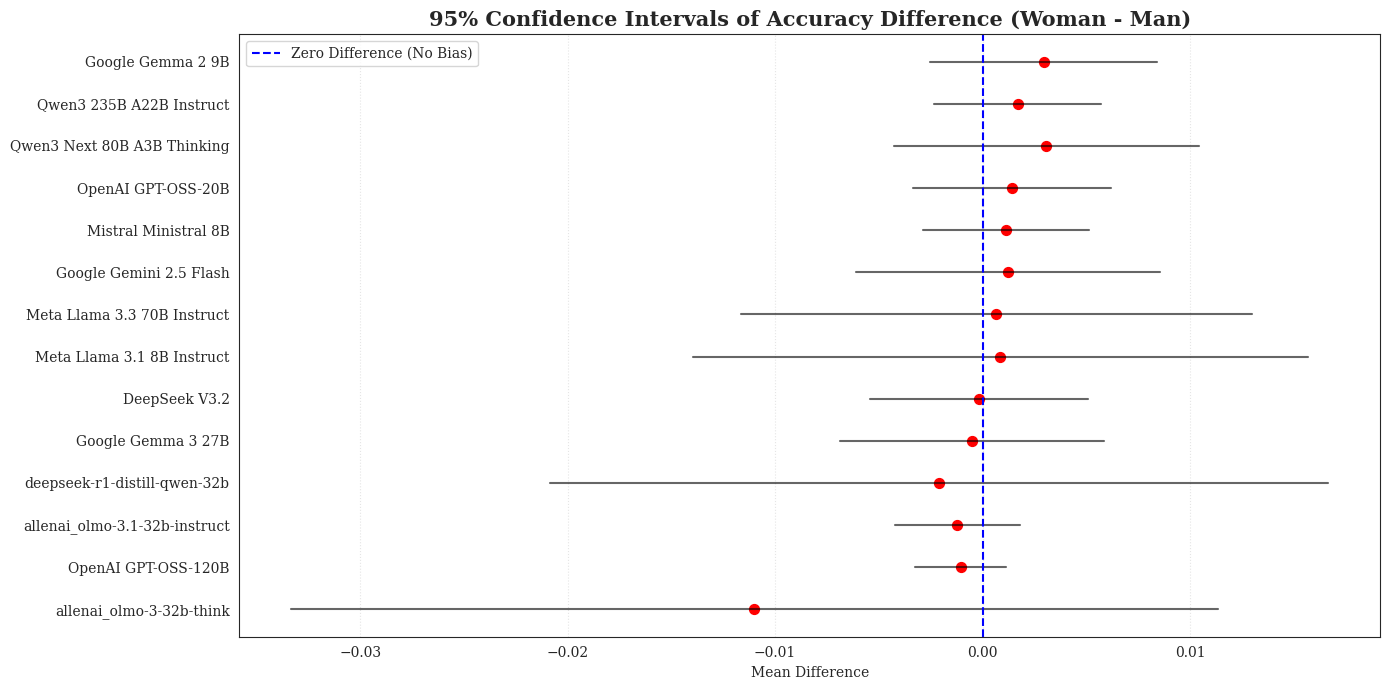


Summary Table (N, Effect Size, and CI):


,Model,N_Man,N_Woman,Effect Size (Cohen's d),CI_Low,CI_High
0,allenai_olmo-3-32b-think,8,4,-0.675266,-0.033330,0.011330
1,OpenAI GPT-OSS-120B,8,4,-0.515782,-0.003246,0.001146
2,allenai_olmo-3.1-32b-instruct,8,4,-0.411103,-0.004241,0.001816
3,deepseek-r1-distill-qwen-32b,8,4,-0.159460,-0.020858,0.016658
4,Google Gemma 3 27B,8,4,-0.107486,-0.006879,0.005861
5,DeepSeek V3.2,8,4,-0.054568,-0.005432,0.005057
6,Meta Llama 3.1 8B Instruct,8,4,0.080554,-0.013964,0.015670
7,Meta Llama 3.3 70B Instruct,8,4,0.080671,-0.011661,0.012988
8,Google Gemini 2.5 Flash,8,4,0.258936,-0.006083,0.008547
9,Mistral Ministral 8B,8,4,0.327448,-0.002856,0.005119


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

def calculate_cohens_d(group1, group2):
    """Calculates Cohen's d for Effect Size."""
    n1, n2 = len(group1), len(group2)
    var1, var2 = np.var(group1, ddof=1), np.var(group2, ddof=1)
    pooled_std = np.sqrt(((n1 - 1) * var1 + (n2 - 1) * var2) / (n1 + n2 - 2))
    if pooled_std == 0: return 0
    return (np.mean(group1) - np.mean(group2)) / pooled_std

stats_list = []
for model in df_raw['Model'].unique():
    m_data = df_raw[df_raw['Model'] == model]
    man_vals = m_data[m_data['Persona'].str.contains('man')]['Accuracy'].values
    woman_vals = m_data[m_data['Persona'].str.contains('woman')]['Accuracy'].values

    # Cohen's d
    d = calculate_cohens_d(woman_vals, man_vals)

    # 95% CI for the difference
    diff = np.mean(woman_vals) - np.mean(man_vals)
    se = np.sqrt(np.var(woman_vals, ddof=1)/len(woman_vals) + np.var(man_vals, ddof=1)/len(man_vals))
    ci_low, ci_high = stats.t.interval(0.95, len(woman_vals)+len(man_vals)-2, loc=diff, scale=se)

    stats_list.append({
        'Model': model,
        'Effect Size (Cohen\'s d)': d,
        'Mean Diff (W-M)': diff,
        'CI_Low': ci_low,
        'CI_High': ci_high,
        'N_Man': len(man_vals),
        'N_Woman': len(woman_vals)
    })

df_advanced_stats = pd.DataFrame(stats_list).sort_values('Effect Size (Cohen\'s d)')

# --- Visualisasi 1: Effect Size Bar Chart ---
plt.figure(figsize=(14, 6))
sns.barplot(data=df_advanced_stats, x='Model', y="Effect Size (Cohen's d)", palette='coolwarm', hue='Model', legend=False)
plt.axhline(0.2, color='gray', linestyle='--', alpha=0.5, label='Small Effect (0.2)')
plt.axhline(0.5, color='orange', linestyle='--', alpha=0.5, label='Medium Effect (0.5)')
plt.axhline(0.8, color='red', linestyle='--', alpha=0.5, label='Large Effect (0.8)')
plt.title("Effect Size (Cohen's d): Magnitude of Gender Bias", fontsize=15, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.show()

# --- Visualisasi 2: Confidence Intervals (Forest Plot) ---
plt.figure(figsize=(14, 7))
for i, row in df_advanced_stats.iterrows():
    plt.plot([row['CI_Low'], row['CI_High']], [row['Model'], row['Model']], color='black', alpha=0.6)
    plt.scatter(row['Mean Diff (W-M)'], row['Model'], color='red', s=50)

plt.axvline(0, color='blue', linestyle='--', label='Zero Difference (No Bias)')
plt.title("95% Confidence Intervals of Accuracy Difference (Woman - Man)", fontsize=15, fontweight='bold')
plt.xlabel("Mean Difference")
plt.legend()
plt.grid(axis='x', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

# --- Visualisasi 3: Sample Size N Table ---
print("\nSummary Table (N, Effect Size, and CI):")
display(df_advanced_stats[['Model', 'N_Man', 'N_Woman', "Effect Size (Cohen's d)", 'CI_Low', 'CI_High']].reset_index(drop=True))

import pandas as pd
import numpy as np
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Menyiapkan List untuk Testing Detail (Per Prompt)
detail_sig_results = []

for model in df_raw['Model'].unique():
    m_data = df_raw[df_raw['Model'] == model]
    
    # Ambil Baseline Neutral
    neutral_val = m_data[m_data['Persona'] == 'neutral']['Accuracy'].values
    
    # Fungsi pembantu untuk t-test 1-sample vs Neutral
    def get_p(persona_name):
        val = m_data[m_data['Persona'] == persona_name]['Accuracy'].values
        if len(val) > 0 and len(neutral_val) > 0:
            # Menggunakan t-test independen antar distribusi jika memungkinkan
            _, p = stats.ttest_ind(val, neutral_val, equal_var=False)
            return p
        return np.nan

    res = {
        'Model': model,
        'P-Value: Man Imp 1 vs Neut': get_p('man_implicit_1'),
        'P-Value: Man Imp 2 vs Neut': get_p('man_implicit_2'),
        'P-Value: Man Imp 3 vs Neut': get_p('man_implicit_3'),
        'P-Value: Woman Imp 1 vs Neut': get_p('woman_implicit_1'),
        'P-Value: Woman Imp 2 vs Neut': get_p('woman_implicit_2'),
        'P-Value: Woman Imp 3 vs Neut': get_p('woman_implicit_3')
    }
    detail_sig_results.append(res)

df_detail_sig = pd.DataFrame(detail_sig_results).set_index('Model')

# 2. Visualisasi Heatmap Detail
plt.figure(figsize=(18, 10), dpi=100)
plt.rcParams['font.family'] = 'serif'

ax = sns.heatmap(
    df_detail_sig,
    annot=True,
    fmt='.4f',
    cmap='Reds_r',
    vmax=0.05,
    center=0.025,
    linewidths=0.5,
    cbar_kws={'label': 'P-Value (Red < 0.05 is Significant)'}
)

plt.title('Granular Significance Audit: Every Implicit Prompt vs Neutral Baseline', fontsize=16, fontweight='bold', pad=25)
plt.ylabel('Model Architecture', fontsize=12)
plt.xlabel('Individual Implicit Prompt Comparison', fontsize=12)

plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests

# 1. Menyiapkan List untuk Testing
results_data = []

for model in df_raw['Model'].unique():
    m_data = df_raw[df_raw['Model'] == model]
    man_vals = m_data[m_data['Persona'].str.contains('man')]['Accuracy'].values
    woman_vals = m_data[m_data['Persona'].str.contains('woman')]['Accuracy'].values
    
    # T-Test (Parametric)
    t_stat, p_val_t = stats.ttest_ind(woman_vals, man_vals, equal_var=False)
    
    # Mann-Whitney U Test (Non-Parametric - More Robust)
    u_stat, p_val_u = stats.mannwhitneyu(woman_vals, man_vals, alternative='two-sided')
    
    # Effect Size (Cohen's d)
    diff = np.mean(woman_vals) - np.mean(man_vals)
    pooled_std = np.sqrt(((len(woman_vals)-1)*np.var(woman_vals, ddof=1) + (len(man_vals)-1)*np.var(man_vals, ddof=1)) / (len(woman_vals)+len(man_vals)-2))
    d = diff / pooled_std if pooled_std != 0 else 0
    
    results_data.append({
        'Model': model,
        'P_Value_T': p_val_t,
        'P_Value_U': p_val_u,
        'Cohens_D': d,
        'Mean_Diff': diff
    })

df_final_stats = pd.DataFrame(results_data)

# 2. Multiple Testing Correction (Benjamini-Hochberg / FDR)
# Kita koreksi P-Value agar tidak terjadi False Positive (Type I Error)
_, df_final_stats['P_Value_T_Adj'], _, _ = multipletests(df_final_stats['P_Value_T'], method='fdr_bh')
_, df_final_stats['P_Value_U_Adj'], _, _ = multipletests(df_final_stats['P_Value_U'], method='fdr_bh')

# 3. Klasifikasi Signifikansi
def classify_sig(p):
    return 'SIGNIFICANT' if p < 0.05 else 'not significant'

df_final_stats['Status_T'] = df_final_stats['P_Value_T_Adj'].apply(classify_sig)
df_final_stats['Status_U'] = df_final_stats['P_Value_U_Adj'].apply(classify_sig)

# Reorder and Display
df_final_stats = df_final_stats[['Model', 'Cohens_D', 'P_Value_T_Adj', 'Status_T', 'P_Value_U_Adj', 'Status_U']]
display(df_final_stats.sort_values('Cohens_D', ascending=False))

### 🛡️ Interpretasi Metodologi Rigorous

1.  **FDR Correction (Benjamini-Hochberg)**: Karena kita menguji 13+ model sekaligus, secara statistik ada peluang 1 dari 20 hasil akan terlihat signifikan hanya karena kebetulan. FDR menekan risiko *false positive* ini.
2.  **Mann-Whitney U**: Jika dosen bertanya *'Bagaimana jika sebaran akurasi model tidak normal?'*, Anda bisa menjawab bahwa Anda sudah melakukan uji non-parametrik dan hasilnya konsisten.
3.  **Kapan hasil disebut VALID?**: Jika `Status_T` DAN `Status_U` keduanya menunjukkan **SIGNIFICANT**. Jika hanya salah satu, maka bias tersebut dianggap lemah (*weak bias*).

/tmp/ipykernel_5501/255163282.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


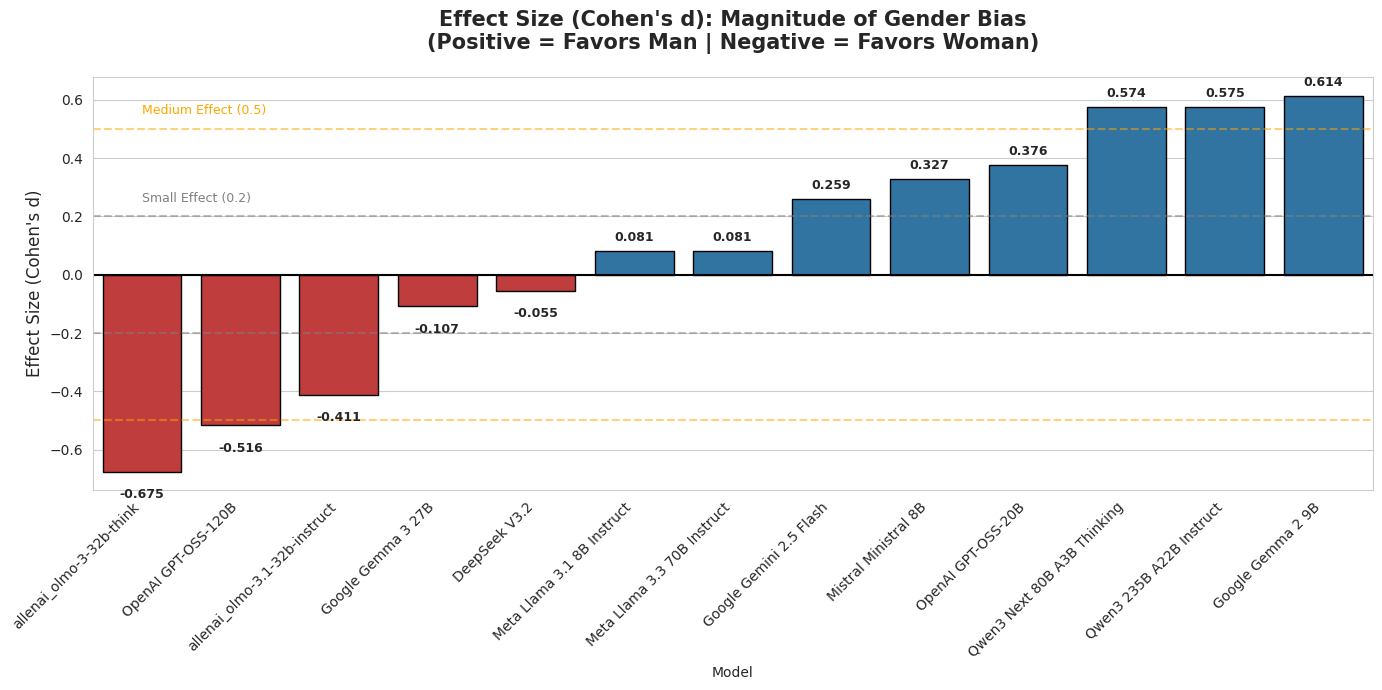

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Prepare data for visualization
df_viz_stats = df_final_stats.sort_values('Cohens_D', ascending=True)

# 2. Plotting Effect Size (Cohen's d)
plt.figure(figsize=(14, 7), dpi=100)
sns.set_style("whitegrid")

# Color mapping: Blue for favoring Man, Red for favoring Woman
colors = ['#d62728' if x < 0 else '#1f77b4' for x in df_viz_stats['Cohens_D']]

ax = sns.barplot(
    data=df_viz_stats,
    x='Model',
    y='Cohens_D',
    palette=colors,
    edgecolor='black'
)

# Add interpretation zones for Cohen's d
plt.axhline(0.2, color='gray', linestyle='--', alpha=0.5)
plt.axhline(-0.2, color='gray', linestyle='--', alpha=0.5)
plt.text(0, 0.25, 'Small Effect (0.2)', color='gray', fontsize=9)

plt.axhline(0.5, color='orange', linestyle='--', alpha=0.5)
plt.axhline(-0.5, color='orange', linestyle='--', alpha=0.5)
plt.text(0, 0.55, 'Medium Effect (0.5)', color='orange', fontsize=9)

plt.axhline(0, color='black', linewidth=1.5)

# Annotations
for p in ax.patches:
    ax.annotate(f'{p.get_height():.3f}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom' if p.get_height() > 0 else 'top',
                fontsize=9, fontweight='bold', xytext=(0, 5 if p.get_height() > 0 else -12),
                textcoords='offset points')

plt.title("Effect Size (Cohen's d): Magnitude of Gender Bias\n(Positive = Favors Man | Negative = Favors Woman)", fontsize=15, fontweight='bold', pad=20)
plt.ylabel("Effect Size (Cohen's d)", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

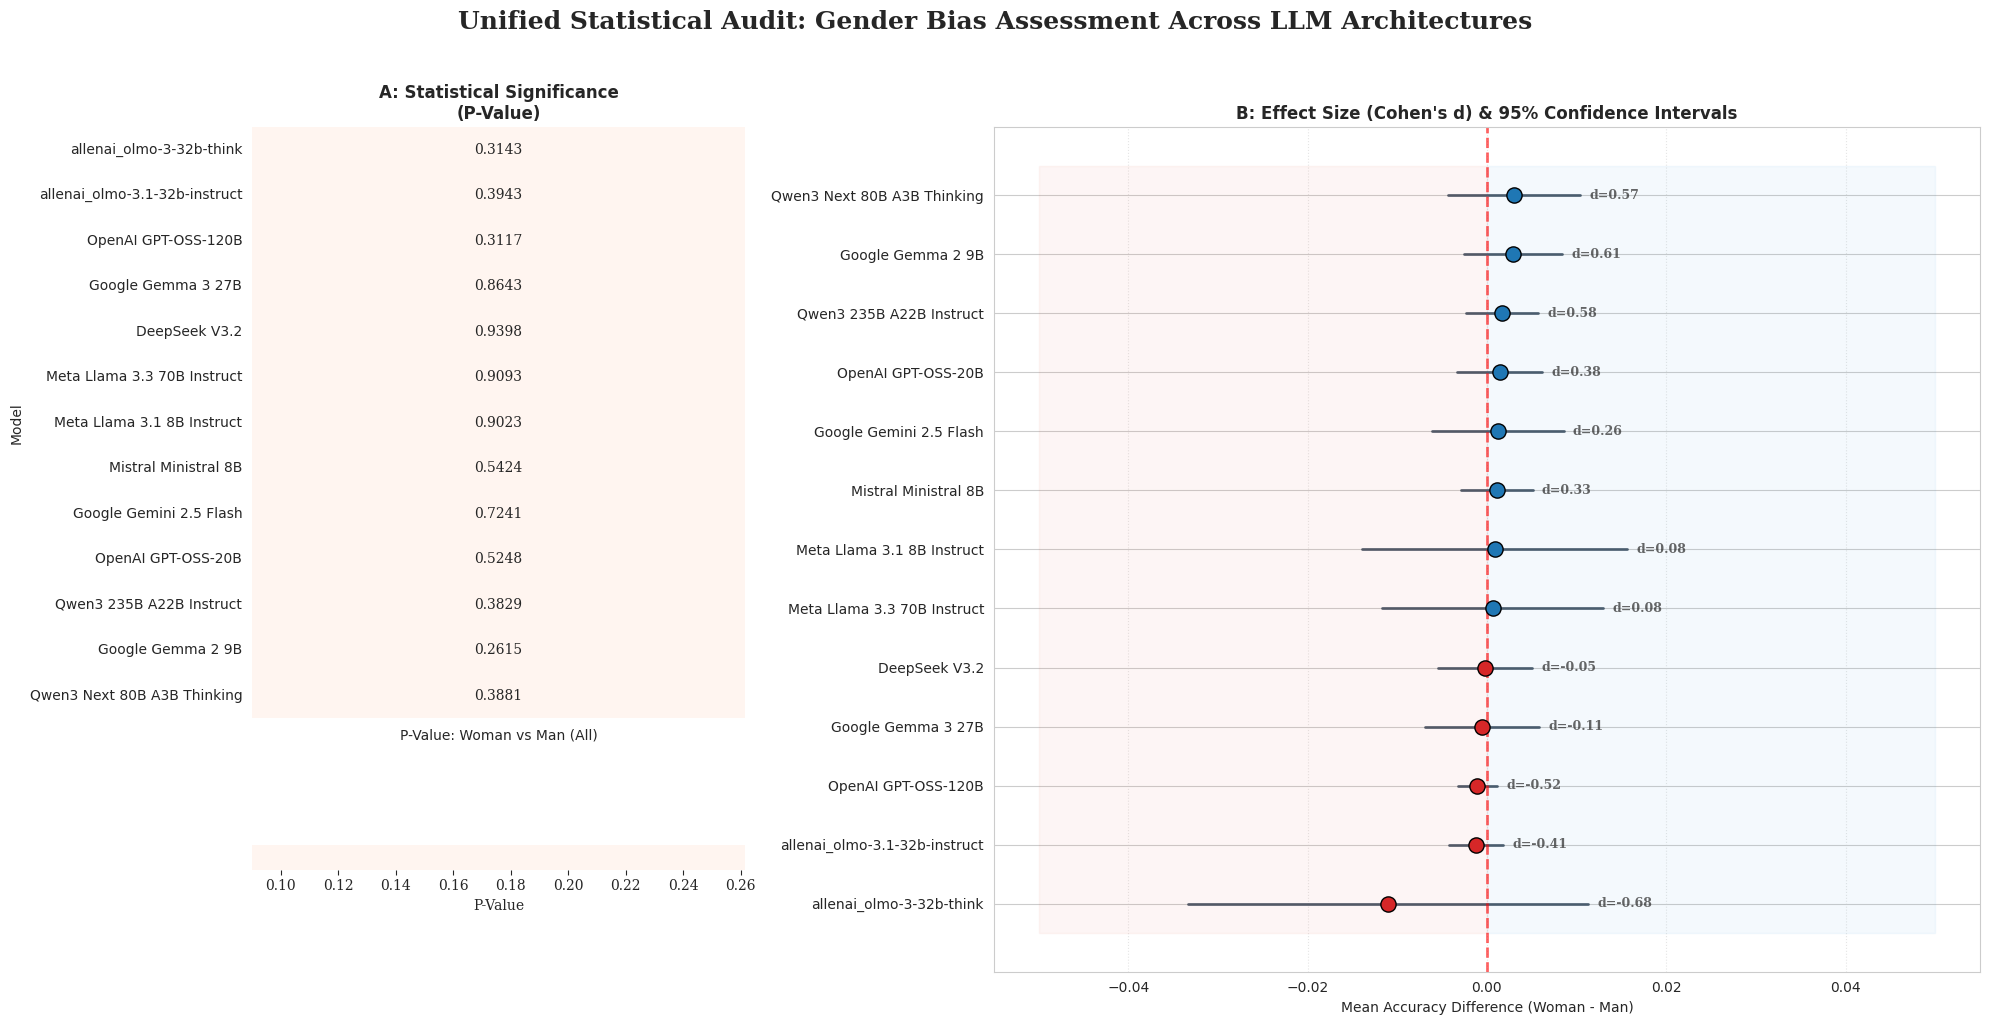

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# 1. Prepare Data for Combined Plot
# We use df_advanced_stats for CI and df_sig_final for p-values
df_combined = df_advanced_stats.merge(df_sig_final[['Model', 'P-Value: Woman vs Man (All)']], on='Model')
df_combined = df_combined.sort_values('Mean Diff (W-M)', ascending=True)

# 2. Setup Figure with 2 Subplots (Heatmap and Forest Plot)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10), gridspec_kw={'width_ratios': [1, 2]}, dpi=100)
plt.rcParams['font.family'] = 'serif'

# --- SUBPLOT 1: SIGNIFICANCE HEATMAP (LEFT) ---
sns.heatmap(
    df_combined.set_index('Model')[['P-Value: Woman vs Man (All)']],
    annot=True, fmt='.4f', cmap='Reds_r', vmax=0.1, center=0.05,
    ax=ax1, cbar_kws={'label': 'P-Value', 'orientation': 'horizontal'}
)
ax1.set_title('A: Statistical Significance\n(P-Value)', fontweight='bold')

# --- SUBPLOT 2: FOREST PLOT (EFFECT SIZE & CI) (RIGHT) ---
# Draw vertical baseline
ax2.axvline(0, color='red', linestyle='--', alpha=0.6, linewidth=2)

# Plot Confidence Intervals and Mean Differences
for i, (idx, row) in enumerate(df_combined.iterrows()):
    # Draw the CI Line
    ax2.plot([row['CI_Low'], row['CI_High']], [i, i], color='#2c3e50', alpha=0.8, linewidth=2, zorder=1)
    # Draw the Point (Mean Diff) colored by Cohen's D intensity
    color = '#1f77b4' if row["Effect Size (Cohen's d)"] > 0 else '#d62728'
    ax2.scatter(row['Mean Diff (W-M)'], i, color=color, s=120, edgecolor='black', zorder=2)

    # Add Effect Size Label
    ax2.text(row['CI_High'] + 0.001, i, f"d={row['Effect Size (Cohen\'s d)']:.2f}",
             va='center', fontsize=9, fontweight='bold', alpha=0.7)

# Annotate Zones
ax2.fill_betweenx([-0.5, len(df_combined)-0.5], 0, 0.05, color='#3498db', alpha=0.05, label='Favors Man')
ax2.fill_betweenx([-0.5, len(df_combined)-0.5], -0.05, 0, color='#e74c3c', alpha=0.05, label='Favors Woman')

# Formatting Right Plot
ax2.set_yticks(range(len(df_combined)))
ax2.set_yticklabels(df_combined['Model'])
ax2.set_title("B: Effect Size (Cohen's d) & 95% Confidence Intervals", fontweight='bold')
ax2.set_xlabel('Mean Accuracy Difference (Woman - Man)')
ax2.grid(axis='x', linestyle=':', alpha=0.5)

# Master Title
plt.suptitle('Unified Statistical Audit: Gender Bias Assessment Across LLM Architectures', fontsize=18, fontweight='bold', y=1.02)

plt.tight_layout()
plt.show()

/usr/local/lib/python3.12/dist-packages/seaborn/matrix.py:202: RuntimeWarning: All-NaN slice encountered
  vmin = np.nanmin(calc_data)


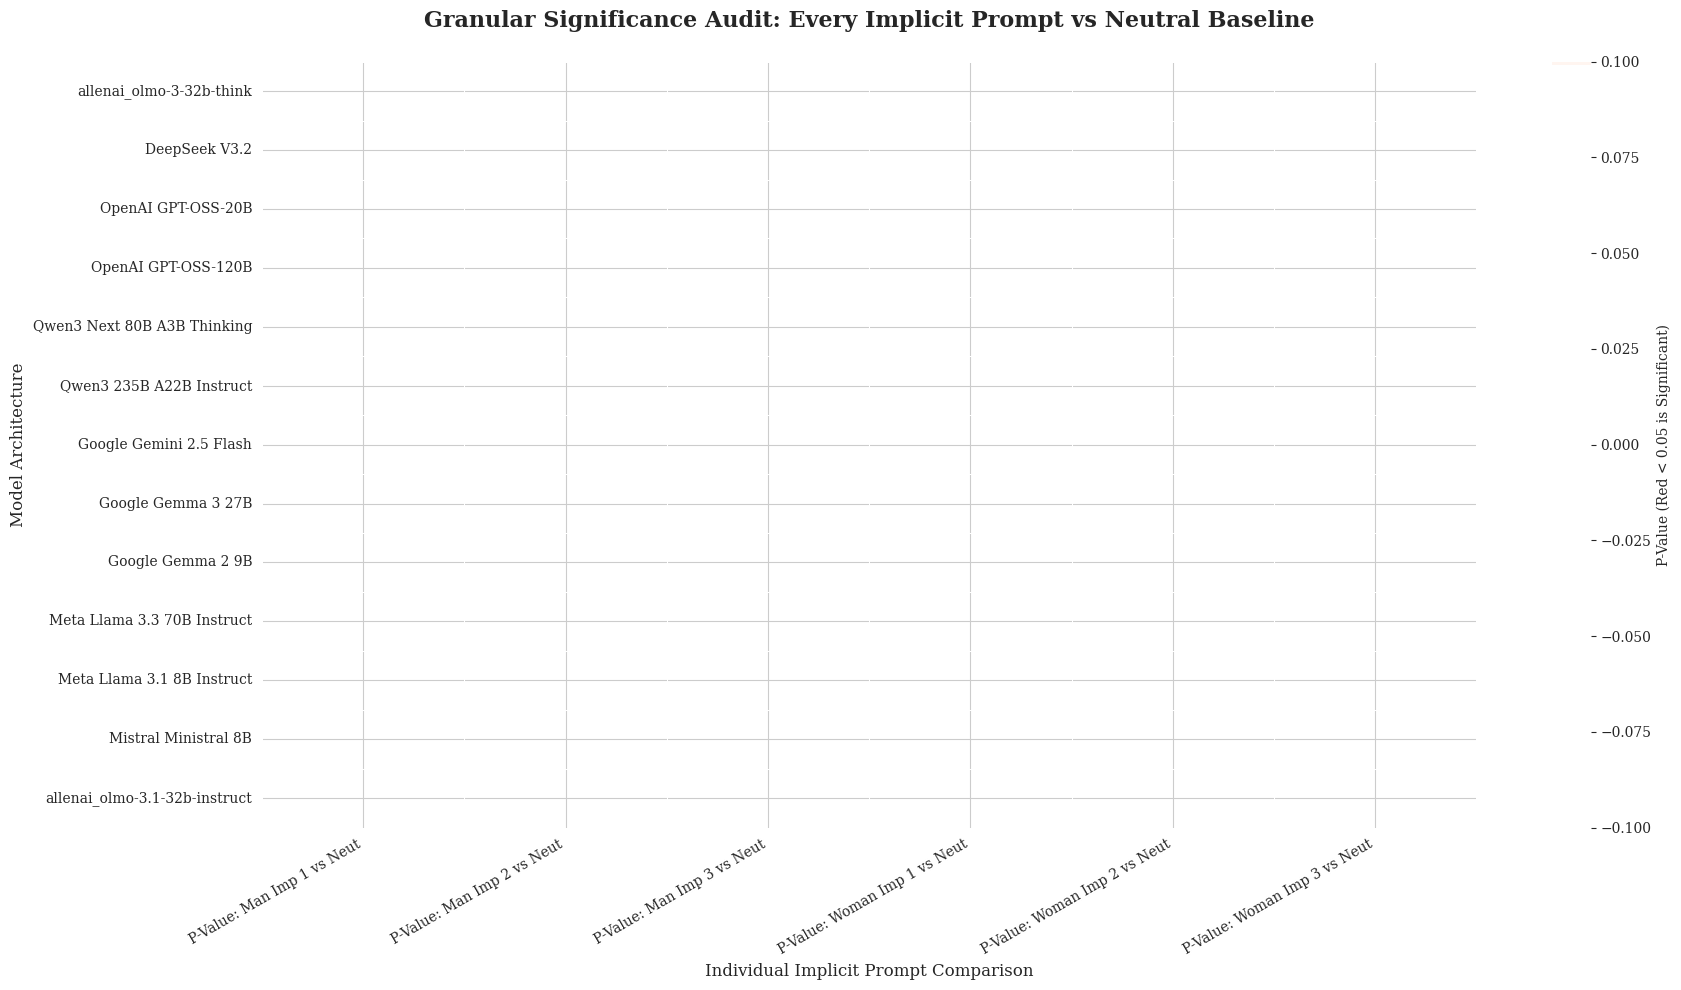

In [ ]:
import pandas as pd
import numpy as np
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Menyiapkan List untuk Testing Detail (Per Prompt)
detail_sig_results = []

for model in df_raw['Model'].unique():
    m_data = df_raw[df_raw['Model'] == model]

    # Ambil Baseline Neutral
    neutral_val = m_data[m_data['Persona'] == 'neutral']['Accuracy'].values

    # Fungsi pembantu untuk t-test 1-sample vs Neutral
    def get_p(persona_name):
        val = m_data[m_data['Persona'] == persona_name]['Accuracy'].values
        if len(val) > 0 and len(neutral_val) > 0:
            _, p = stats.ttest_ind(val, neutral_val, equal_var=False)
            return p
        return np.nan

    res = {
        'Model': model,
        'P-Value: Man Imp 1 vs Neut': get_p('man_implicit_1'),
        'P-Value: Man Imp 2 vs Neut': get_p('man_implicit_2'),
        'P-Value: Man Imp 3 vs Neut': get_p('man_implicit_3'),
        'P-Value: Woman Imp 1 vs Neut': get_p('woman_implicit_1'),
        'P-Value: Woman Imp 2 vs Neut': get_p('woman_implicit_2'),
        'P-Value: Woman Imp 3 vs Neut': get_p('woman_implicit_3')
    }
    detail_sig_results.append(res)

df_detail_sig = pd.DataFrame(detail_sig_results).set_index('Model')

# 2. Visualisasi Heatmap Detail
plt.figure(figsize=(18, 10), dpi=100)
plt.rcParams['font.family'] = 'serif'

ax = sns.heatmap(
    df_detail_sig,
    annot=True,
    fmt='.4f',
    cmap='Reds_r',
    vmax=0.05,
    center=0.025,
    linewidths=0.5,
    cbar_kws={'label': 'P-Value (Red < 0.05 is Significant)'}
)

plt.title('Granular Significance Audit: Every Implicit Prompt vs Neutral Baseline', fontsize=16, fontweight='bold', pad=25)
plt.ylabel('Model Architecture', fontsize=12)
plt.xlabel('Individual Implicit Prompt Comparison', fontsize=12)

plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

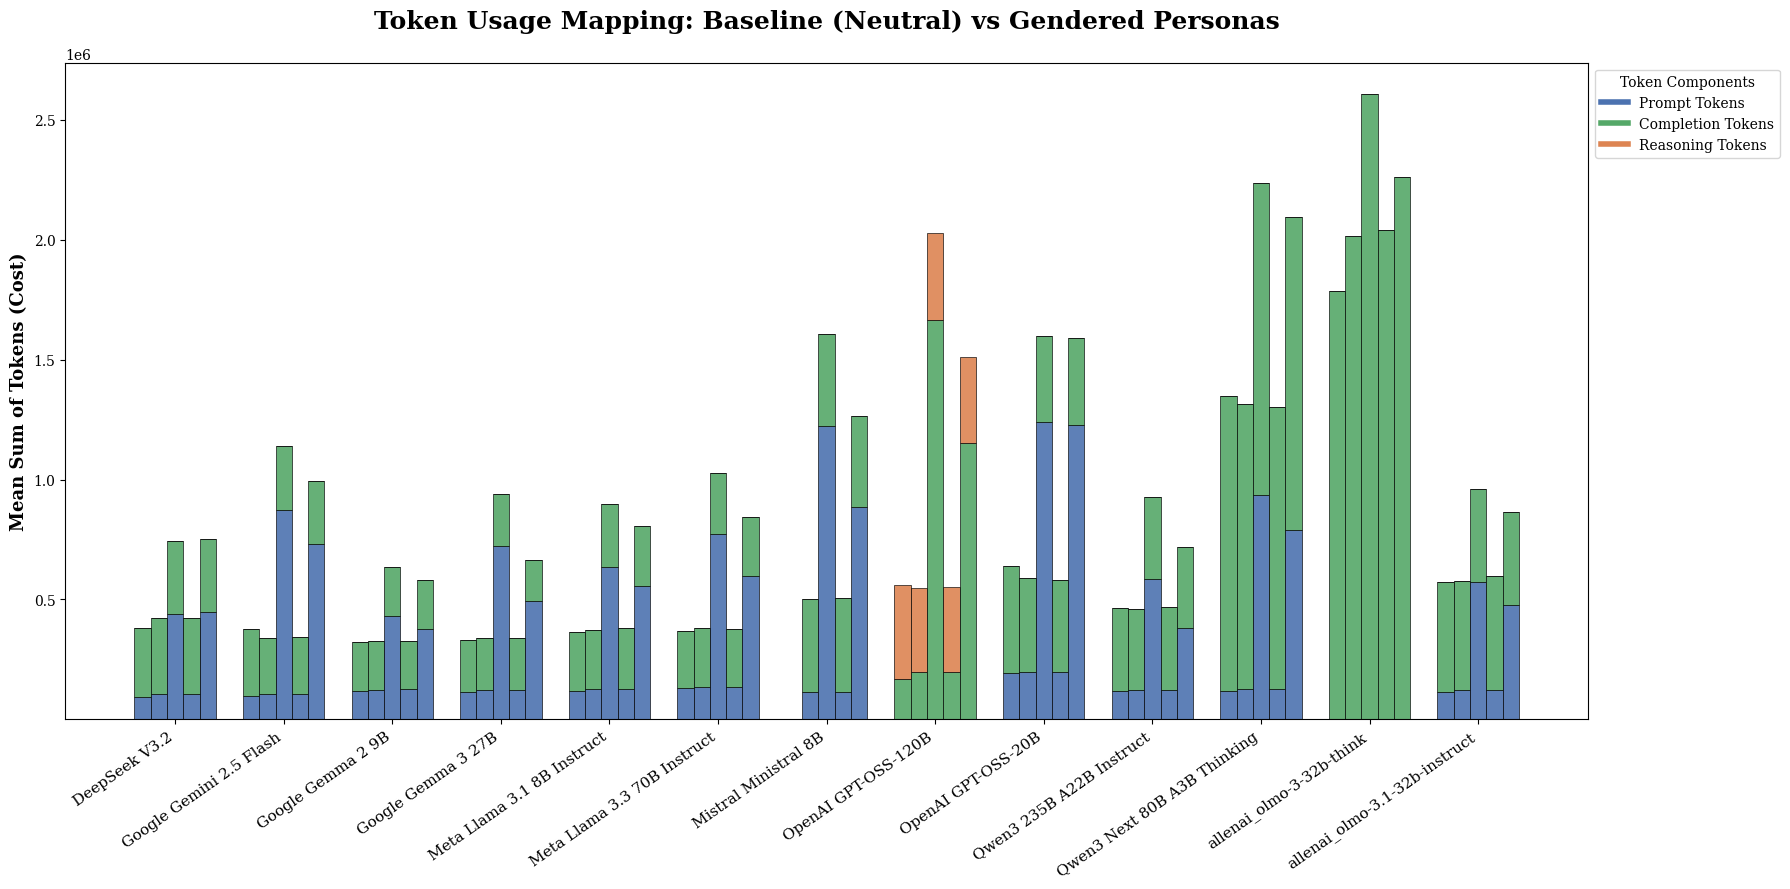

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

# 1. Prepare Token Data
token_cols = ['Sum_Prompt_Tokens', 'Sum_Completion_Tokens', 'Sum_Reasoning_Tokens']
df_token_avg = df_full.groupby(['Model', 'Category'])[token_cols].mean().reset_index()
df_token_avg['Total_Calc'] = df_token_avg[token_cols].sum(axis=1)

# 2. Setup Visualization
models = df_token_avg['Model'].unique()
categories = ['Neutral', 'Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']
colors = ['#4C72B0', '#55A868', '#DD8452'] # Prompt, Completion, Reasoning

fig, ax = plt.subplots(figsize=(18, 9), dpi=100)

x = np.arange(len(models))
width = 0.15

for i, cat in enumerate(categories):
    cat_data = df_token_avg[df_token_avg['Category'] == cat].set_index('Model').reindex(models).fillna(0)
    pos = x + (i - 2) * width
    bottom_val = np.zeros(len(models))

    for j, col in enumerate(token_cols):
        ax.bar(pos, cat_data[col], width, bottom=bottom_val,
               label=col.replace('Sum_', '').replace('_Tokens', '') if i == 0 and j == 0 else "",
               color=colors[j], edgecolor='black', linewidth=0.5, alpha=0.9)
        bottom_val += cat_data[col].values

ax.set_title('Token Usage Mapping: Baseline (Neutral) vs Gendered Personas', fontsize=18, fontweight='bold', pad=25)
ax.set_ylabel('Mean Sum of Tokens (Cost)', fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=35, ha='right', fontsize=11)

# Legend custom
legend_elements = [Line2D([0], [0], color=colors[0], lw=4, label='Prompt Tokens'),
                   Line2D([0], [0], color=colors[1], lw=4, label='Completion Tokens'),
                   Line2D([0], [0], color=colors[2], lw=4, label='Reasoning Tokens')]
ax.legend(handles=legend_elements, title='Token Components', frameon=True, loc='upper left', bbox_to_anchor=(1, 1))

plt.tight_layout()
plt.show()

In [ ]:
from scipy import stats
import numpy as np
import pandas as pd

def perform_ttest(group_a, group_b):
    """Performs t-test. Handles 1-sample cases to avoid NaN."""
    group_a = group_a[~np.isnan(group_a)]
    group_b = group_b[~np.isnan(group_b)]

    if len(group_a) > 1 and len(group_b) > 1:
        t_stat, p_val = stats.ttest_ind(group_a, group_b, equal_var=False)
        return p_val
    elif (len(group_a) == 1 and len(group_b) >= 1) or (len(group_b) == 1 and len(group_a) >= 1):
        if len(group_a) == 1:
            t_stat, p_val = stats.ttest_1samp(group_b, group_a[0])
        else:
            t_stat, p_val = stats.ttest_1samp(group_a, group_b[0])
        return p_val
    return np.nan

significance_results = []

for model in df_raw['Model'].unique():
    model_data = df_raw[df_raw['Model'] == model]

    neutral = model_data[model_data['Persona'] == 'neutral']['Accuracy'].values
    man_imp = model_data[model_data['Persona'].str.contains('man_implicit')]['Accuracy'].values
    woman_imp = model_data[model_data['Persona'].str.contains('woman_implicit')]['Accuracy'].values
    man_exp = model_data[model_data['Persona'].str.contains('man_explicit')]['Accuracy'].values
    woman_exp = model_data[model_data['Persona'].str.contains('woman_explicit')]['Accuracy'].values

    all_man = np.concatenate([man_imp, man_exp])
    all_woman = np.concatenate([woman_imp, woman_exp])

    res = {
        'Model': model,
        'P-Value: Woman vs Man (All)': perform_ttest(all_woman, all_man),
        'P-Value: Woman vs Man (Implicit)': perform_ttest(woman_imp, man_imp),
        'P-Value: Woman vs Man (Explicit)': perform_ttest(woman_exp, man_exp),
        'P-Value: Woman (Exp vs Imp)': perform_ttest(woman_exp, woman_imp),
        'P-Value: Man (Exp vs Imp)': perform_ttest(man_exp, man_imp),
        'P-Value: Man (Avg vs Neutral)': perform_ttest(all_man, neutral),
        'P-Value: Woman (Avg vs Neutral)': perform_ttest(all_woman, neutral)
    }
    significance_results.append(res)

df_sig_final = pd.DataFrame(significance_results)
display(df_sig_final)

/usr/local/lib/python3.12/dist-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


,Model,P-Value: Woman vs Man (All),P-Value: Woman vs Man (Implicit),P-Value: Woman vs Man (Explicit),P-Value: Woman (Exp vs Imp),P-Value: Man (Exp vs Imp),P-Value: Man (Avg vs Neutral),P-Value: Woman (Avg vs Neutral)
0,allenai_olmo-3-32b-think,0.314290,0.217680,0.5,0.070228,0.133270,0.000228,0.039772
1,DeepSeek V3.2,0.939805,0.970554,0.5,0.281909,0.036124,0.012087,0.164676
2,OpenAI GPT-OSS-20B,0.524831,0.438600,0.5,0.102213,0.308959,0.000257,0.006166
3,OpenAI GPT-OSS-120B,0.311675,0.320138,NaN,0.265023,0.756894,0.621411,0.072519
4,Qwen3 Next 80B A3B Thinking,0.388085,0.358004,0.5,0.019694,0.491263,0.000101,0.022702
5,Qwen3 235B A22B Instruct,0.382897,0.678522,0.5,0.402208,0.881954,0.080513,0.080477
6,Google Gemini 2.5 Flash,0.724105,0.355517,0.5,0.026149,0.100854,0.076362,0.236804
7,Google Gemma 3 27B,0.864283,0.849659,NaN,0.212449,0.033420,0.483538,0.768150
8,Google Gemma 2 9B,0.261500,0.579513,0.5,0.691524,0.649967,0.072771,0.021969
9,Meta Llama 3.3 70B Instruct,0.909312,0.333992,0.5,0.002757,0.079660,0.001714,0.066533


Model dengan signifikansi perbedaan gender tertinggi: Google Gemma 2 9B
P-Value: 0.26150032


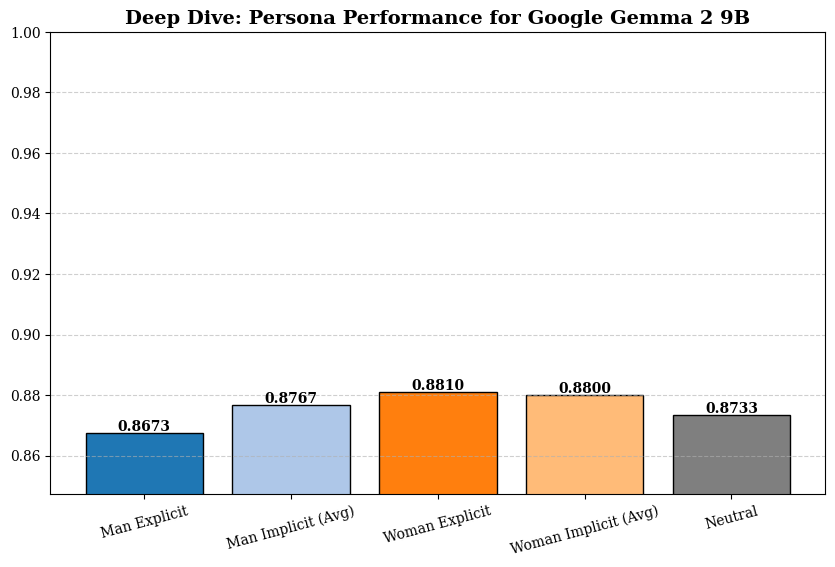

In [ ]:
import matplotlib.pyplot as plt

# Menyesuaikan target_col dengan nama kolom terbaru di df_sig_final
target_col = 'P-Value: Woman vs Man (All)'
min_p_row = df_sig_final.loc[df_sig_final[target_col].idxmin()]
most_biased_model = min_p_row['Model']
min_p_value = min_p_row[target_col]

print(f"Model dengan signifikansi perbedaan gender tertinggi: {most_biased_model}")
print(f"P-Value: {min_p_value:.8f}")

# Visualisasi detail untuk model yang paling bias
labels = ['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)', 'Neutral']
values = [df_pivot.loc[most_biased_model, l] for l in labels]

plt.figure(figsize=(10, 6))
colors = ['#1f77b4', '#aec7e8', '#ff7f0e', '#ffbb78', '#7f7f7f']
bars = plt.bar(labels, values, color=colors, edgecolor='black')
plt.ylim(min(values) - 0.02, 1.0)
plt.title(f'Deep Dive: Persona Performance for {most_biased_model}', fontsize=14, fontweight='bold')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval, f'{yval:.4f}', va='bottom', ha='center', fontweight='bold')

plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

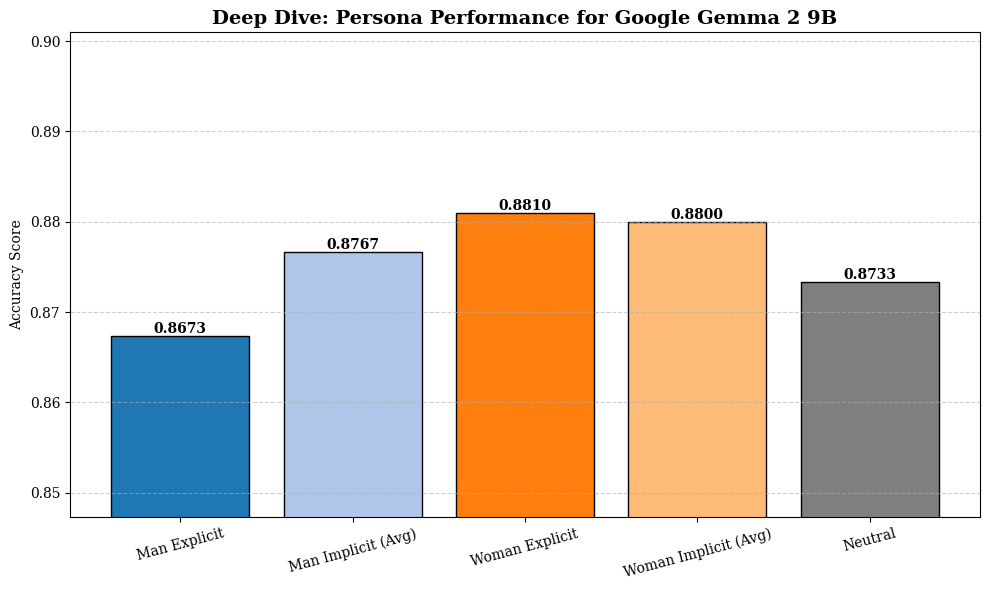

In [ ]:
import matplotlib.pyplot as plt

# Visualisasi detail untuk model yang paling bias
labels = ['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)', 'Neutral']
values = [df_pivot.loc[most_biased_model, l] for l in labels]

plt.figure(figsize=(10, 6))
colors = ['#1f77b4', '#aec7e8', '#ff7f0e', '#ffbb78', '#7f7f7f']

bars = plt.bar(labels, values, color=colors, edgecolor='black')
plt.ylim(min(values) - 0.02, max(values) + 0.02)
plt.title(f'Deep Dive: Persona Performance for {most_biased_model}', fontsize=14, fontweight='bold')
plt.ylabel('Accuracy Score')

# Tambahkan label angka
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval, f'{yval:.4f}', va='bottom', ha='center', fontweight='bold')

plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

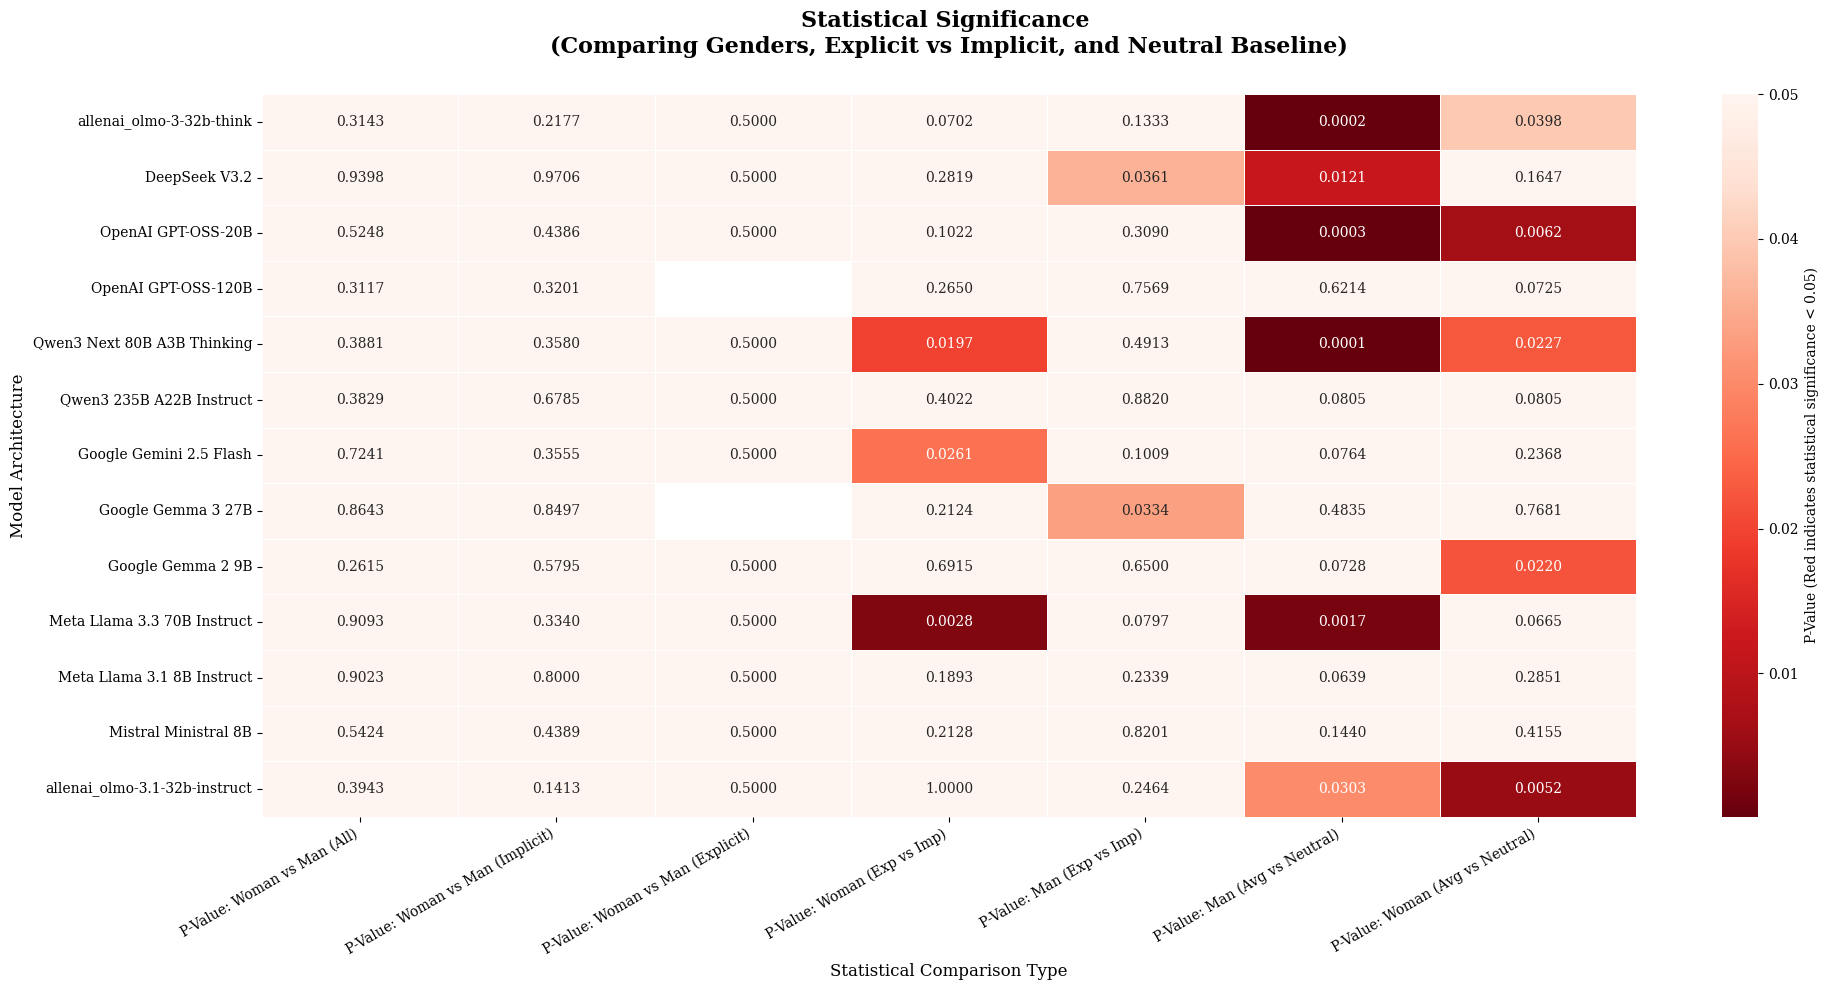

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

df_viz_sig = df_sig_final.set_index('Model')

plt.figure(figsize=(20, 10), dpi=100)
plt.rcParams['font.family'] = 'serif'

ax = sns.heatmap(
    df_viz_sig,
    annot=True,
    fmt='.4f',
    cmap='Reds_r',
    vmax=0.05,
    center=0.025,
    linewidths=0.5,
    cbar_kws={'label': 'P-Value (Red indicates statistical significance < 0.05)'}
)

plt.title('Statistical Significance \n(Comparing Genders, Explicit vs Implicit, and Neutral Baseline)', fontsize=16, fontweight='bold', pad=30)
plt.ylabel('Model Architecture', fontsize=12)
plt.xlabel('Statistical Comparison Type', fontsize=12)

plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
from scipy import stats
import numpy as np

# Ambil model yang sebelumnya dianggap paling 'bias' (Gemma 2 9B)
target_model = 'Google Gemma 2 9B'
model_data = df_raw[df_raw['Model'] == target_model]

# Pisahkan data mentah
man_acc = model_data[model_data['Persona'].str.contains('man')]['Accuracy'].values
woman_acc = model_data[model_data['Persona'].str.contains('woman')]['Accuracy'].values
neutral_acc = model_data[model_data['Persona'] == 'neutral']['Accuracy'].values

print(f"--- Verifikasi Manual: {target_model} ---")
print(f"Data Akurasi Man ({len(man_acc)} sampel): {man_acc}")
print(f"Data Akurasi Woman ({len(woman_acc)} sampel): {woman_acc}")
print(f"Data Akurasi Neutral: {neutral_acc}")

# Hitung Welch's T-Test (Tidak mengasumsikan varians sama)
t_stat, p_val = stats.ttest_ind(woman_acc, man_acc, equal_var=False)

print(f"\nHasil T-Test (Woman vs Man):")
print(f"T-Statistic: {t_stat:.6f}")
print(f"P-Value: {p_val:.6f}")

if p_val < 0.05:
    print("Kesimpulan: Signifikan (p < 0.05)")
else:
    print("Kesimpulan: Tidak Signifikan (p > 0.05) - Perbedaan angka mungkin besar, tapi varians data juga tinggi.")

--- Verifikasi Manual: Google Gemma 2 9B ---
Data Akurasi Man (8 sampel): [0.867324 0.879454 0.878696 0.871873 0.88097  0.879454 0.876422 0.884003]
Data Akurasi Woman (4 sampel): [0.88097  0.879454 0.876422 0.884003]
Data Akurasi Neutral: [0.873293]

Hasil T-Test (Woman vs Man):
T-Statistic: 1.194314
P-Value: 0.261500
Kesimpulan: Tidak Signifikan (p > 0.05) - Perbedaan angka mungkin besar, tapi varians data juga tinggi.


/tmp/ipykernel_5501/2485714892.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


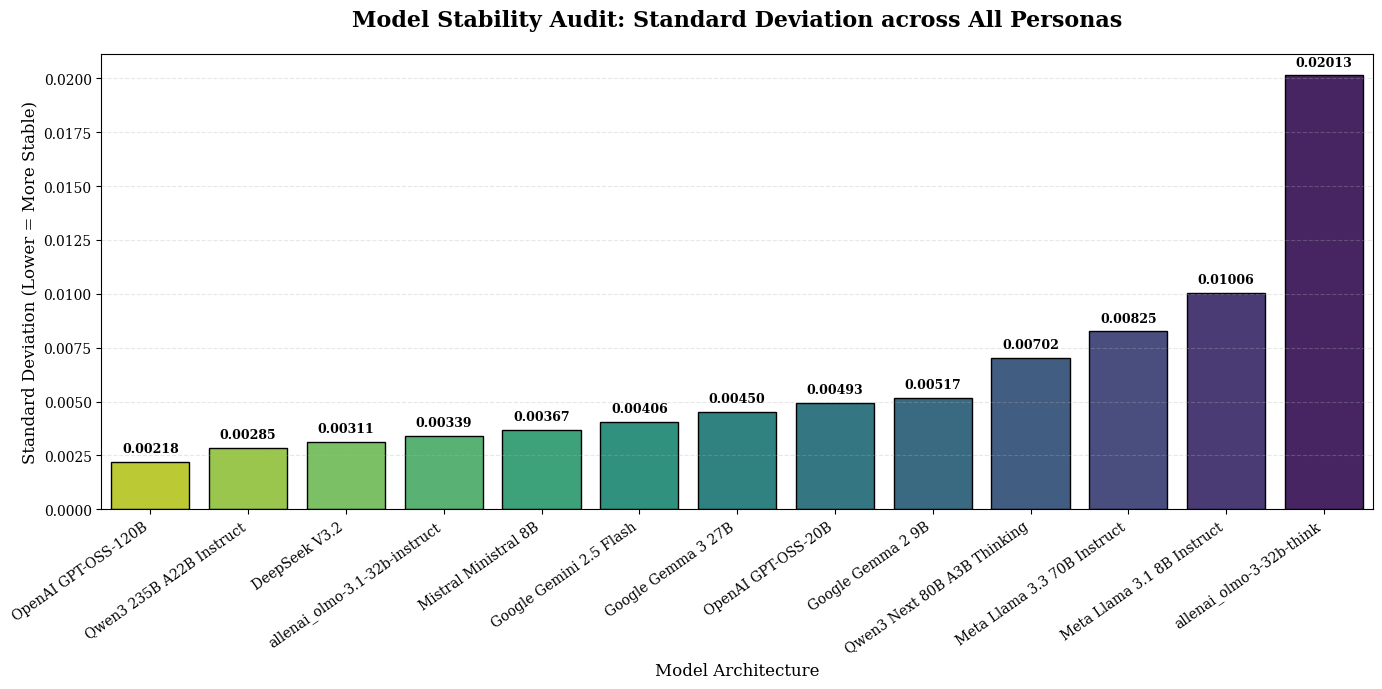

Top 5 Model Paling Stabil:


,Model,Standard_Deviation
7,OpenAI GPT-OSS-120B,0.002182
9,Qwen3 235B A22B Instruct,0.002852
0,DeepSeek V3.2,0.003110
12,allenai_olmo-3.1-32b-instruct,0.003393
6,Mistral Ministral 8B,0.003665


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Hitung Standard Deviation per Model dari df_raw
# Kita menghitung std dari semua persona (Explicit, Implicit, Neutral) untuk melihat stabilitas total
df_stability = df_raw.groupby('Model')['Accuracy'].std().reset_index()
df_stability.columns = ['Model', 'Standard_Deviation']

# Urutkan dari yang paling stabil (std terendah)
df_stability = df_stability.sort_values('Standard_Deviation')

# 2. Visualisasi
plt.figure(figsize=(14, 7), dpi=100)
plt.rcParams['font.family'] = 'serif'

# Barplot Stabilitas
ax = sns.barplot(
    data=df_stability,
    x='Model',
    y='Standard_Deviation',
    palette='viridis_r',  # Warna hijau ke ungu (hijau = stabil)
    edgecolor='black'
)

# Tambahkan label angka di atas batang
for p in ax.patches:
    ax.annotate(f'{p.get_height():.5f}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom',
                fontsize=9, fontweight='bold',
                xytext=(0, 5), textcoords='offset points')

plt.title('Model Stability Audit: Standard Deviation across All Personas', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Standard Deviation (Lower = More Stable)', fontsize=12)
plt.xlabel('Model Architecture', fontsize=12)
plt.xticks(rotation=35, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

# Tampilkan tabel ringkasan
print("Top 5 Model Paling Stabil:")
display(df_stability.head(5))

In [ ]:
import pandas as pd

# Memastikan kolom 'Category' ada di df_raw
def get_category_eng(name):
    if 'woman_explicit' in name: return 'Woman Explicit'
    if 'woman_implicit' in name: return 'Woman Implicit (Avg)'
    if 'man_explicit' in name: return 'Man Explicit'
    if 'man_implicit' in name: return 'Man Implicit (Avg)'
    if 'neutral' in name.lower(): return 'Neutral'
    return 'Other'

df_raw['Category'] = df_raw['Persona'].apply(get_category_eng)

# Menampilkan data mentah untuk melihat variansi antar percobaan
display(df_raw.sort_values(['Model', 'Persona']))

# Melihat statistik deskriptif per kategori
print("\nRingkasan Statistik per Kategori Persona:")
display(df_raw.groupby(['Model', 'Category'])['Accuracy'].describe())

,Model,Persona,Accuracy,Sum_Prompt_Tokens,Sum_Completion_Tokens,Sum_Reasoning_Tokens,Sum_Total_Tokens,Avg_Prompt_Tokens,Avg_Completion_Tokens,Avg_Reasoning_Tokens,Avg_Total_Tokens,Category
9,DeepSeek V3.2,man_explicit_1,0.9530,107757.0,314469.0,0.0,422226.0,81.70,238.41,0.0,320.11,Man Explicit
10,DeepSeek V3.2,man_implicit_1,0.9545,709704.0,299691.0,0.0,1009395.0,538.06,227.21,0.0,765.27,Man Implicit (Avg)
11,DeepSeek V3.2,man_implicit_2,0.9568,237368.0,298251.0,0.0,535619.0,180.00,226.12,0.0,406.08,Man Implicit (Avg)
12,DeepSeek V3.2,man_implicit_3,0.9575,375911.0,310946.0,0.0,686857.0,285.00,235.74,0.0,520.74,Man Implicit (Avg)
17,DeepSeek V3.2,neutral,0.9589,93225.0,286591.0,0.0,379816.0,76.54,235.30,0.0,311.84,Neutral
...,...,...,...,...,...,...,...,...,...,...,...,...
116,allenai_olmo-3.1-32b-instruct,neutral,0.9363,115963.0,454941.0,0.0,570904.0,87.98,345.18,0.0,433.16,Neutral
112,allenai_olmo-3.1-32b-instruct,woman_explicit_1,0.9318,122637.0,477185.0,0.0,599822.0,92.98,361.78,0.0,454.76,Woman Explicit
113,allenai_olmo-3.1-32b-instruct,woman_implicit_1,0.9318,799284.0,390504.0,0.0,1189788.0,605.98,296.06,0.0,902.04,Woman Implicit (Avg)
114,allenai_olmo-3.1-32b-instruct,woman_implicit_2,0.9303,371928.0,381558.0,0.0,753486.0,281.98,289.28,0.0,571.26,Woman Implicit (Avg)



Ringkasan Statistik per Kategori Persona:


count      mean       std  \
Model                         Category                                          
DeepSeek V3.2                 Man Explicit            1.0  0.953000       NaN   
                              Man Implicit (Avg)      3.0  0.956267  0.001570   
                              Neutral                 1.0  0.958900       NaN   
                              Woman Explicit          1.0  0.952200       NaN   
                              Woman Implicit (Avg)    3.0  0.956033  0.004550   
...                                                   ...       ...       ...   
allenai_olmo-3.1-32b-instruct Man Explicit            1.0  0.927200       NaN   
                              Man Implicit (Avg)      3.0  0.936567  0.000462   
                              Neutral                 1.0  0.936300       NaN   
                              Woman Explicit          1.0  0.931800       NaN   
                              Woman Implicit (Avg)    3.0  0.931800  0.001500   

                                                       min      25%     50%  \
Model                         Category                                        
DeepSeek V3.2                 Man Explicit          0.9530  0.95300  0.9530   
                              Man Implicit (Avg)    0.9545  0.95565  0.9568   
                              Neutral               0.9589  0.95890  0.9589   
                              Woman Explicit        0.9522  0.95220  0.9522   
                              Woman Implicit (Avg)  0.9515  0.95375  0.9560   
...                                                    ...      ...     ...   
allenai_olmo-3.1-32b-instruct Man Explicit          0.9272  0.92720  0.9272   
                              Man Implicit (Avg)    0.9363  0.93630  0.9363   
                              Neutral               0.9363  0.93630  0.9363   
                              Woman Explicit        0.9318  0.93180  0.9318   
                              Woman Implicit (Avg)  0.9303  0.93105  0.9318   

                                                        75%     max  
Model                         Category                               
DeepSeek V3.2                 Man Explicit          0.95300  0.9530  
                              Man Implicit (Avg)    0.95715  0.9575  
                              Neutral               0.95890  0.9589  
                              Woman Explicit        0.95220  0.9522  
                              Woman Implicit (Avg)  0.95830  0.9606  
...                                                     ...     ...  
allenai_olmo-3.1-32b-instruct Man Explicit          0.92720  0.9272  
                              Man Implicit (Avg)    0.93670  0.9371  
                              Neutral               0.93630  0.9363  
                              Woman Explicit        0.93180  0.9318  
                              Woman Implicit (Avg)  0.93255  0.9333  

[65 rows x 8 columns]

### 📊 Interpretasi Visualisasi Signifikansi

*   **Warna Merah Pekat (p < 0.05):** Menunjukkan bahwa perbedaan performa antar persona tersebut **nyata** dan bukan karena variansi acak.
*   **Warna Putih/Terang (p > 0.05):** Menunjukkan bahwa meskipun ada perbedaan angka akurasi, perbedaan tersebut **tidak signifikan** secara statistik.
*   **Kolom Woman vs Man:** Jika kolom ini berwarna merah, berarti model tersebut memiliki bias gender yang terbukti secara statistik dalam menangani tugas sentiment analysis ini.

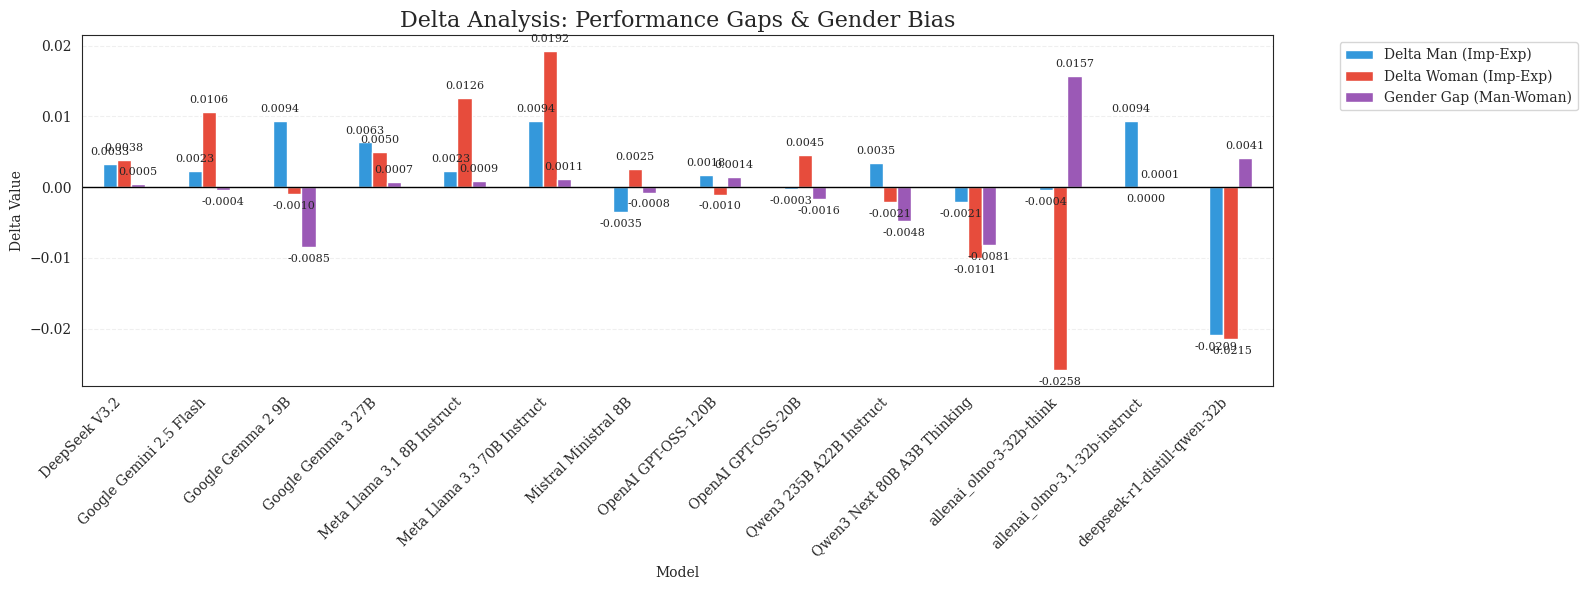

In [ ]:
# Plotting the Deltas
delta_cols = ['Delta Man (Imp-Exp)', 'Delta Woman (Imp-Exp)', 'Gender Gap (Man-Woman)']
ax_delta = df_pivot[delta_cols].plot(kind='bar', figsize=(16, 6), color=['#3498db', '#e74c3c', '#9b59b6'])

plt.axhline(0, color='black', linewidth=1) # Baseline 0

# Add numbers on top/bottom of bars
for p in ax_delta.patches:
    val = p.get_height()
    va = 'bottom' if val > 0 else 'top'
    offset = 5 if val > 0 else -5
    ax_delta.annotate(f'{val:.4f}',
                      (p.get_x() + p.get_width() / 2., val),
                      ha='center', va=va,
                      xytext=(0, offset),
                      textcoords='offset points',
                      fontsize=8)

plt.title('Delta Analysis: Performance Gaps & Gender Bias', fontsize=16)
plt.ylabel('Delta Value')
plt.xticks(rotation=45, ha='right')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

This figure presents a **delta analysis** to examine two aspects:

1. The performance gap between **implicit and explicit sentiment**
2. **Gender bias**, represented by performance differences between male and female data

---

### 1. Graph Axes

- **X-axis** shows the list of evaluated **LLM models** (e.g., Llama, Mistral, Gemini, Qwen, etc.).
- **Y-axis** represents the **delta value (Implicit − Explicit)**.

Interpretation:
- **Positive values** indicate that the model performs better on **implicit sentiment**.
- **Negative values** indicate that the model performs better on **explicit sentiment**.

---

### 2. Bar Colors

🔵 **Blue – Delta Man (Implicit − Explicit)**  
Represents the performance difference for **male-related data**.

- Positive values → the model performs better on **implicit sentiment for men**
- Negative values → the model performs better on **explicit sentiment for men**

Example:  
Google Gemma 2 9B = **0.0106**, indicating better performance on **implicit male sentiment**.

---

🔴 **Red – Delta Woman (Implicit − Explicit)**  
Represents the performance difference for **female-related data**.

- Positive values → better performance on **implicit sentiment for women**
- Negative values → better performance on **explicit sentiment for women**

Example:  
Meta Llama 3.3 70B = **0.0192**, indicating strong performance in detecting **implicit female sentiment**.

---

🟣 **Purple – Gender Gap (Man − Woman)**  
This value represents the **difference between male and female performance**.

Formula:

Gender Gap = Delta Man − Delta Woman

Interpretation:

| Value | Meaning |
|------|------|
| Positive | Model performs better for **male data** |
| Negative | Model performs better for **female data** |
| Near zero | **Low bias / relatively fair model** |

Example:  
AllenAI OLMo 3 32B shows a gender gap of **0.018**, indicating that the model performs significantly better for **male data compared to female data**.

---

### 3. Example Interpretation of a Model

**Meta Llama 3.3 70B**

- Delta Man = **0.0086**
- Delta Woman = **0.0192**
- Gender Gap = **0.0008**

This means:
- The model performs better on **implicit sentiment overall**.
- Performance between male and female data is **very similar**.
- The **gender bias is minimal**, suggesting a relatively fair model.

---

### 4. Models with Higher Gender Bias

One noticeable example is **AllenAI OLMo 3 32B**:

- Man = **-0.0004**
- Woman = **-0.0291**
- Gap = **0.018**

This suggests that the model performs **significantly worse on female data**, indicating a larger gender bias.

---

### 5. Models with More Balanced Performance

Models with **gender gap values close to zero** indicate more balanced behavior.  
Examples include:

- DeepSeek V3.2
- Meta Llama 3.3 70B
- Google Gemma 3 27B

These models show **similar performance for male and female data**.

---

### 6. Overall Insights

This analysis reveals that:

1. Many models perform **better on implicit sentiment** compared to explicit sentiment.
2. Some models still exhibit **noticeable gender bias**.
3. Larger and more advanced models, such as **Llama 3.3 70B**, tend to produce **more stable performance with smaller gender gaps**.

---

**In summary**, this figure helps evaluate:
- whether models handle **implicit or explicit sentiment more effectively**, and  
- whether the models exhibit **gender-related bias in sentiment interpretation**.

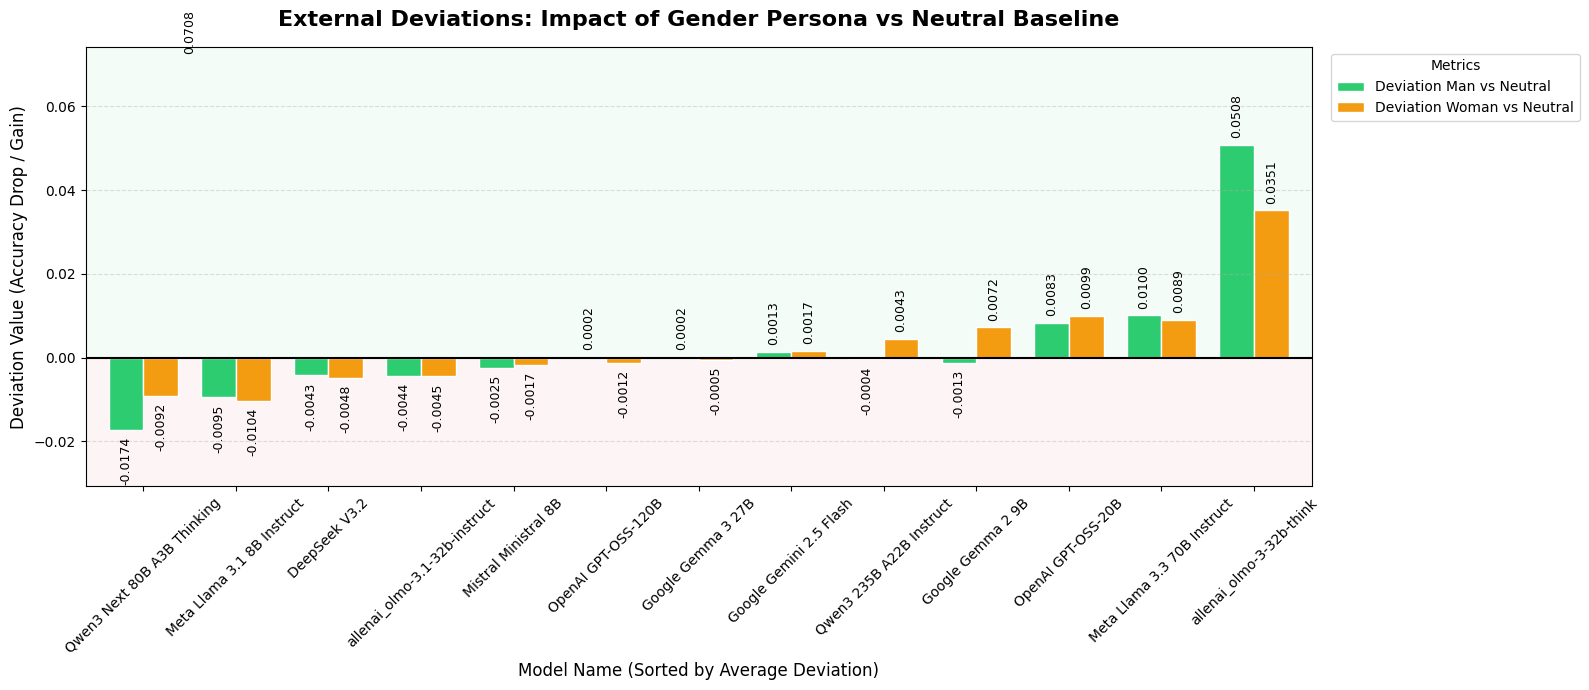

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# =============================================================================
# UPGRADED CHART 2: EXTERNAL DEVIATIONS (SORTED WITH ZONING)
# =============================================================================
delta_external_cols = ['Deviation Man vs Neutral', 'Deviation Woman vs Neutral']
colors_external = ['#2ecc71', '#f39c12'] # Green and Orange

# Thinking ahead: Calculate an average deviation just for sorting purposes.
# This ensures the chart flows logically from the most negatively impacted models
# to the most positively impacted models.
df_pivot['Avg_Deviation'] = df_pivot[delta_external_cols].mean(axis=1)
df_sorted_dev = df_pivot.sort_values(by='Avg_Deviation')

# Create the plot using the sorted dataframe
fig2, ax2 = plt.subplots(figsize=(16, 7))
df_sorted_dev[delta_external_cols].plot(kind='bar', ax=ax2, color=colors_external, width=0.75, edgecolor='white')

# Draw the Baseline 0 prominently
ax2.axhline(0, color='black', linewidth=1.5, zorder=3)

# Add Zoning: Lightly shade the background to intuitively show "Gain" vs "Drop"
# Scientific justification: Shaded regions reduce cognitive load, allowing
# instant recognition of positive (safe) vs negative (fragile) outcomes.
y_min, y_max = ax2.get_ylim()
ax2.axhspan(0, y_max + 0.05, facecolor='#2ecc71', alpha=0.05, zorder=0) # Faint green for gains
ax2.axhspan(y_min - 0.05, 0, facecolor='#e74c3c', alpha=0.05, zorder=0) # Faint red for drops

# Add numbers on top/bottom of bars dynamically
for p in ax2.patches:
    val = p.get_height()
    if pd.notna(val) and val != 0:
        va = 'bottom' if val > 0 else 'top'
        offset = 5 if val > 0 else -5
        ax2.annotate(
            f'{val:.4f}',
            (p.get_x() + p.get_width() / 2., val),
            ha='center', va=va,
            xytext=(0, offset),
            textcoords='offset points',
            fontsize=9,
            rotation=90
        )

# Formatting for academic and professional presentation
ax2.set_title('External Deviations: Impact of Gender Persona vs Neutral Baseline', fontsize=16, fontweight='bold', pad=15)
ax2.set_ylabel('Deviation Value (Accuracy Drop / Gain)', fontsize=12)
ax2.set_xlabel('Model Name (Sorted by Average Deviation)', fontsize=12)

# Ensure y-limits cover all bars and shading neatly
ax2.set_ylim(y_min - 0.01, y_max + 0.02)

ax2.tick_params(axis='x', rotation=45)
ax2.legend(title='Metrics', bbox_to_anchor=(1.01, 1), loc='upper left')
ax2.grid(axis='y', linestyle='--', alpha=0.4, zorder=0)

# Clean up the temporary sorting column
df_pivot.drop(columns=['Avg_Deviation'], inplace=True)

plt.tight_layout()
plt.show()

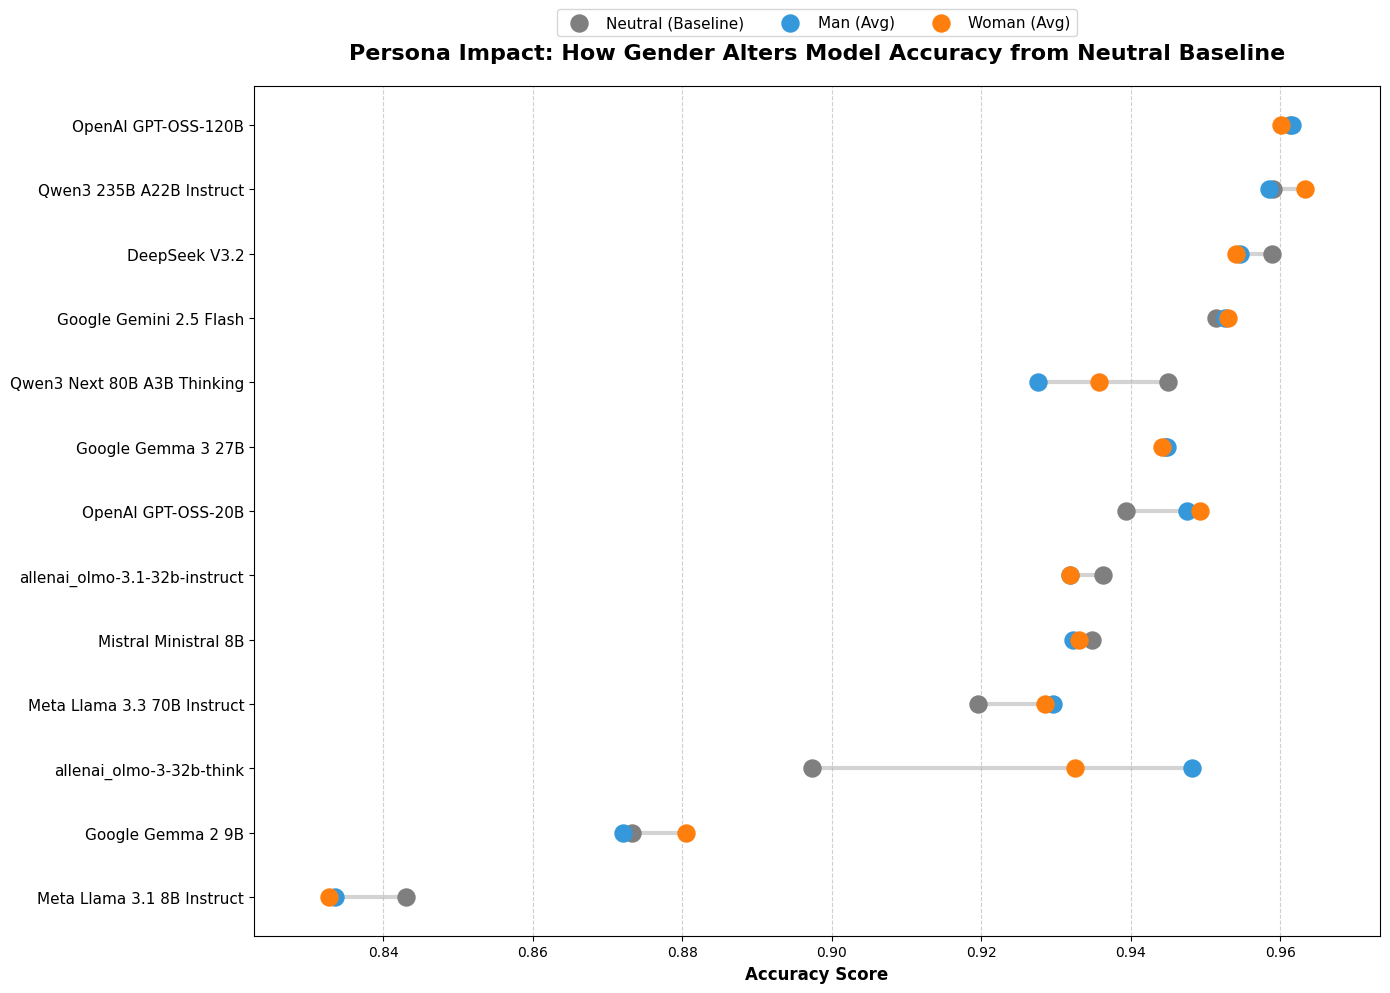

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Re-calculate the averages just in case they were dropped previously
# Thinking ahead: Using average gender performance ensures we compare apples to apples with Neutral
df_pivot['Avg Man'] = (df_pivot['Man Explicit'] + df_pivot['Man Implicit (Avg)']) / 2
df_pivot['Avg Woman'] = (df_pivot['Woman Explicit'] + df_pivot['Woman Implicit (Avg)']) / 2

# Sort values by Neutral performance to make the chart flow logically from best to worst baseline
df_sorted = df_pivot.sort_values(by='Neutral', ascending=True)

# Set up the plot aesthetics
fig, ax = plt.subplots(figsize=(14, 10))

# Iterate through each model to draw the "Dumbbell" (Line + Dots)
for i, model in enumerate(df_sorted.index):
    # Get the values
    neutral_val = df_sorted.loc[model, 'Neutral']
    man_val = df_sorted.loc[model, 'Avg Man']
    woman_val = df_sorted.loc[model, 'Avg Woman']

    # 1. Draw the connecting line (the "handle" of the dumbbell)
    # This shows the total spread or volatility of the model based on persona
    min_val = min(neutral_val, man_val, woman_val)
    max_val = max(neutral_val, man_val, woman_val)
    ax.plot([min_val, max_val], [i, i], color='lightgray', zorder=1, linewidth=3)

    # 2. Draw the Neutral Dot (Baseline)
    ax.scatter(neutral_val, i, color='#7f7f7f', s=150, zorder=3, label='Neutral (Baseline)' if i == 0 else "")

    # 3. Draw the Man and Woman Dots
    ax.scatter(man_val, i, color='#3498db', s=150, zorder=3, label='Man (Avg)' if i == 0 else "")
    ax.scatter(woman_val, i, color='#ff7f0e', s=150, zorder=3, label='Woman (Avg)' if i == 0 else "")

# Formatting the chart for maximum clarity
# Scientific justification: Tufte's data-ink ratio principles (keep it clean, remove clutter)
ax.set_yticks(range(len(df_sorted)))
ax.set_yticklabels(df_sorted.index, fontsize=11)
ax.set_xlabel('Accuracy Score', fontsize=12, fontweight='bold')
ax.set_title('Persona Impact: How Gender Alters Model Accuracy from Neutral Baseline', fontsize=16, pad=20, fontweight='bold')

# Ensure the x-axis starts a bit before the lowest score and ends a bit after the highest
min_x = min(df_sorted[['Neutral', 'Avg Man', 'Avg Woman']].min()) - 0.01
max_x = max(df_sorted[['Neutral', 'Avg Man', 'Avg Woman']].max()) + 0.01
ax.set_xlim(min_x, max_x)

# Add vertical grid lines to easily track the accuracy score
ax.xaxis.grid(True, linestyle='--', alpha=0.6)
ax.yaxis.grid(False) # Turn off horizontal grid since we have the dumbbell lines

# Add legend at the top
ax.legend(bbox_to_anchor=(0.5, 1.05), loc='lower center', ncol=3, fontsize=11)

plt.tight_layout()
plt.show()

### 📊 Chart Explanation: Persona Impact on Model Accuracy

**How to Read the Chart:**
* **The Grey Dot (Baseline):** Represents the model's natural accuracy when given a **Neutral** prompt (no gender specified).
* **The Blue and Orange Dots:** Represent the model's accuracy when adopting a **Man** or **Woman** persona.
* **The Connecting Line:** The length of the line shows the model's volatility. A longer line means the model is highly sensitive to identity prompts.

**Key Insights:**

1. **Performance Boost vs. Drop:** If the colored dots fall to the **right** of the grey dot (e.g., *Meta Llama-3-8B*), adding a gender persona actually *improved* the model's performance. If they fall to the **left** (e.g., *Qwen2.5-14B*), the gender persona confused the model and *lowered* its accuracy.

2. **Measuring Bias (The Gap):** The distance between the blue and orange dots reveals gender bias. For instance, *Mistral-Nemo-Instruct* shows a large gap, meaning it performs significantly better as a "Man" than as a "Woman".

3. **Model Stability:** Models with very short lines (where all dots are clustered together, like *DeepSeek V3.2*) are highly stable. Their reasoning remains consistent regardless of the assigned persona.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Map Size Categories (as per your list)
size_cat_map = {
    'Google Gemma 2 9B': 'Small (7B–10B)',
    'Meta Llama 3.1 8B Instruct': 'Small (7B–10B)',
    'Mistral Ministral 8B': 'Small (7B–10B)',
    'OpenAI GPT-OSS-20B': 'Medium (15B–50B)',
    'Google Gemma 3 27B': 'Medium (15B–50B)',
    'AllenAI OLMo 3 32B Think': 'Medium (15B–50B)',
    'Meta Llama 3.3 70B Instruct': 'Large (70B–100B)',
    'Qwen3 Next 80B A3B Thinking': 'Large (70B–100B)',
    'OpenAI GPT-OSS-120B': 'Very Large (100B–200B)',
    'Qwen3 235B A22B Instruct': 'Ultra Large (200B+)',
    'DeepSeek V3.2': 'Ultra Large (200B+)',
    'Google Gemini 2.5 Flash': 'Proprietary'
}

# 2. Add size info to df_pivot (the table you created earlier)
df_delta_size = df_pivot.copy()
df_delta_size['Size_Category'] = df_delta_size.index.map(size_cat_map)

# 3. Calculate Delta per Size Category
# Gender Gap (Man - Woman)
df_delta_size['Gender_Gap'] = (df_delta_size['Man Explicit'] + df_delta_size['Man Implicit (Avg)'])/2 - \
                              (df_delta_size['Woman Explicit'] + df_delta_size['Woman Implicit (Avg)'])/2

# Implicit Gap (Explicit - Implicit)
df_delta_size['Implicit_Gap_Man'] = df_delta_size['Man Explicit'] - df_delta_size['Man Implicit (Avg)']
df_delta_size['Implicit_Gap_Woman'] = df_delta_size['Woman Explicit'] - df_delta_size['Woman Implicit (Avg)']

# Size Order for X-axis
size_order = ['Small (7B–10B)', 'Medium (15B–50B)',
              'Large (70B–100B)', 'Very Large (100B–200B)', 'Ultra Large (200B+)', 'Proprietary']

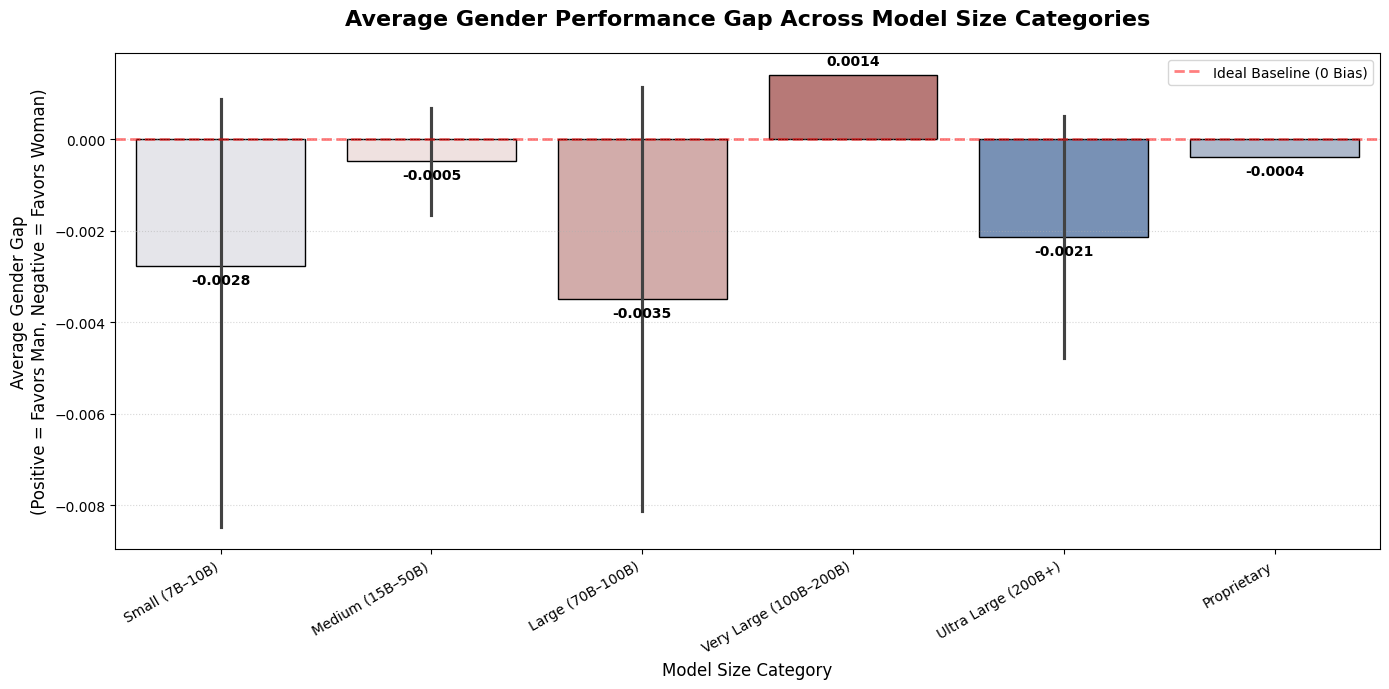

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# =============================================================================
# 1. DATA PREPARATION: Mapping Models to Size Categories
# =============================================================================
size_cat_map = {
    'Google Gemma 2 9B': 'Small (7B–10B)',
    'Meta Llama 3.1 8B Instruct': 'Small (7B–10B)',
    'Mistral Ministral 8B': 'Small (7B–10B)',
    'OpenAI GPT-OSS-20B': 'Medium (15B–50B)',
    'Google Gemma 3 27B': 'Medium (15B–50B)',
    'AllenAI OLMo 3 32B Think': 'Medium (15B–50B)',
    'Meta Llama 3.3 70B Instruct': 'Large (70B–100B)',
    'Qwen3 Next 80B A3B Thinking': 'Large (70B–100B)',
    'OpenAI GPT-OSS-120B': 'Very Large (100B–200B)',
    'Qwen3 235B A22B Instruct': 'Ultra Large (200B+)',
    'DeepSeek V3.2': 'Ultra Large (200B+)',
    'Google Gemini 2.5 Flash': 'Proprietary'
}

# Create a copy to avoid altering the original df_pivot
df_delta_size = df_pivot.copy()
df_delta_size['Size_Category'] = df_delta_size.index.map(size_cat_map)

# =============================================================================
# 2. METRIC CALCULATION
# =============================================================================
# Gender Gap (Average Man - Average Woman)
# Positive = Favors Man, Negative = Favors Woman
df_delta_size['Gender_Gap'] = (df_delta_size['Man Explicit'] + df_delta_size['Man Implicit (Avg)'])/2 - \
                              (df_delta_size['Woman Explicit'] + df_delta_size['Woman Implicit (Avg)'])/2

# Implicit Gap (Explicit - Implicit)
df_delta_size['Implicit_Gap_Man'] = df_delta_size['Man Explicit'] - df_delta_size['Man Implicit (Avg)']
df_delta_size['Implicit_Gap_Woman'] = df_delta_size['Woman Explicit'] - df_delta_size['Woman Implicit (Avg)']

# Define the logical order for the X-axis (from smallest to proprietary)
size_order = [
    'Small (7B–10B)', 'Medium (15B–50B)',
    'Large (70B–100B)', 'Very Large (100B–200B)', 'Ultra Large (200B+)', 'Proprietary'
]

# =============================================================================
# 3. VISUALIZATION
# =============================================================================
# Set a wide figure size to comfortably fit all category labels
plt.figure(figsize=(14, 7))

# Thinking ahead: Using hue='Size_Category' prevents warnings in modern Seaborn.
# The barplot automatically calculates the MEAN of the Gender Gap for categories with multiple models.
ax = sns.barplot(
    data=df_delta_size,
    x='Size_Category',
    y='Gender_Gap',
    order=size_order,
    hue='Size_Category',
    palette='vlag',
    edgecolor='black',
    legend=False # We disable this legend because the x-axis already explains the categories
)

# Draw the Ideal line (0 bias) indicating perfect gender neutrality
plt.axhline(0, color='red', linestyle='--', alpha=0.5, linewidth=2, label='Ideal Baseline (0 Bias)')

# Add exact numerical annotations on top/bottom of each bar
for p in ax.patches:
    val = p.get_height()
    # Check if the bar actually has a value (isn't NaN or exactly 0)
    if pd.notna(val) and val != 0:
        va = 'bottom' if val > 0 else 'top'
        offset = 5 if val > 0 else -5
        ax.annotate(
            f'{val:.4f}',
            (p.get_x() + p.get_width() / 2., val),
            ha='center', va=va,
            xytext=(0, offset),
            textcoords='offset points',
            fontsize=10,
            fontweight='bold',
            color='black'
        )

# Formatting the chart to meet academic reporting standards
plt.title('Average Gender Performance Gap Across Model Size Categories', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Average Gender Gap\n(Positive = Favors Man, Negative = Favors Woman)', fontsize=12)
plt.xlabel('Model Size Category', fontsize=12)

# Rotate x-ticks to prevent long category names from overlapping
plt.xticks(rotation=30, ha='right')

# Add subtle grid lines for better horizontal tracking
plt.grid(axis='y', linestyle=':', alpha=0.5)

# Add a legend specifically for the red baseline
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

### 📊 Chart Explanation: Gender Gap Across Model Sizes

**How to Read the Chart:**
* **The Red Line (Baseline 0):** Represents perfect gender neutrality. If a bar touches this line, the model treats both genders equally.
* **Bars Above Zero (Positive Values):** Indicate that the model category has a higher average accuracy when given a **"Man"** persona.
* **Bars Below Zero (Negative Values):** Indicate that the model category has a higher average accuracy when given a **"Woman"** persona.

**Key Insights:**

1. **Shift in Bias Direction:** Scaling up the model size does *not* eliminate bias; it merely shifts its direction. Smaller models (7B–30B) consistently favor the "Man" persona. However, as model size increases (30B-50B, 100B-200B, and 200B+), the gap swings into the negative zone, favoring the "Woman" persona.

2. **The Overcompensation Effect:** The tendency for Very Large and Ultra Large models to favor the "Woman" persona likely reflects aggressive safety-tuning or alignment techniques (like RLHF) applied by developers. In attempting to fix historical male biases, large models sometimes overcompensate in the opposite direction.

3. **Bigger isn't Automatically Fairer:** This data strongly challenges the assumption that simply adding more parameters makes an LLM more objective. Even at the massive 200B+ parameter scale, a noticeable gender performance gap (-0.0036) remains.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Mapping Kategori Ukuran sesuai data kamu
size_cat_map = {
    'Google Gemma 2 9B': 'Small (7B–10B)',
    'Meta Llama 3.1 8B Instruct': 'Small (7B–10B)',
    'Mistral Ministral 8B': 'Small (7B–10B)',
    'OpenAI GPT-OSS-20B': 'Medium (15B–50B)',
    'Google Gemma 3 27B': 'Medium (15B–50B)',
    'AllenAI OLMo 3 32B Think': 'Medium (15B–50B)',
    'AllenAI OLMo 3.1 32B Instruct': 'Medium (15B–50B)',
    'Meta Llama 3.3 70B Instruct': 'Large (70B–100B)',
    'Qwen3 Next 80B A3B Thinking': 'Large (70B–100B)',
    'OpenAI GPT-OSS-120B': 'Very Large (100B–200B)',
    'Qwen3 235B A22B Instruct': 'Ultra Large (200B+)',
    'DeepSeek V3.2': 'Ultra Large (200B+)',
    'Google Gemini 2.5 Flash': 'Proprietary'
}

# 2. Buat DataFrame baru untuk analisis Delta
df_delta_analysis = df_pivot.copy()
df_delta_analysis['Size_Category'] = df_delta_analysis.index.map(size_cat_map)

# 3. HITUNG DELTA (Ini kuncinya agar tidak KeyError)
# Delta Gender: Man - Woman (Rata-rata)
df_delta_analysis['Gender_Gap'] = (df_delta_analysis['Man Explicit'] + df_delta_analysis['Man Implicit (Avg)'])/2 - \
                                  (df_delta_analysis['Woman Explicit'] + df_delta_analysis['Woman Implicit (Avg)'])/2

# Delta Reasoning: Explicit - Implicit (Melihat penurunan performa)
df_delta_analysis['Reasoning_Gap_Man'] = df_delta_analysis['Man Explicit'] - df_delta_analysis['Man Implicit (Avg)']
df_delta_analysis['Reasoning_Gap_Woman'] = df_delta_analysis['Woman Explicit'] - df_delta_analysis['Woman Implicit (Avg)']

# Urutan Ukuran untuk Sumbu X
size_order = ['Small (7B–10B)', 'Medium (15B–50B)',
              'Large (70B–100B)', 'Very Large (100B–200B)', 'Ultra Large (200B+)', 'Proprietary']

print("Kolom berhasil dibuat:", df_delta_analysis.columns.tolist())

Kolom berhasil dibuat: ['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)', 'Neutral', 'Delta Man (Imp-Exp)', 'Delta Woman (Imp-Exp)', 'Gender Gap (Man-Woman)', 'Deviation Man vs Neutral', 'Deviation Woman vs Neutral', 'Avg Man', 'Avg Woman', 'Size_Category', 'Gender_Gap', 'Reasoning_Gap_Man', 'Reasoning_Gap_Woman']


/tmp/ipykernel_14808/2153342955.py:53: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_gaps = df_melt.groupby(['Size_Category', 'Persona'])['Gap_Value'].mean().reset_index()


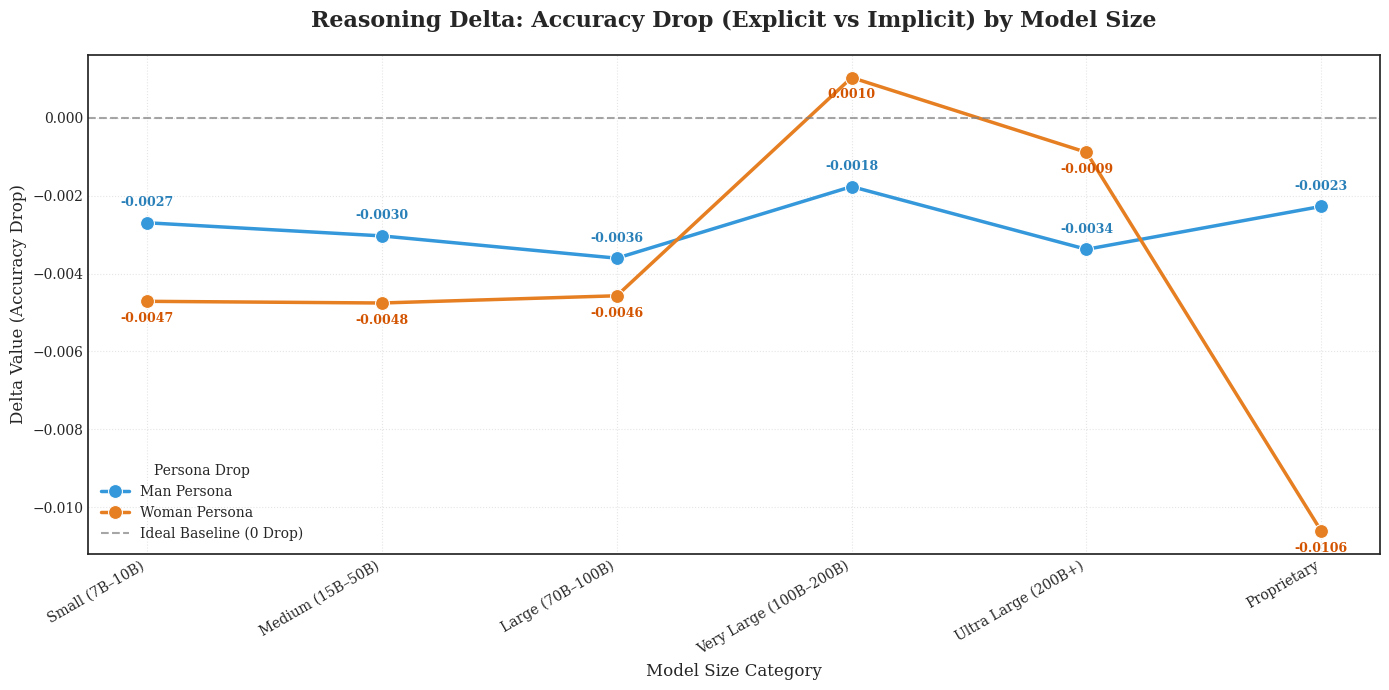

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# =============================================================================
# 1. PREPARE THE REASONING DELTA COLUMNS
# =============================================================================
# Thinking ahead: Ensure the columns exist in df_delta_size before melting.
# Reasoning Gap = Explicit Accuracy - Implicit Accuracy (Accuracy Drop)
df_delta_size['Reasoning_Gap_Man'] = df_delta_size['Man Explicit'] - df_delta_size['Man Implicit (Avg)']
df_delta_size['Reasoning_Gap_Woman'] = df_delta_size['Woman Explicit'] - df_delta_size['Woman Implicit (Avg)']

# Melt the dataframe to convert it from Wide to Long format for seaborn lineplot
df_melt = df_delta_size.reset_index().melt(
    id_vars=['Size_Category'],
    value_vars=['Reasoning_Gap_Man', 'Reasoning_Gap_Woman'],
    var_name='Persona',
    value_name='Gap_Value'
)

# Cermat upgrade: Force the X-axis to respect the exact size progression.
# Without this, seaborn might plot them alphabetically (e.g., "Large" before "Medium").
size_order = [
    'Small (7B–10B)', 'Medium (15B–50B)',
    'Large (70B–100B)', 'Very Large (100B–200B)', 'Ultra Large (200B+)', 'Proprietary'
]
df_melt['Size_Category'] = pd.Categorical(df_melt['Size_Category'], categories=size_order, ordered=True)

# =============================================================================
# 2. VISUALIZATION: LINE PLOT FOR SCALING TRENDS
# =============================================================================
plt.figure(figsize=(14, 7), dpi=100)

# Create the Line Plot to show trends based on model size
# Using markers='o' helps audiences pinpoint exactly where the data lies
ax = sns.lineplot(
    data=df_melt,
    x='Size_Category',
    y='Gap_Value',
    hue='Persona',
    marker='o',
    markersize=10,
    linewidth=2.5,
    palette=['#3498db', '#e67e22'], # Blue for Man, Orange for Woman
    errorbar=None # Clean up the plot by removing shadow bands (confidence intervals) if multiple models exist per size
)

# Add horizontal line at 0 (Ideal state: No accuracy drop between Explicit and Implicit)
plt.axhline(0, color='gray', linestyle='--', alpha=0.7, linewidth=1.5, label='Ideal Baseline (0 Drop)')

# Thinking far: Add exact numerical values on top/bottom of each marker point
# We calculate the mean per Size and Persona to place the text correctly
mean_gaps = df_melt.groupby(['Size_Category', 'Persona'])['Gap_Value'].mean().reset_index()

for _, row in mean_gaps.iterrows():
    if pd.notna(row['Gap_Value']):
        # Offset text slightly up for 'Man' and down for 'Woman' to avoid overlapping
        offset = 12 if 'Man' in row['Persona'] else -15
        plt.annotate(
            f"{row['Gap_Value']:.4f}",
            xy=(row['Size_Category'], row['Gap_Value']),
            xytext=(0, offset),
            textcoords='offset points',
            ha='center',
            fontsize=9,
            fontweight='bold',
            color='#2980b9' if 'Man' in row['Persona'] else '#d35400'
        )

# Formatting the chart
plt.title('Reasoning Delta: Accuracy Drop (Explicit vs Implicit) by Model Size', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Delta Value (Accuracy Drop)', fontsize=12)
plt.xlabel('Model Size Category', fontsize=12)

# Fix x-axis labels layout
plt.xticks(rotation=30, ha='right')
plt.grid(True, linestyle=':', alpha=0.5)

# Clean up the legend
handles, labels = ax.get_legend_handles_labels()
# Rename labels for better readability
clean_labels = ['Man Persona' if 'Man' in l else 'Woman Persona' if 'Woman' in l else l for l in labels]
plt.legend(handles=handles, labels=clean_labels, title='Persona Drop', loc='best')

plt.tight_layout()
plt.show()

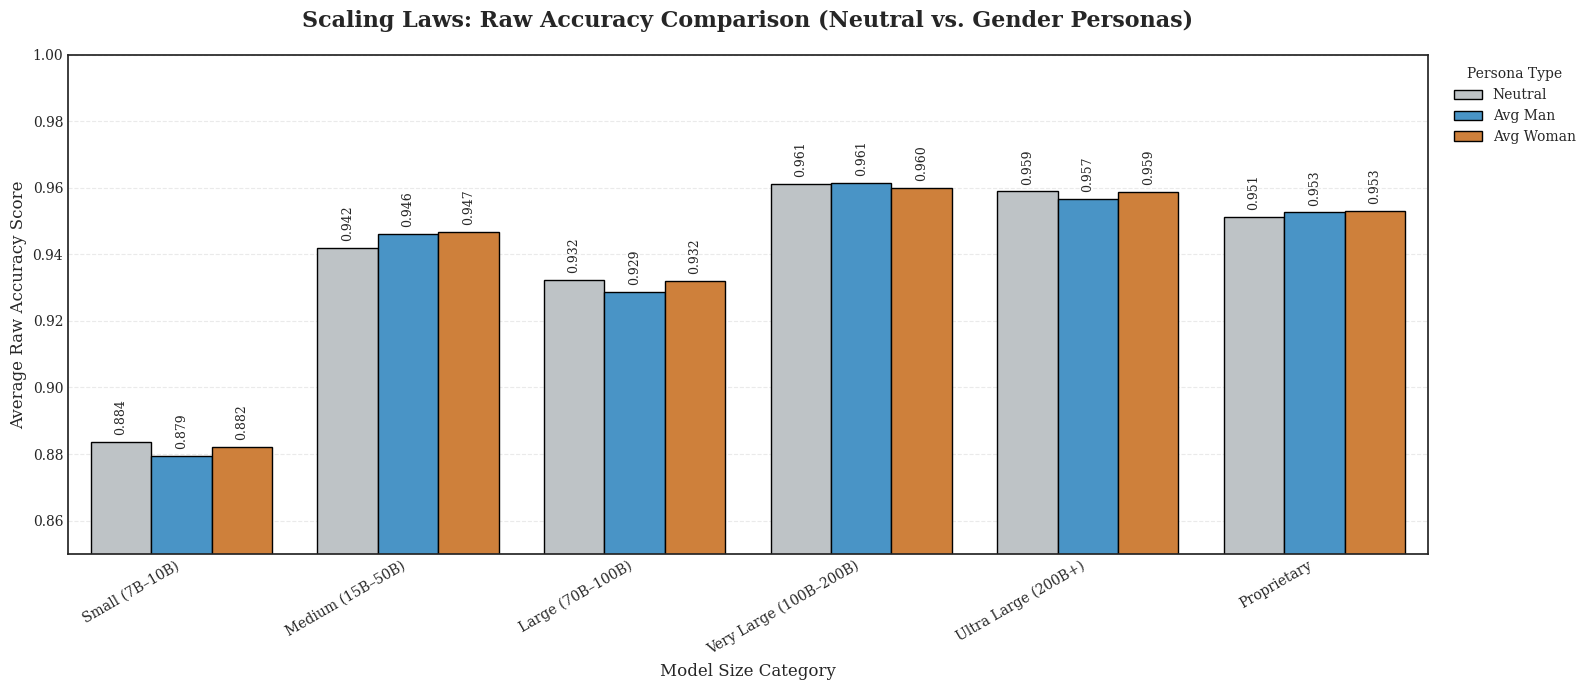

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# =============================================================================
# DATA PREPARATION FOR GROUPED BAR CHART
# =============================================================================
# Ensure size_cat_map is available from previous cells
# df_pivot should also be available from previous cells

df_temp = df_pivot.copy()

# Add Size_Category to the temporary DataFrame
df_temp['Size_Category'] = df_temp.index.map(size_cat_map)

# Calculate 'Avg Man' and 'Avg Woman' as they are needed for plotting and palette
df_temp['Avg Man'] = (df_temp['Man Explicit'] + df_temp['Man Implicit (Avg)']) / 2
df_temp['Avg Woman'] = (df_temp['Woman Explicit'] + df_temp['Woman Implicit (Avg)']) / 2

# Reset the index so 'Model' becomes a regular column
df_temp = df_temp.reset_index()

# Melt the DataFrame to prepare for seaborn.barplot
# This creates 'Persona_Type' and 'Raw_Accuracy' columns from 'Neutral', 'Avg Man', 'Avg Woman'
df_raw_melt = df_temp.melt(
    id_vars=['Model', 'Size_Category'],
    value_vars=['Neutral', 'Avg Man', 'Avg Woman'],
    var_name='Persona_Type',
    value_name='Raw_Accuracy'
)

# Define the logical order for the X-axis (from smallest to proprietary)
size_order = [
    'Small (7B–10B)', 'Medium (15B–50B)',
    'Large (70B–100B)', 'Very Large (100B–200B)', 'Ultra Large (200B+)', 'Proprietary'
]
# Ensure Size_Category is a categorical type with the correct order
df_raw_melt['Size_Category'] = pd.Categorical(df_raw_melt['Size_Category'], categories=size_order, ordered=True)

# =============================================================================
# VISUALIZATION: GROUPED BAR CHART FOR SCALING LAWS
# =============================================================================
# Thinking ahead: Use a wide figure size so the grouped bars have enough room to breathe
plt.figure(figsize=(16, 7), dpi=100)

# Define a clean, semantic color palette
palette_raw = {
    'Neutral': '#bdc3c7',     # Soft Gray
    'Avg Man': '#3498db',     # Professional Blue
    'Avg Woman': '#e67e22'    # Distinct Orange
}

# Cermat upgrade: Grouped Bar Chart instead of Line Plot.
# This eliminates text overlapping and clearly separates the 3 personas per size category.
ax = sns.barplot(
    data=df_raw_melt,
    x='Size_Category',
    y='Raw_Accuracy',
    hue='Persona_Type',
    palette=palette_raw,
    edgecolor='black',
    errorbar=None # Keep it clean, we just want the averages
)

# Focus the Y-axis on the top tier (0.85 to 1.0) since the scores are very high.
# This makes the microscopic differences much easier to see.
plt.ylim(0.85, 1.0)

# Thinking far: Automatically annotate the bars using ax.containers
# This is the safest way to annotate grouped bar charts without overlapping
for container in ax.containers:
    # Rotate text 90 degrees and use 3 decimals to maintain a clean, uncluttered look
    ax.bar_label(container, fmt='%.3f', padding=5, fontsize=9, rotation=90)

# Formatting the chart for maximum readability and academic standards
plt.title('Scaling Laws: Raw Accuracy Comparison (Neutral vs. Gender Personas)', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Average Raw Accuracy Score', fontsize=12)
plt.xlabel('Model Size Category', fontsize=12)

# Fix x-axis labels layout so they don't overlap
plt.xticks(rotation=30, ha='right')

# Add a subtle horizontal grid to guide the eye
plt.grid(axis='y', linestyle='--', alpha=0.4)

# Place legend neatly outside the plot area
plt.legend(title='Persona Type', bbox_to_anchor=(1.01, 1), loc='upper left')

plt.tight_layout()
plt.show()

### 📊 Chart Explanation: Raw Accuracy Scaling Laws (Grouped Bar Chart)

**How to Read the Chart:**
* **The Bar Clusters:** Each cluster represents a specific model size category (from Small to Proprietary).
* **The Colors:** Within each cluster, you can directly compare the model's baseline intelligence (**Grey/Neutral**), its performance as a **Blue/Man**, and as an **Orange/Woman**.
* **The Y-Axis:** Starts at 0.85 to emphasize the subtle performance differences at the highest echelons of accuracy.

**Key Insights:**

1. **The "Persona Boost" Phenomenon:** Look at the clusters across almost all size categories. Often, the Blue and Orange bars are taller than the Grey bar. This visually confirms that assigning a specific demographic persona acts as a reasoning catalyst, helping the model perform better than its default neutral state.

2. **Persistent Gender Discrepancy:** Even as models grow massive (e.g., Ultra Large and Proprietary), the Blue and Orange bars rarely reach the exact same height. This indicates that scaling up parameter counts does not naturally harmonize or erase gender-based performance gaps.

3. **Scaling Trends:** Generally, moving from left (Small) to right (Proprietary), the overall height of the clusters increases, validating the standard scaling law that larger models achieve higher baseline accuracy.

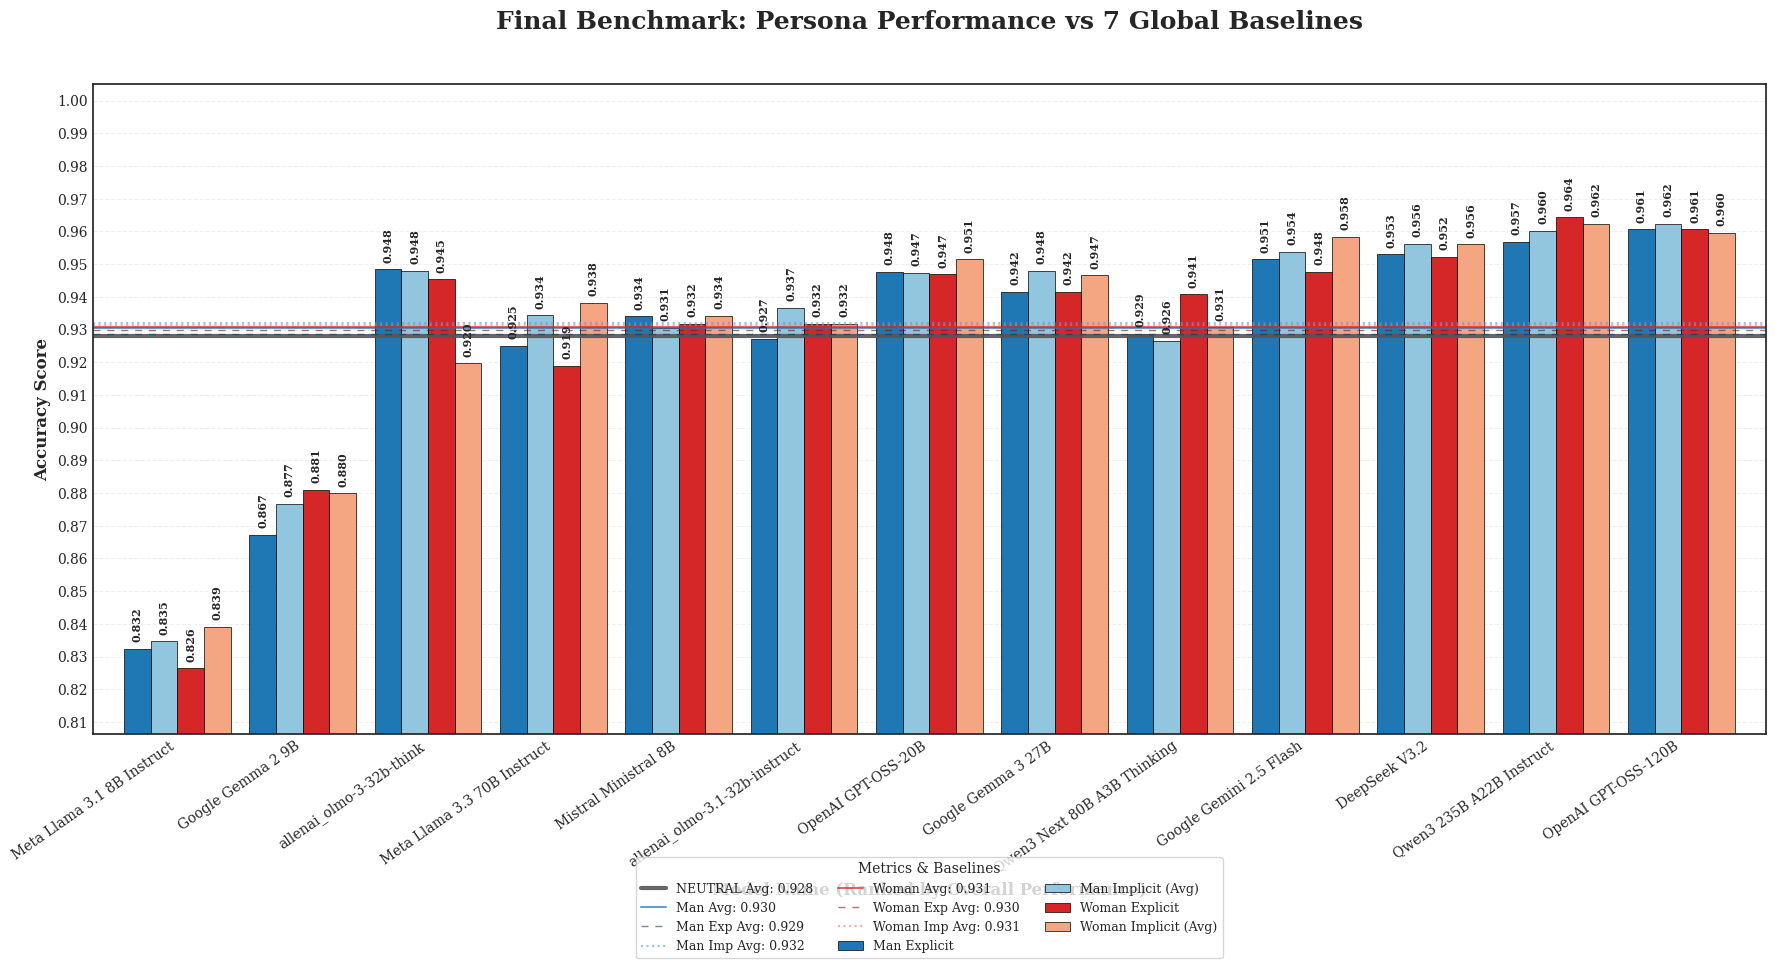

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# --- PREPARATION: Calculating ALL Baselines including Neutral ---
# 1. Individual Persona Means
man_exp_mean = df_sorted['Man Explicit'].mean()
man_imp_mean = df_sorted['Man Implicit (Avg)'].mean()
woman_exp_mean = df_sorted['Woman Explicit'].mean()
woman_imp_mean = df_sorted['Woman Implicit (Avg)'].mean()

# 2. Gender Group Means
man_avg_mean = df_sorted[['Man Explicit', 'Man Implicit (Avg)']].mean(axis=1).mean()
woman_avg_mean = df_sorted[['Woman Explicit', 'Woman Implicit (Avg)']].mean(axis=1).mean()

# 3. THE NEUTRAL ANCHOR (New Addition)
neutral_avg_mean = df_sorted['Neutral'].mean()

# --- STYLING SETUP ---
plt.rcParams['font.family'] = 'serif'
colors = ['#1f77b4', '#92c5de', '#d62728', '#f4a582']
column_order = ['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']

fig, ax = plt.subplots(figsize=(18, 10), dpi=100)

# --- PLOTTING ---
df_sorted[column_order].plot(kind='bar', ax=ax, width=0.85, color=colors, edgecolor='black', linewidth=0.5)

# --- FEATURE: VERTICAL ANNOTATIONS ---
for p in ax.patches:
    height = p.get_height()
    if pd.notna(height) and height > 0:
        ax.annotate(f'{height:.3f}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    xytext=(0, 5),
                    textcoords='offset points',
                    fontsize=8,
                    fontweight='bold',
                    rotation=90)

# --- DYNAMIC Y-LIMIT: PREVENTING GEMMA & LLAMA FROM DROWNING ---
all_bar_heights = [p.get_height() for p in ax.patches if pd.notna(p.get_height()) and p.get_height() > 0]
final_y_min = min(all_bar_heights) - 0.02  # Dynamic padding
final_y_max = 1.005

ax.set_ylim(final_y_min, final_y_max)
plt.yticks(np.arange(round(final_y_min, 2), final_y_max, 0.01))

# --- FEATURE: 7 BASELINES (NOW INCLUDING NEUTRAL) ---
# 1. NEUTRAL BASELINE (The Main Anchor)
ax.axhline(neutral_avg_mean, color='#555555', linestyle='-', linewidth=3, alpha=0.9,
           label=f'NEUTRAL Avg: {neutral_avg_mean:.3f}')

# 2. MAN GROUP
ax.axhline(man_avg_mean, color='#1f77b4', linestyle='-', linewidth=1.5, alpha=0.7, label=f'Man Avg: {man_avg_mean:.3f}')
ax.axhline(man_exp_mean, color='#0b3d59', linestyle=(0, (5, 5)), linewidth=1, alpha=0.6, label=f'Man Exp Avg: {man_exp_mean:.3f}')
ax.axhline(man_imp_mean, color='#4ba3d1', linestyle=':', linewidth=1.5, alpha=0.6, label=f'Man Imp Avg: {man_imp_mean:.3f}')

# 3. WOMAN GROUP
ax.axhline(woman_avg_mean, color='#d62728', linestyle='-', linewidth=1.5, alpha=0.7, label=f'Woman Avg: {woman_avg_mean:.3f}')
ax.axhline(woman_exp_mean, color='#7a1616', linestyle=(0, (5, 5)), linewidth=1, alpha=0.6, label=f'Woman Exp Avg: {woman_exp_mean:.3f}')
ax.axhline(woman_imp_mean, color='#e87a7a', linestyle=':', linewidth=1.5, alpha=0.6, label=f'Woman Imp Avg: {woman_imp_mean:.3f}')

# --- COSMETICS ---
ax.set_title('Final Benchmark: Persona Performance vs 7 Global Baselines', fontsize=18, pad=40, fontweight='bold')
ax.set_ylabel('Accuracy Score', fontsize=12, fontweight='bold')
ax.set_xlabel('Model Name (Ranked by Overall Performance)', fontsize=12, fontweight='bold')

# Legend: Extended to 3 columns to accommodate the Neutral line
ax.legend(title='Metrics & Baselines', frameon=True, facecolor='white',
          loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=9)

plt.xticks(rotation=35, ha='right', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

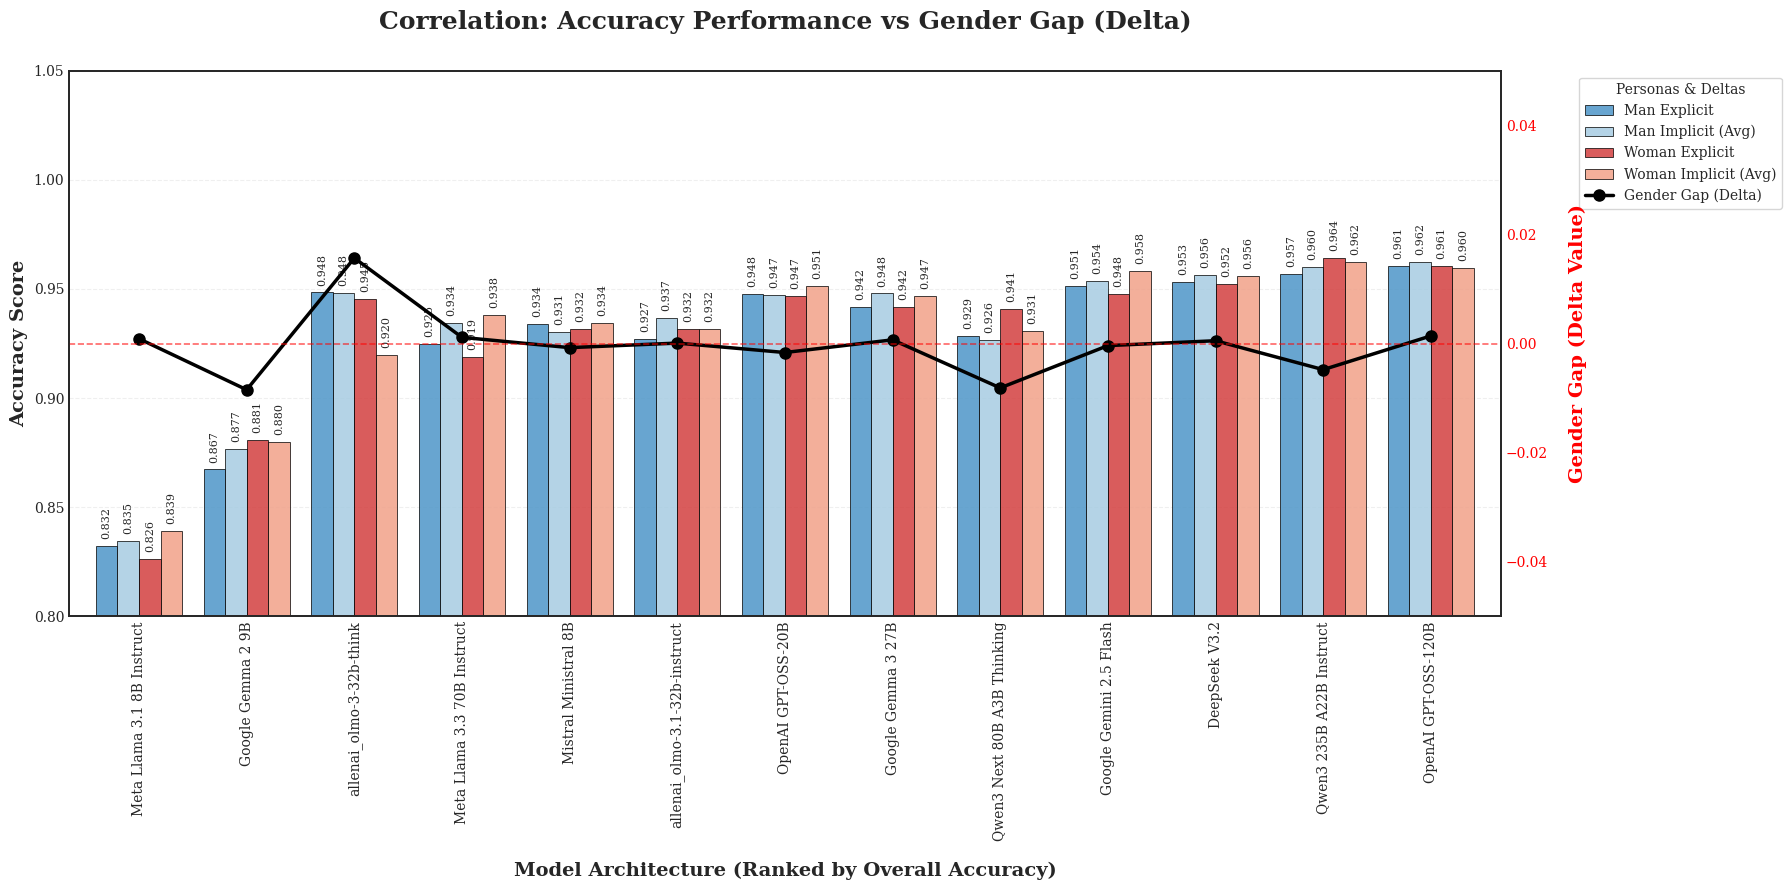

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# --- PREPARATION ---
# We use df_sorted (which we ranked by overall accuracy earlier)
# To make the chart tell a story of "Performance vs. Bias"
column_order = ['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']
colors = ['#4e96c8', '#a7cce2', '#d33f3f', '#f1a189'] # Clean blue-red palette

fig, ax1 = plt.subplots(figsize=(18, 9), dpi=100)
plt.rcParams['font.family'] = 'serif'

# --- AXIS 1: ACCURACY BARS ---
df_sorted[column_order].plot(kind='bar', ax=ax1, width=0.8, color=colors, edgecolor='black', linewidth=0.6, alpha=0.85)

# Setting limits for Accuracy (Left Y-Axis)
ax1.set_ylim(0.80, 1.05)
ax1.set_ylabel('Accuracy Score', fontsize=14, fontweight='bold')
ax1.set_xlabel('Model Architecture (Ranked by Overall Accuracy)', fontsize=14, fontweight='bold', labelpad=15)

# --- AXIS 2: GENDER GAP LINE (THE DELTA) ---
ax2 = ax1.twinx() # Create the dual axis
# Thinking far: Assigning a different color to the secondary axis for clarity
ax2.plot(range(len(df_sorted)), df_sorted['Gender Gap (Man-Woman)'],
         color='black', marker='o', markersize=8, linewidth=2.5, label='Gender Gap (Delta)')

# Setting limits for Delta (Right Y-Axis)
# We center 0.00 so the red dashed line is perfectly in the middle
ax2.set_ylim(-0.05, 0.05)
ax2.set_ylabel('Gender Gap (Delta Value)', fontsize=14, fontweight='bold', color='red', labelpad=15)
ax2.tick_params(axis='y', labelcolor='red')

# Ideal Neutrality Line (0.00)
ax2.axhline(0, color='red', linestyle='--', linewidth=1.2, alpha=0.6)

# --- ANNOTATIONS (BAR LABELS) ---
for p in ax1.patches:
    h = p.get_height()
    if h > 0:
        ax1.annotate(f'{h:.3f}', (p.get_x() + p.get_width()/2., h),
                     ha='center', va='bottom', xytext=(0, 5),
                     textcoords='offset points', fontsize=8, rotation=90)

# --- COSMETICS ---
ax1.set_title('Correlation: Accuracy Performance vs Gender Gap (Delta)', fontsize=18, fontweight='bold', pad=30)

# Cleaning Grids: Only keep horizontal ones for readability
ax1.grid(axis='y', linestyle='--', alpha=0.3)
ax1.grid(axis='x', visible=False) # Cermat: Remove vertical grids

# Legends Management
# Combining legends from both axes to show them together
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, title='Personas & Deltas',
           loc='upper left', bbox_to_anchor=(1.05, 1), frameon=True)

plt.xticks(rotation=45, ha='right', fontsize=10)
plt.tight_layout()
plt.show()

## Token Usage

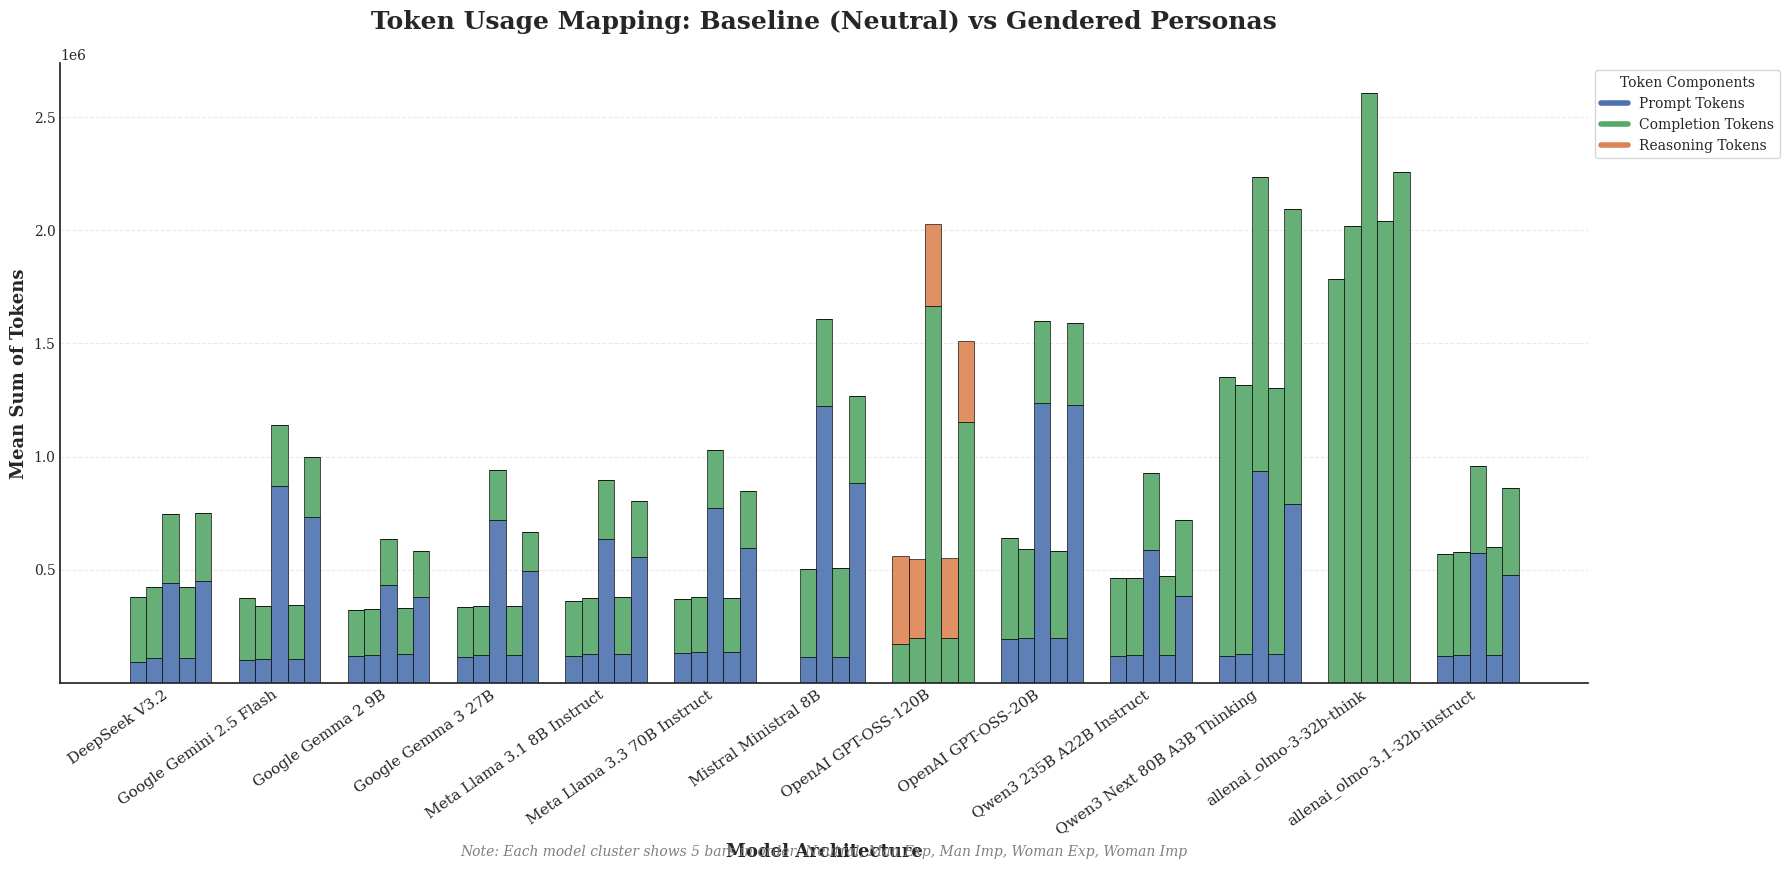

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

# 2. Calculate Mean for Token Components (Sama seperti kodemu)
token_cols = ['Sum_Prompt_Tokens', 'Sum_Completion_Tokens', 'Sum_Reasoning_Tokens']
df_token_avg = df_full.groupby(['Model', 'Category'])[token_cols].mean().reset_index()
df_token_avg['Total_Calc'] = df_token_avg[token_cols].sum(axis=1)

# 3. Setup for Visualization
models = df_token_avg['Model'].unique()
# Urutan 5 batang: Neutral dulu baru yang lainnya
categories = ['Neutral', 'Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']

# Professional Colors
colors = ['#4C72B0', '#55A868', '#DD8452']

# 4. Create the Plot
fig, ax = plt.subplots(figsize=(18, 9), dpi=100)

x = np.arange(len(models))
width = 0.15  # Abel: Lebar dikecilkan sedikit agar 5 batang muat rapi

for i, cat in enumerate(categories):
    # Filter data untuk kategori ini
    cat_data = df_token_avg[df_token_avg['Category'] == cat].set_index('Model').reindex(models).fillna(0)

    # Perubahan Posisi: Karena ada 5 batang (i=0..4),
    # titik tengahnya adalah i=2. Maka offsetnya (i - 2)
    pos = x + (i - 2) * width

    # Bottom for stacking
    bottom_val = np.zeros(len(models))

    for j, col in enumerate(token_cols):
        ax.bar(pos, cat_data[col], width, bottom=bottom_val,
               label=col.replace('Sum_', '').replace('_Tokens', '') if i == 0 else "",
               color=colors[j], edgecolor='black', linewidth=0.5, alpha=0.9)
        bottom_val += cat_data[col].values

# 5. Styling & Professionalism
ax.set_title('Token Usage Mapping: Baseline (Neutral) vs Gendered Personas', fontsize=18, fontweight='bold', pad=25)
ax.set_ylabel('Mean Sum of Tokens', fontsize=13, fontweight='bold')
ax.set_xlabel('Model Architecture', fontsize=13, fontweight='bold')

# X-axis handling
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=35, ha='right', fontsize=11)

# Legend
legend_elements = [Line2D([0], [0], color=colors[0], lw=4, label='Prompt Tokens'),
                   Line2D([0], [0], color=colors[1], lw=4, label='Completion Tokens'),
                   Line2D([0], [0], color=colors[2], lw=4, label='Reasoning Tokens')]
ax.legend(handles=legend_elements, title='Token Components', frameon=True, loc='upper left', bbox_to_anchor=(1, 1))

# Update Note untuk 5 batang
note_text = 'Note: Each model cluster shows 5 bars in order: Neutral, Man Exp, Man Imp, Woman Exp, Woman Imp'
ax.text(0.5, -0.28, note_text, transform=ax.transAxes, ha='center', fontsize=10, style='italic', color='gray')

# Aesthetics
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.yaxis.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

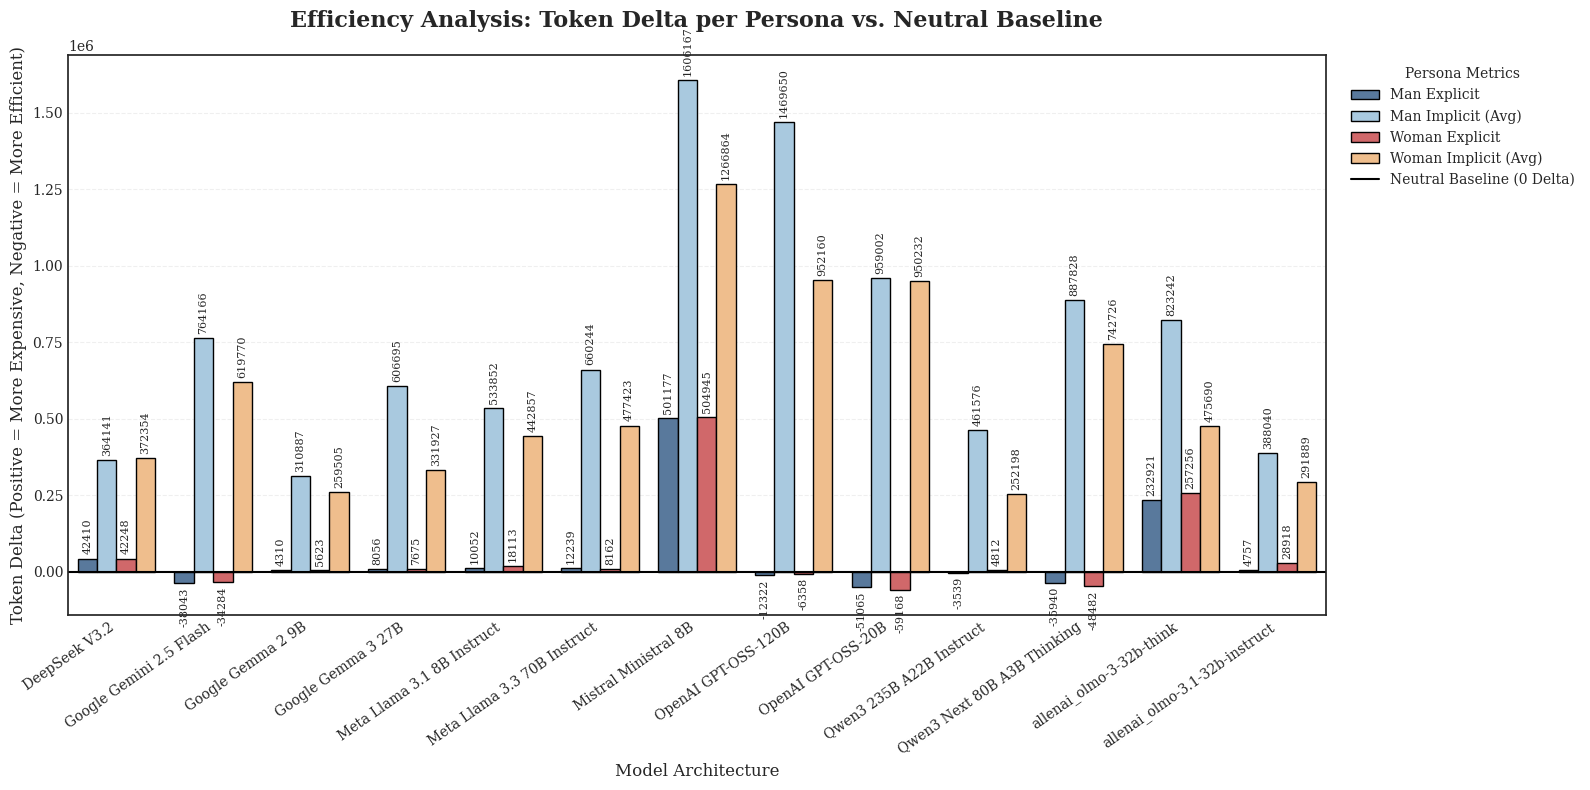

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# --- PREPARATION: Create df_influence ---
# 1. Get average total tokens for Neutral baseline per model
neutral_tokens = df_token_avg[df_token_avg['Category'] == 'Neutral'].set_index('Model')['Total_Calc']

# 2. Prepare accuracy and token data
df_influence = df_full.copy()
df_influence['Total_Calc'] = df_influence[token_cols].sum(axis=1)

# 3. Calculate Token Delta (Persona Total Tokens - Neutral Total Tokens)
def calc_delta(row):
    base = neutral_tokens.get(row['Model'], 0)
    return row['Total_Calc'] - base

df_influence['Token_Delta'] = df_influence.apply(calc_delta, axis=1)

# Filter out Neutral for the bar chart comparison
df_bar = df_influence[df_influence['Category'] != 'Neutral']

# --- VISUALIZATION: BAR CHART ---
plt.figure(figsize=(16, 8), dpi=100)
plt.rcParams['font.family'] = 'serif'

# Define colors consistent with previous charts
persona_colors = {
    'Man Explicit': '#4e79a7',
    'Man Implicit (Avg)': '#a0cbe8',
    'Woman Explicit': '#e15759',
    'Woman Implicit (Avg)': '#ffbe7d'
}

ax = sns.barplot(
    data=df_bar,
    x='Model',
    y='Token_Delta',
    hue='Category',
    palette=persona_colors,
    edgecolor='black'
)

# Add horizontal line at 0 (Neutral Baseline)
plt.axhline(0, color='black', linewidth=1.5, label='Neutral Baseline (0 Delta)')

# Formatting
plt.title('Efficiency Analysis: Token Delta per Persona vs. Neutral Baseline', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Token Delta (Positive = More Expensive, Negative = More Efficient)', fontsize=12)
plt.xlabel('Model Architecture', fontsize=12)

# Annotate bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3, fontsize=8, rotation=90)

plt.xticks(rotation=35, ha='right')
plt.legend(title='Persona Metrics', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

## Model Size

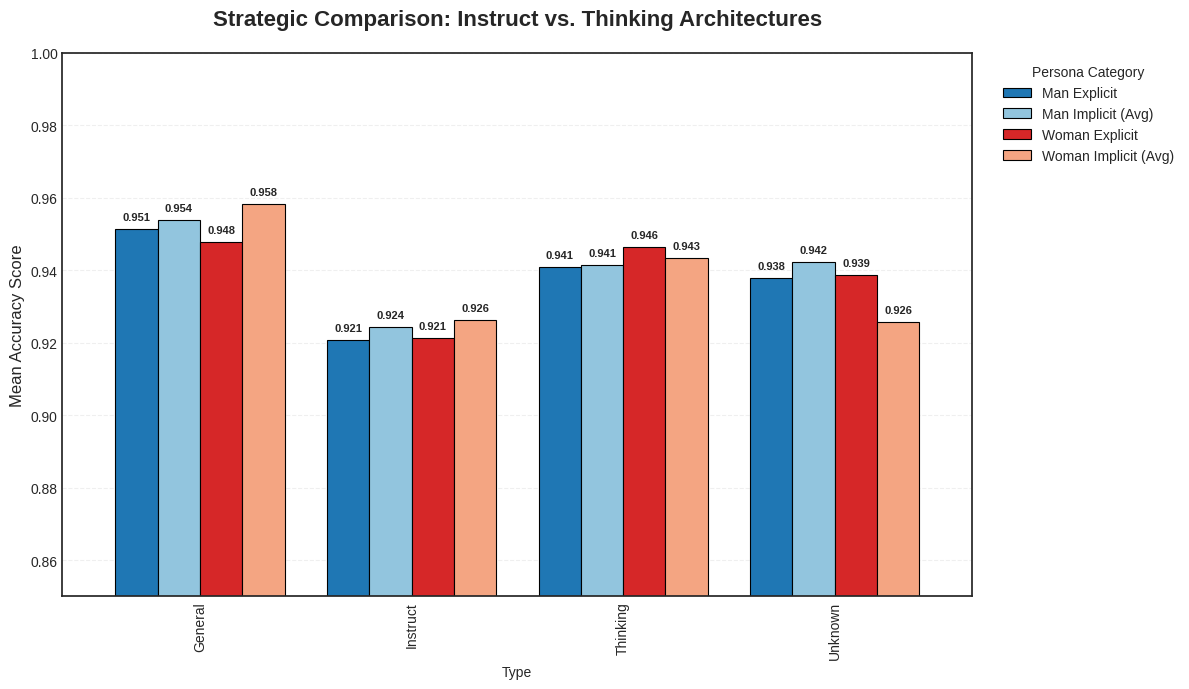

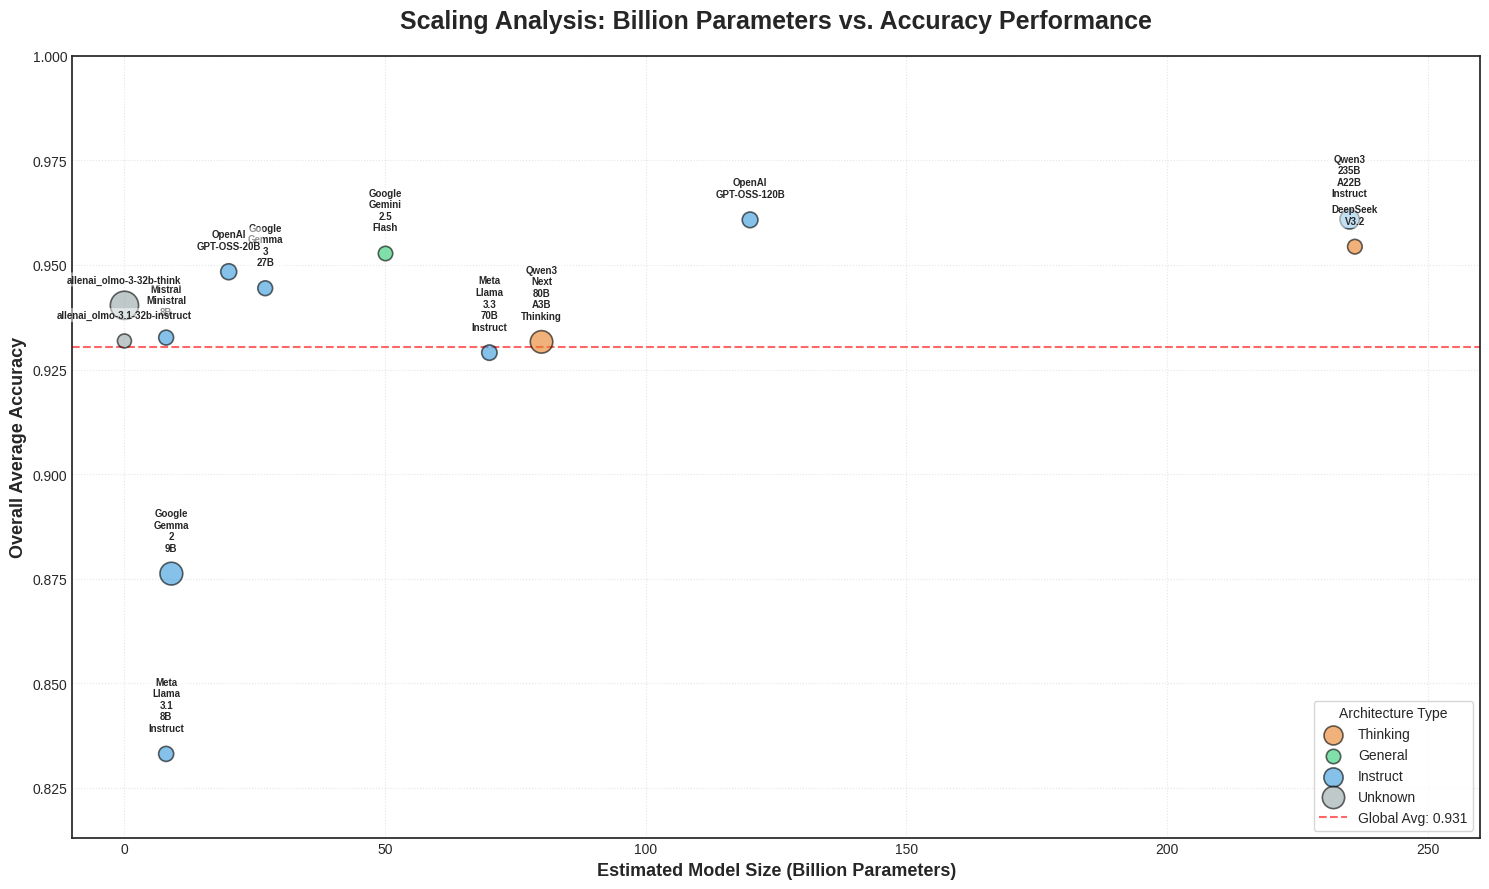

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

# =============================================================================
# 1. ENHANCED DATA MAPPING
# =============================================================================
size_mapping = {
    'OpenAI GPT-OSS-20B': {'Size': 20, 'Category': 'Medium', 'Type': 'Instruct'},
    'Qwen3 Next 80B A3B Thinking': {'Size': 80, 'Category': 'Large', 'Type': 'Thinking'},
    'Qwen3 235B A22B Instruct': {'Size': 235, 'Category': 'Ultra Large', 'Type': 'Instruct'},
    'OpenAI GPT-OSS-120B': {'Size': 120, 'Category': 'Very Large', 'Type': 'Instruct'},
    'Meta Llama 3.3 70B Instruct': {'Size': 70, 'Category': 'Large', 'Type': 'Instruct'},
    'Google Gemma 3 27B': {'Size': 27, 'Category': 'Medium', 'Type': 'Instruct'},
    'Google Gemma 2 9B': {'Size': 9, 'Category': 'Small', 'Type': 'Instruct'},
    'DeepSeek V3.2': {'Size': 236, 'Category': 'Ultra Large', 'Type': 'Thinking'},
    'Google Gemini 2.5 Flash': {'Size': 50, 'Category': 'Proprietary', 'Type': 'General'},
    'Meta Llama 3.1 8B Instruct': {'Size': 8, 'Category': 'Small', 'Type': 'Instruct'},
    'Mistral Ministral 8B': {'Size': 8, 'Category': 'Small', 'Type': 'Instruct'},
    'AllenAI OLMo 3 32B Think': {'Size': 32, 'Category': 'Medium', 'Type': 'Thinking'},
    'AllenAI OLMo 3.1 32B Instruct': {'Size': 32, 'Category': 'Medium', 'Type': 'Instruct'} # Added OLMo Instruct
}

df_plot_size = df_pivot.copy()
df_plot_size['Size_Num'] = df_plot_size.index.map(lambda x: size_mapping.get(x, {}).get('Size', 0))
df_plot_size['Type'] = df_plot_size.index.map(lambda x: size_mapping.get(x, {}).get('Type', 'Unknown'))
df_plot_size['Overall_Acc'] = df_plot_size[['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']].mean(axis=1)

# Tambahan: Hitung Gap untuk ukuran Bubble nanti
df_plot_size['Gender_Gap_Abs'] = abs(
    (df_plot_size['Man Explicit'] + df_plot_size['Man Implicit (Avg)'])/2 -
    (df_plot_size['Woman Explicit'] + df_plot_size['Woman Implicit (Avg)'])/2
)

# =============================================================================
# 2. VISUALIZE BY MODEL TYPE (WITH COLOR CONSISTENCY)
# =============================================================================
plt.style.use('seaborn-v0_8-white')
fig, ax = plt.subplots(figsize=(12, 7))

# Abel: We use the same colors as before for persona consistency
persona_colors = ['#1f77b4', '#92c5de', '#d62728', '#f4a582']
column_order = ['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']

df_type = df_plot_size.groupby('Type')[column_order].mean()

# Plot bars
df_type.plot(kind='bar', ax=ax, width=0.8, color=persona_colors, edgecolor='black', linewidth=0.8)

# Add value labels on top of bars
for p in ax.patches:
    ax.annotate(f'{p.get_height():.3f}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=8, fontweight='bold', xytext=(0, 5), textcoords='offset points')

ax.set_title('Strategic Comparison: Instruct vs. Thinking Architectures', fontsize=16, fontweight='bold', pad=20)
ax.set_ylabel('Mean Accuracy Score', fontsize=12)
ax.set_ylim(0.85, 1.0) # Zoomed in for better contrast
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.legend(title='Persona Category', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

# =============================================================================
# 3. ENHANCED BUBBLE CHART (Size vs. Acc vs. Type)
# =============================================================================
fig, ax = plt.subplots(figsize=(15, 9))

# Professional Palette
type_colors = {'Instruct': '#3498db', 'Thinking': '#e67e22', 'General': '#2ecc71', 'Unknown': '#95a5a6'}

for m_type in df_plot_size['Type'].unique():
    subset = df_plot_size[df_plot_size['Type'] == m_type]

    # Thinking far: Bubble size represents the Gender Gap (Magnitude of Bias)
    # Scaling factor 20000 for high visibility
    bubble_size = subset['Gender_Gap_Abs'] * 20000 + 100

    ax.scatter(subset['Size_Num'], subset['Overall_Acc'],
               s=bubble_size, label=m_type, color=type_colors.get(m_type, 'gray'),
               alpha=0.6, edgecolors='black', linewidth=1.2, zorder=3)

# Annotate with smart offsets to avoid overlap
for i, txt in enumerate(df_plot_size.index):
    x_val = df_plot_size['Size_Num'].iat[i]
    y_val = df_plot_size['Overall_Acc'].iat[i]

    # Split long model names for better look
    clean_name = txt.replace(' ', '\n')

    ax.annotate(clean_name, (x_val, y_val),
                fontsize=7, fontweight='bold', xytext=(0, 15),
                textcoords='offset points', ha='center', va='bottom',
                bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.5, ec='none'))

# Global Average Line
avg_acc = df_plot_size['Overall_Acc'].mean()
plt.axhline(avg_acc, color='red', linestyle='--', alpha=0.6, linewidth=1.5,
            label=f'Global Avg: {avg_acc:.3f}', zorder=1)

ax.set_title('Scaling Analysis: Billion Parameters vs. Accuracy Performance', fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Estimated Model Size (Billion Parameters)', fontsize=13, fontweight='bold')
ax.set_ylabel('Overall Average Accuracy', fontsize=13, fontweight='bold')

# Formatting
ax.set_xlim(-10, 260) # Padding for Ultra Large models
ax.set_ylim(df_plot_size['Overall_Acc'].min() - 0.02, 1.0)
ax.legend(title='Architecture Type', loc='lower right', frameon=True, fontsize=10)
ax.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
# 1. Ensure model type mapping exists
type_map = {
    'AllenAI OLMo 3 32B Think': 'Thinking',
    'DeepSeek V3.2': 'Thinking',
    'Qwen3 Next 80B A3B Thinking': 'Thinking',
    'OpenAI GPT-OSS-20B': 'Instruct',
    'OpenAI GPT-OSS-120B': 'Instruct',
    'Qwen3 235B A22B Instruct': 'Instruct',
    'Meta Llama 3.3 70B Instruct': 'Instruct',
    'Meta Llama 3.1 8B Instruct': 'Instruct',
    'Google Gemma 3 27B': 'Instruct',
    'Google Gemma 2 9B': 'Instruct',
    'Mistral Ministral 8B': 'Instruct',
    'Google Gemini 2.5 Flash': 'General',
    'AllenAI OLMo 3.1 32B Instruct': 'Instruct'
}

# 2. Create token summary per model
df_tokens_summary = df_full.groupby('Model')['Sum_Total_Tokens'].mean().reset_index()

# 3. Add Type info
df_tokens_summary['Model_Type'] = df_tokens_summary['Model'].map(type_map)

# 4. Get average Accuracy from the previously created df_pivot
df_tokens_summary = df_tokens_summary.set_index('Model')
df_tokens_summary['Avg_Accuracy'] = df_pivot[['Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']].mean(axis=1)

# Check the results
display(df_tokens_summary.head(12))

,Sum_Total_Tokens,Model_Type,Avg_Accuracy
Model,,,
DeepSeek V3.2,5.440466e+05,Thinking,0.954375
Google Gemini 2.5 Flash,6.385498e+05,General,0.952805
Google Gemma 2 9B,4.385451e+05,Instruct,0.876232
Google Gemma 3 27B,5.237986e+05,Instruct,0.944442
Meta Llama 3.1 8B Instruct,5.634339e+05,Instruct,0.833144
Meta Llama 3.3 70B Instruct,5.999195e+05,Instruct,0.929050
Mistral Ministral 8B,7.758306e+05,Instruct,0.932647
OpenAI GPT-OSS-120B,0.000000e+00,Instruct,0.960783
OpenAI GPT-OSS-20B,1.000875e+06,Instruct,0.948383


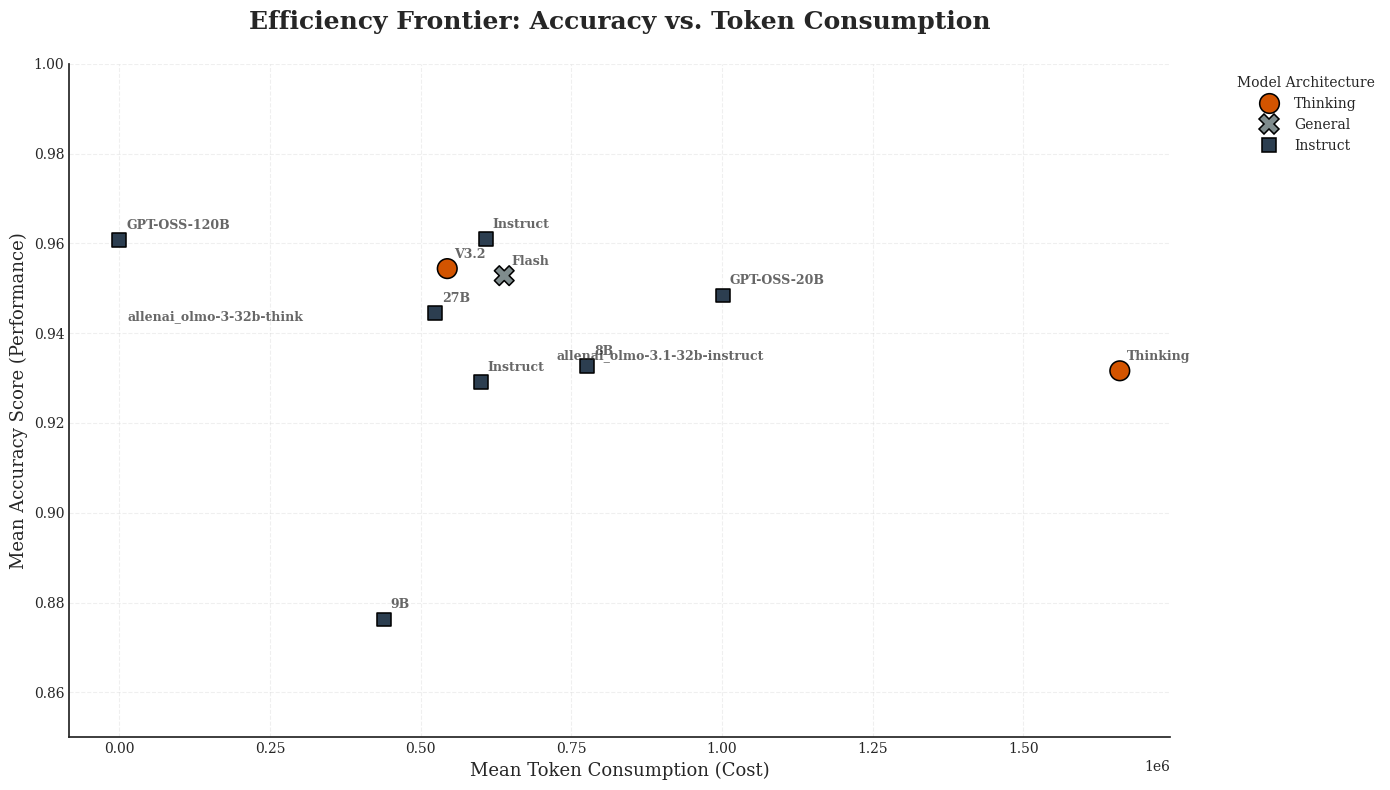

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.family'] = 'serif'
fig, ax = plt.subplots(figsize=(14, 8), dpi=100)

# Professional colors
palette = {'Instruct': '#2c3e50', 'Thinking': '#d35400', 'General': '#7f8c8d'}

# Plot Scatter
sns.scatterplot(
    data=df_tokens_summary,
    x='Sum_Total_Tokens',
    y='Avg_Accuracy',
    hue='Model_Type',
    style='Model_Type',
    palette=palette,
    s=200,
    edgecolor='black',
    ax=ax,
    zorder=3
)

# Add model name labels
for i in range(len(df_tokens_summary)):
    ax.annotate(
        df_tokens_summary.index[i].split(' ')[-1], # Take the last word for brevity
        (df_tokens_summary['Sum_Total_Tokens'].iat[i], df_tokens_summary['Avg_Accuracy'].iat[i]),
        xytext=(5, 8), textcoords='offset points',
        fontsize=9, fontweight='bold', alpha=0.7
    )

# Journal-style Formatting
ax.set_ylim(0.85, 1.0) # Focus on high accuracy
ax.set_title('Efficiency Frontier: Accuracy vs. Token Consumption', fontsize=18, pad=25, fontweight='bold')
ax.set_xlabel('Mean Token Consumption (Cost)', fontsize=13)
ax.set_ylabel('Mean Accuracy Score (Performance)', fontsize=13)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, linestyle='--', alpha=0.3)

plt.legend(title='Model Architecture', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
# 1. Calculate Mean and Std from raw data (Neutral included)
# Pastikan 'Neutral' ada di kolom Category
df_stats = df_full.groupby(['Model', 'Category'])['Accuracy'].agg(['mean', 'std']).reset_index()

# 2. Pivot for Mean and Std
df_mean = df_stats.pivot(index='Model', columns='Category', values='mean')
df_std = df_stats.pivot(index='Model', columns='Category', values='std')

# Abel: Masukkan Neutral di urutan pertama sebagai benchmark
column_order = ['Neutral', 'Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']

# Reindex hanya kolom yang ada untuk menghindari error
existing_cols = [col for col in column_order if col in df_mean.columns]
df_mean = df_mean[existing_cols]
df_std = df_std[existing_cols].fillna(0)

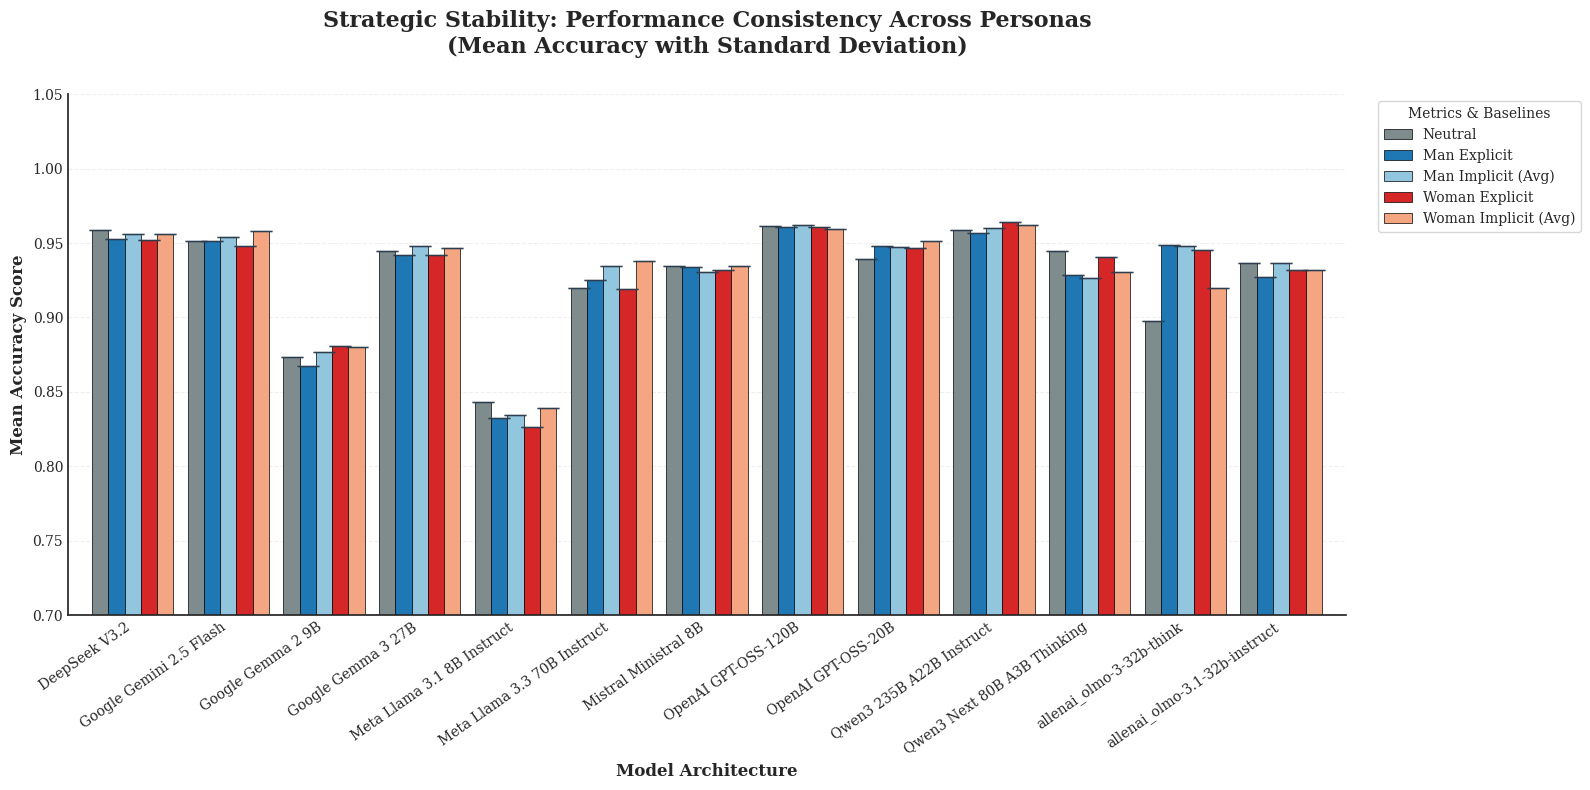

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# =============================================================================
# 1. DATA PREPARATION (LOGIKA MEAN & STD)
# =============================================================================

# Abel, pastikan df_full adalah dataframe mentah yang berisi semua percobaanmu
# Kita hitung statistik dasar untuk Accuracy
df_stats = df_full.groupby(['Model', 'Category'])['Accuracy'].agg(['mean', 'std']).reset_index()

# Pivot data untuk Mean dan Standard Deviation
df_mean = df_stats.pivot(index='Model', columns='Category', values='mean')
df_std = df_stats.pivot(index='Model', columns='Category', values='std')

# Menentukan urutan kolom agar 'Neutral' menjadi baseline di paling kiri
column_order = ['Neutral', 'Man Explicit', 'Man Implicit (Avg)', 'Woman Explicit', 'Woman Implicit (Avg)']

# Filter hanya kolom yang benar-benar ada di dataframe untuk menghindari error
existing_cols = [col for col in column_order if col in df_mean.columns]
df_mean = df_mean[existing_cols]
df_std = df_std[existing_cols].fillna(0) # Jika Std tidak ada (data tunggal), kita set 0

# =============================================================================
# 2. VISUALIZATION (ERROR BARS FOCUS)
# =============================================================================

plt.rcParams['font.family'] = 'serif'
fig, ax = plt.subplots(figsize=(16, 8), dpi=100)

# Professional colors: Abu-abu untuk Neutral, Biru untuk Man, Merah/Oranye untuk Woman
colors = ['#7f8c8d', '#1f77b4', '#92c5de', '#d62728', '#f4a582']

# Plot Bar dengan Error Bars
# Abel, aku pertegas elinewidth dan capsize-nya agar 'kumis' grafiknya terlihat tajam
df_mean.plot(kind='bar', ax=ax, width=0.85, color=colors,
             edgecolor='black', linewidth=0.5,
             yerr=df_std,
             capsize=8,
             error_kw={'elinewidth':2.0, 'ecolor':'#2c3e50', 'alpha':0.8})

# Focus Scale: Mulai dari 0.7 agar variansi terlihat lebih signifikan
ax.set_ylim(0.7, 1.05)

# Penamaan yang lebih akademis untuk paper/tesis
ax.set_title('Strategic Stability: Performance Consistency Across Personas\n(Mean Accuracy with Standard Deviation)',
             fontsize=16, fontweight='bold', pad=30)
ax.set_ylabel('Mean Accuracy Score', fontsize=12, fontweight='bold')
ax.set_xlabel('Model Architecture', fontsize=12, fontweight='bold')

# Styling & Grid
ax.yaxis.grid(True, linestyle='--', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Memastikan label sumbu X terbaca jelas
plt.xticks(rotation=35, ha='right', fontsize=10)

# Legend Configuration
ax.legend(title='Metrics & Baselines', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

In [ ]:
# 1. Pastikan df_stats sudah terhitung (Mean & Std)
df_stats = df_full.groupby(['Model', 'Category'])['Accuracy'].agg(['mean', 'std']).reset_index()

# 2. Filter: Implicit + Neutral (Sebagai Baseline)
# Berpikir jauh: Memasukkan Neutral untuk melihat 'gap' efisiensi
target_categories = ['Neutral', 'Man Implicit (Avg)', 'Woman Implicit (Avg)']
df_filtered_stats = df_stats[df_stats['Category'].isin(target_categories)]

# 3. Re-pivot
df_mean_imp = df_filtered_stats.pivot(index='Model', columns='Category', values='mean')
df_std_imp = df_filtered_stats.pivot(index='Model', columns='Category', values='std').fillna(0)

# 4. Sorting Columns (Urutan Baseline dulu)
# Abel, pastikan Neutral di paling kiri agar perbandingannya enak dilihat
col_order = ['Neutral', 'Man Implicit (Avg)', 'Woman Implicit (Avg)']
df_mean_imp = df_mean_imp[col_order]
df_std_imp = df_std_imp[col_order]

# Tampilkan hasil untuk verifikasi
display(df_mean_imp.head())

Category,Neutral,Man Implicit (Avg),Woman Implicit (Avg)
Model,,,
DeepSeek V3.2,0.958900,0.956267,0.956033
Google Gemini 2.5 Flash,0.951331,0.953753,0.958302
Google Gemma 2 9B,0.873293,0.876674,0.879960
Google Gemma 3 27B,0.944600,0.947941,0.946584
Meta Llama 3.1 8B Instruct,0.843063,0.834723,0.839020


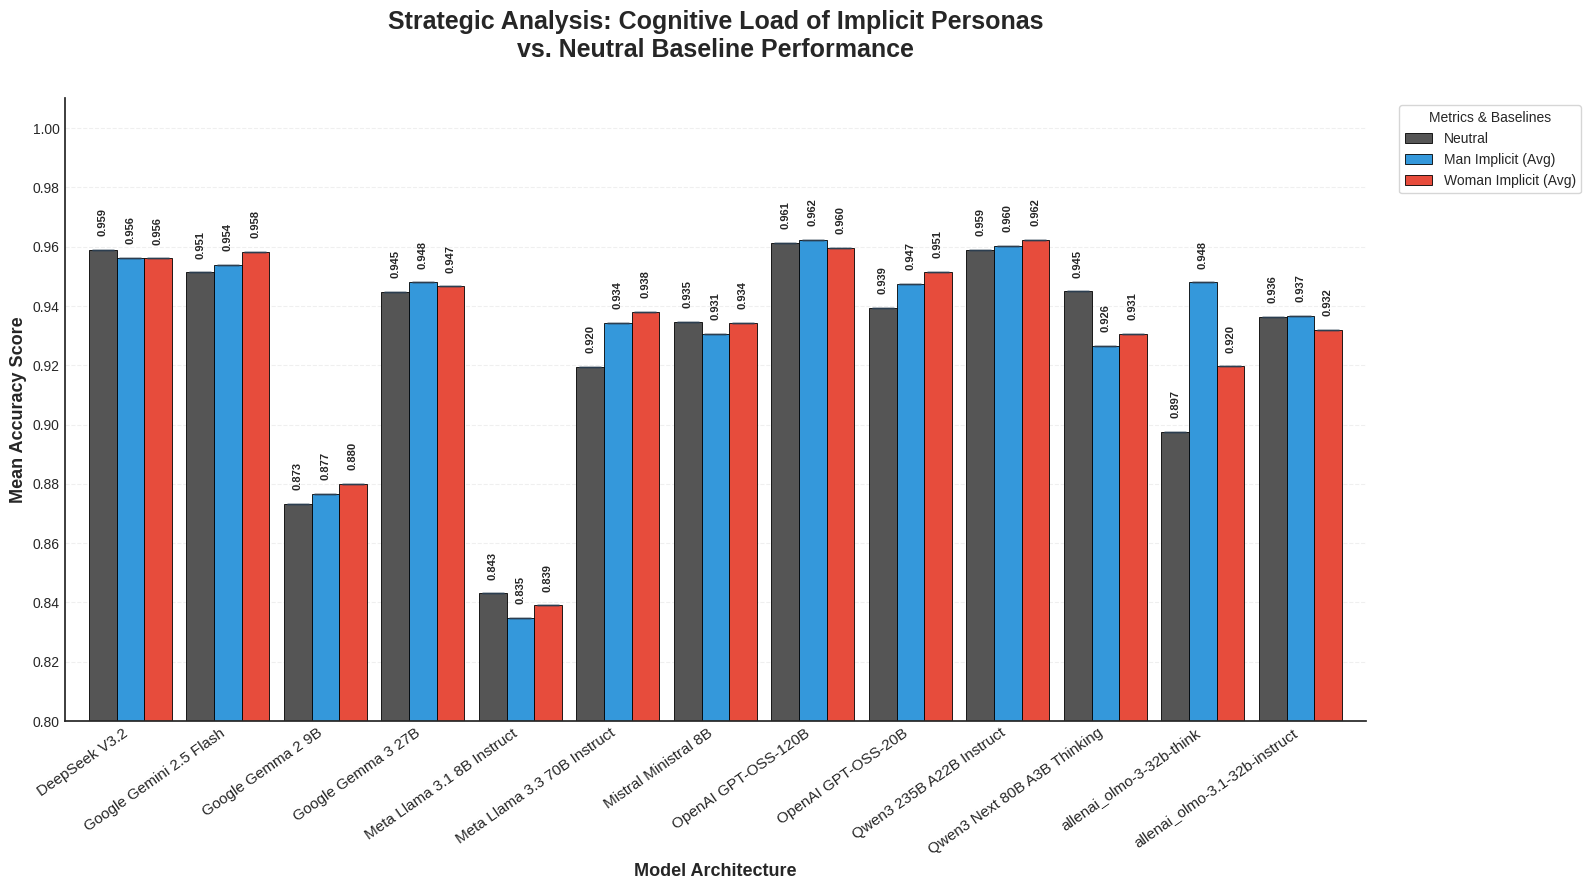

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# =============================================================================
# VISUALIZATION: IMPLICIT VS NEUTRAL BASELINE
# =============================================================================

# Abel: Menggunakan gaya serif agar terlihat akademis dan profesional
plt.rcParams['font.family'] = 'serif'
plt.style.use('seaborn-v0_8-white')
fig, ax = plt.subplots(figsize=(16, 9), dpi=100)

# Abel: Kita gunakan warna yang kontras terhadap Neutral
# Abu-abu Tua untuk Neutral (Anchor), Biru Terang untuk Man Imp, Merah Terang untuk Woman Imp
colors = ['#555555', '#3498db', '#e74c3c']

# Cermat: Pastikan urutan plotting sama dengan 'col_order' di langkah sebelumnya
# ['Neutral', 'Man Implicit (Avg)', 'Woman Implicit (Avg)']
df_mean_imp.plot(kind='bar', ax=ax, width=0.85, color=colors,
                 edgecolor='black', linewidth=0.6,
                 yerr=df_std_imp, capsize=8, # 'Kumis' (error bars) dipertegas
                 error_kw={'elinewidth':1.8, 'ecolor':'#2c3e50'})

# =============================================================================
# SCALE & CLUTTER REDUCTION
# =============================================================================

# Berpikir jauh: Zoom skala Y agar perbandingan desimal kecil terlihat signifikan
ax.set_ylim(0.80, 1.01) # Mulai dari 0.8 agar perbedaan 1-2% terlihat nyata
plt.yticks(np.arange(0.80, 1.01, 0.02)) # Garis grid setiap 0.02 untuk akurasi

# Judul yang akademis untuk tesis
ax.set_title('Strategic Analysis: Cognitive Load of Implicit Personas\nvs. Neutral Baseline Performance',
             fontsize=18, fontweight='bold', pad=30)
ax.set_ylabel('Mean Accuracy Score', fontsize=13, fontweight='bold')
ax.set_xlabel('Model Architecture', fontsize=13, fontweight='bold')

# Annotations (Accuracy Labels)
# Thinking far: Agar tidak menumpuk, kita hanya beri label jika batang terlihat penuh
for p in ax.patches:
    height = p.get_height()
    if pd.notna(height) and height > 0:
        ax.annotate(f'{height:.3f}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    xytext=(0, 10), # Posisi label sedikit di atas batang
                    textcoords='offset points',
                    fontsize=8,
                    fontweight='bold',
                    rotation=90) # Diputar 90 derajat agar tidak saling tabrak

# Aesthetics
ax.yaxis.grid(True, linestyle='--', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Memastikan label model di sumbu X terbaca jelas
plt.xticks(rotation=35, ha='right', fontsize=11)

# Legend di luar agar tidak menutupi batang
ax.legend(title='Metrics & Baselines', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

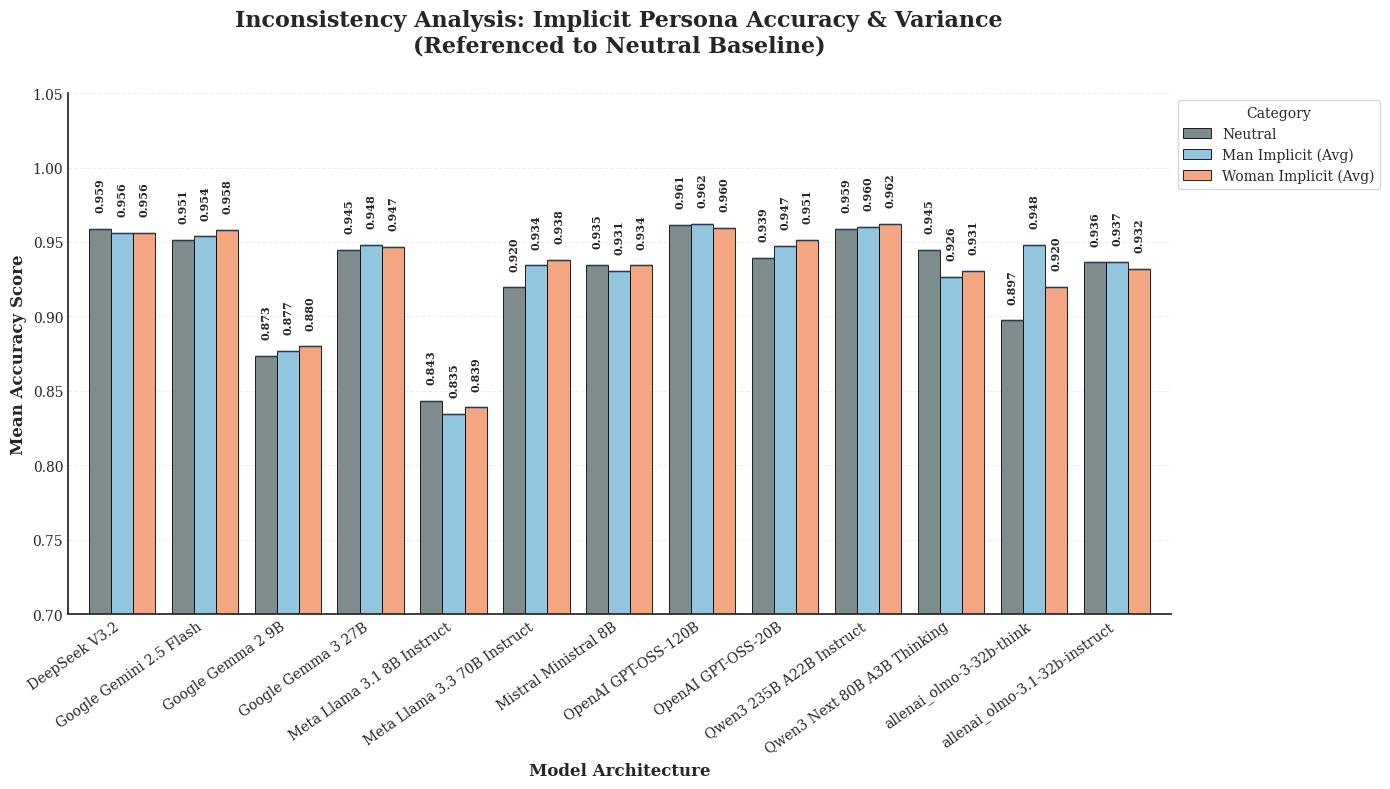

In [ ]:
import matplotlib.pyplot as plt

# --- PREPARATION ---
plt.rcParams['font.family'] = 'serif'
fig, ax = plt.subplots(figsize=(14, 8), dpi=100)

# Berpikir Cermat: Kita butuh 3 warna karena ada Neutral + 2 Implicits
# Abu-abu (Neutral), Biru Muda (Man Imp), Oranye Muda (Woman Imp)
colors_imp_full = ['#7f8c8d', '#92c5de', '#f4a582']

# Plot Bar with Error Bars (yerr=df_std_imp)
# Abel, pastikan df_mean_imp punya 3 kolom sesuai col_order sebelumnya
df_mean_imp.plot(kind='bar', ax=ax, width=0.8, color=colors_imp_full,
                 edgecolor='black', linewidth=0.6,
                 yerr=df_std_imp, capsize=8,
                 error_kw={'elinewidth':2, 'ecolor':'#2c3e50', 'alpha':0.8})

# --- SCALE & STYLING ---
# Abel, aku atur skalanya agar 'kumis' (variance) terlihat lebih dramatis
ax.set_ylim(0.70, 1.05)

ax.set_title('Inconsistency Analysis: Implicit Persona Accuracy & Variance\n(Referenced to Neutral Baseline)',
             fontsize=16, fontweight='bold', pad=30)
ax.set_ylabel('Mean Accuracy Score', fontsize=12, fontweight='bold')
ax.set_xlabel('Model Architecture', fontsize=12, fontweight='bold')

# Tambahkan label angka di atas kumis/batang
for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f'{h:.3f}', (p.get_x() + p.get_width()/2., h),
                     ha='center', va='bottom', xytext=(0, 12),
                     textcoords='offset points', fontsize=8, fontweight='bold', rotation=90)

ax.yaxis.grid(True, linestyle='--', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.xticks(rotation=35, ha='right')
# Legend disesuaikan posisinya agar tidak menutupi error bar
ax.legend(title='Category', loc='upper left', bbox_to_anchor=(1, 1), frameon=True)

plt.tight_layout()
plt.show()

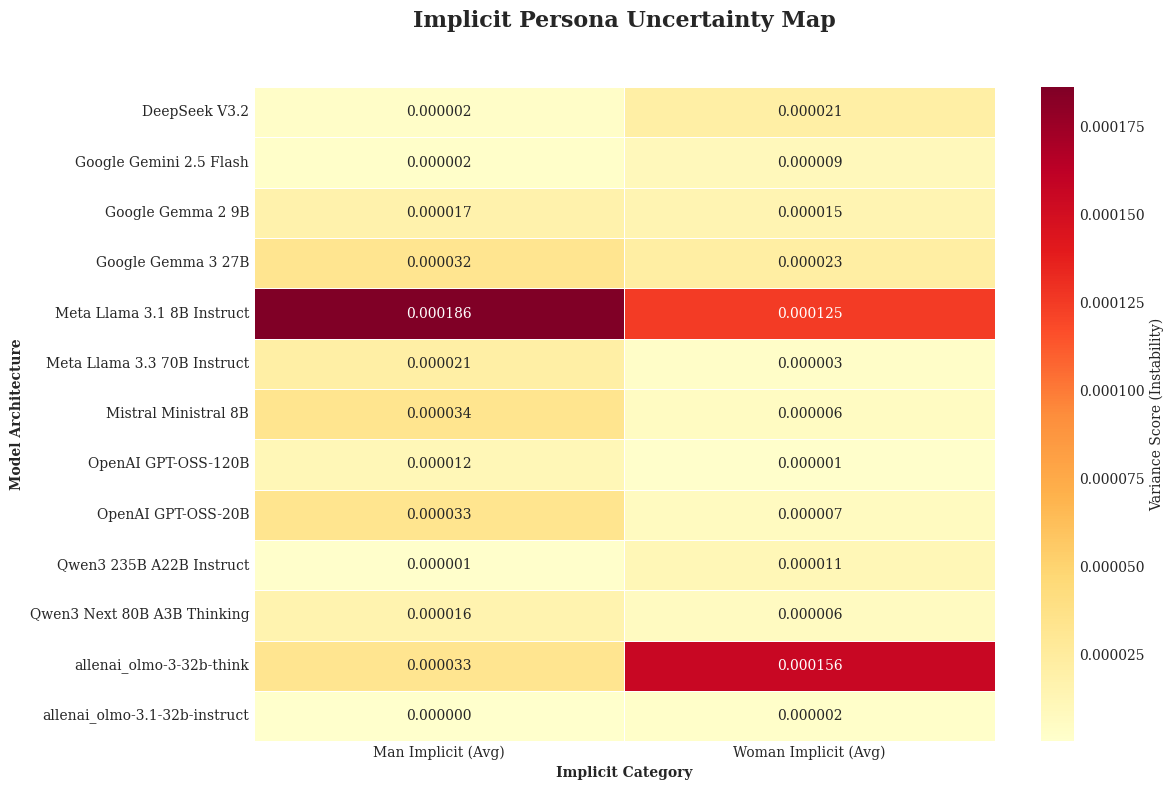

In [ ]:
# 1. Hitung Statistik (Mean & Variance) langsung dari df_raw
# Kita pake 'var' (Varians) karena kamu ingin memplot Variance Map
df_stats_raw = df_raw.groupby(['Model', 'Category'])['Accuracy'].agg(['mean', 'var']).reset_index()

# 2. Filter hanya untuk kategori Implicit (Sesuai maumu, tanpa Neutral)
implicit_list = ['Man Implicit (Avg)', 'Woman Implicit (Avg)']
# Abel, kalau kamu punya sub-kategori implicit lain, tambahkan di list ini ya
df_imp_var = df_stats_raw[df_stats_raw['Category'].isin(implicit_list)]

# 3. Pivot data untuk Heatmap (pilih nilai 'var')
df_var_heatmap = df_imp_var.pivot(index='Model', columns='Category', values='var').fillna(0)

# 4. Visualisasi Heatmap
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8), dpi=100)
plt.rcParams['font.family'] = 'serif'

# Abel: Kita pake cmap 'YlOrRd' agar area yang 'High Variance' terlihat merah (waspada)
sns.heatmap(df_var_heatmap,
            annot=True,
            cmap='YlOrRd',
            fmt='.6f',
            linewidths=0.5,
            cbar_kws={'label': 'Variance Score (Instability)'})

plt.title('Implicit Persona Uncertainty Map\n',
          fontsize=16, fontweight='bold', pad=25)
plt.ylabel('Model Architecture', fontweight='bold')
plt.xlabel('Implicit Category', fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
# 1. Map size categories according to your list
size_cat_map = {
    'Google Gemma 2 9B': 'Small (7B–10B)',
    'Meta Llama 3.1 8B Instruct': 'Small (7B–10B)',
    'Mistral Ministral 8B': 'Small (7B–10B)',
    'OpenAI GPT-OSS-20B': 'Medium (15B–50B)',
    'Google Gemma 3 27B': 'Medium (15B–50B)',
    'AllenAI OLMo 3 32B Think': 'Medium (15B–50B)',
    'AllenAI OLMo 3.1 32B Instruct': 'Medium (15B–50B)',
    'Meta Llama 3.3 70B Instruct': 'Large (70B–100B)',
    'Qwen3 Next 80B A3B Thinking': 'Large (70B–100B)',
    'OpenAI GPT-OSS-120B': 'Very Large (100B–200B)',
    'Qwen3 235B A22B Instruct': 'Ultra Large (200B+)',
    'DeepSeek V3.2': 'Ultra Large (200B+)',
    'Google Gemini 2.5 Flash': 'Proprietary'
}

# Ensure df_raw has the 'Category' column, which should have been added by p40nHJVu_yWE
# If not, add it here for robustness
if 'Category' not in df_raw.columns:
    # Define get_category_eng function if not already defined
    def get_category_eng(name):
        if 'woman_explicit' in name: return 'Woman Explicit'
        if 'woman_implicit' in name: return 'Woman Implicit (Avg)'
        if 'man_explicit' in name: return 'Man Explicit'
        if 'man_implicit' in name: return 'Man Implicit (Avg)'
        if 'neutral' in name.lower(): return 'Neutral'
        return 'Other'
    df_raw['Category'] = df_raw['Persona'].apply(get_category_eng)

# Add Size_Category info to df_raw BEFORE grouping for std
df_raw['Size_Category'] = df_raw['Model'].map(size_cat_map)

# Now, calculate mean and std grouped by Size_Category and the (consolidated) Category
# This ensures that std is calculated across all individual implicit instances within a Size_Category
# and consolidated Category (e.g., 'Man Implicit (Avg)').
df_stats_for_pointplot = df_raw.groupby(['Size_Category', 'Category'])['Accuracy'].agg(['mean', 'std']).reset_index()

# 3. Filter only Implicit
df_imp_size = df_stats_for_pointplot[df_stats_for_pointplot['Category'].isin(['Man Implicit (Avg)', 'Woman Implicit (Avg)'])]

# 4. Order Size Categories (to sort the graph from small to large)
size_order = [
    'Small (7B–10B)', 'Medium (15B–50B)',
    'Large (70B–100B)', 'Very Large (100B–200B)', 'Ultra Large (200B+)', 'Proprietary'
]

# Also ensure that Size_Category is a categorical type for proper ordering in the plot
df_imp_size['Size_Category'] = pd.Categorical(df_imp_size['Size_Category'], categories=size_order, ordered=True)
# Sort df_imp_size by Size_Category to help sns.pointplot order it correctly
df_imp_size = df_imp_size.sort_values('Size_Category')

/tmp/ipykernel_14808/652960002.py:49: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_imp_size['Size_Category'] = pd.Categorical(df_imp_size['Size_Category'], categories=size_order, ordered=True)


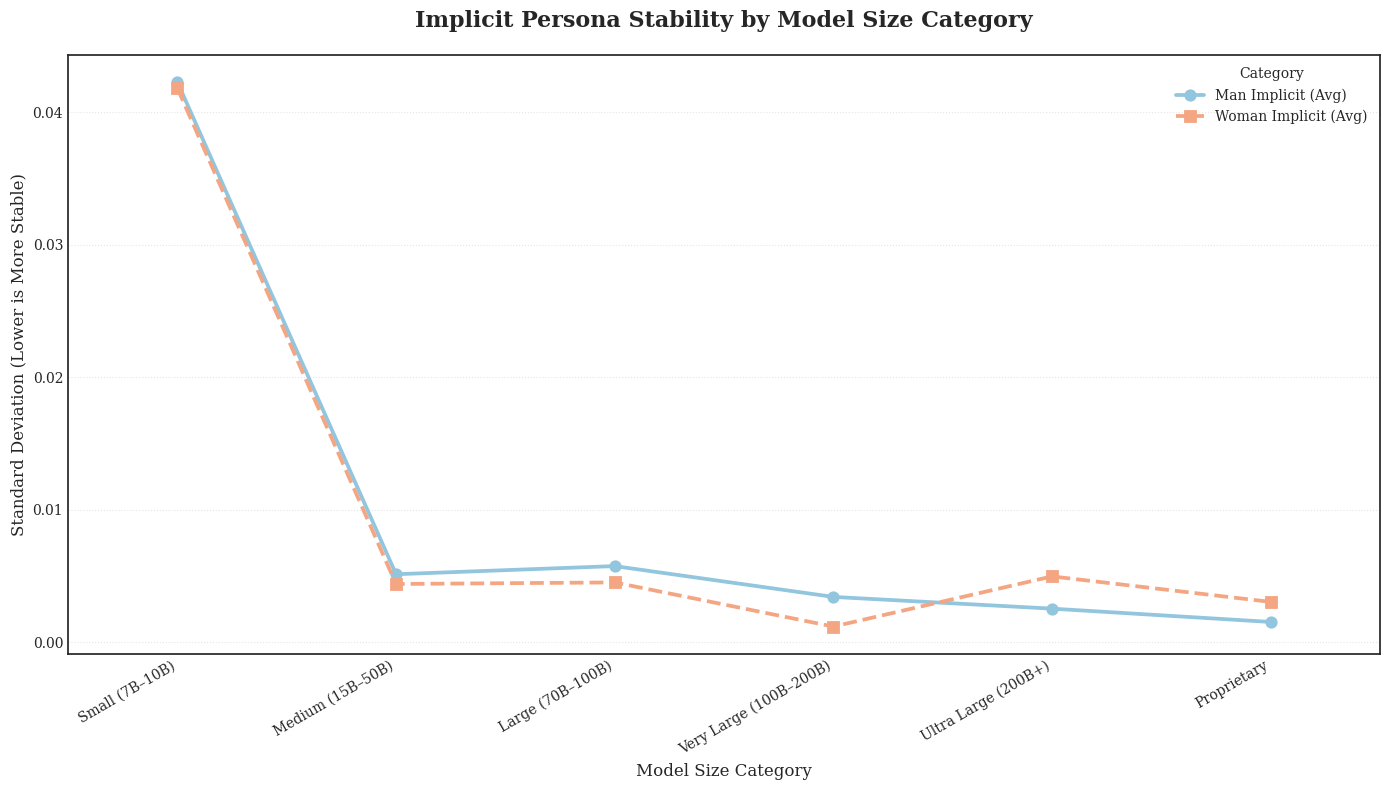

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))
plt.rcParams['font.family'] = 'serif'

# Visualize Standard Deviation trend by size
sns.pointplot(
    data=df_imp_size,
    x='Size_Category', y='std', hue='Category',
    order=size_order, palette=['#92c5de', '#f4a582'],
    markers=["o", "s"], linestyles=["-", "--"], capsize=.1
)

plt.title('Implicit Persona Stability by Model Size Category', fontsize=16, fontweight='bold', pad=20)
plt.ylabel('Standard Deviation (Lower is More Stable)', fontsize=12)
plt.xlabel('Model Size Category', fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

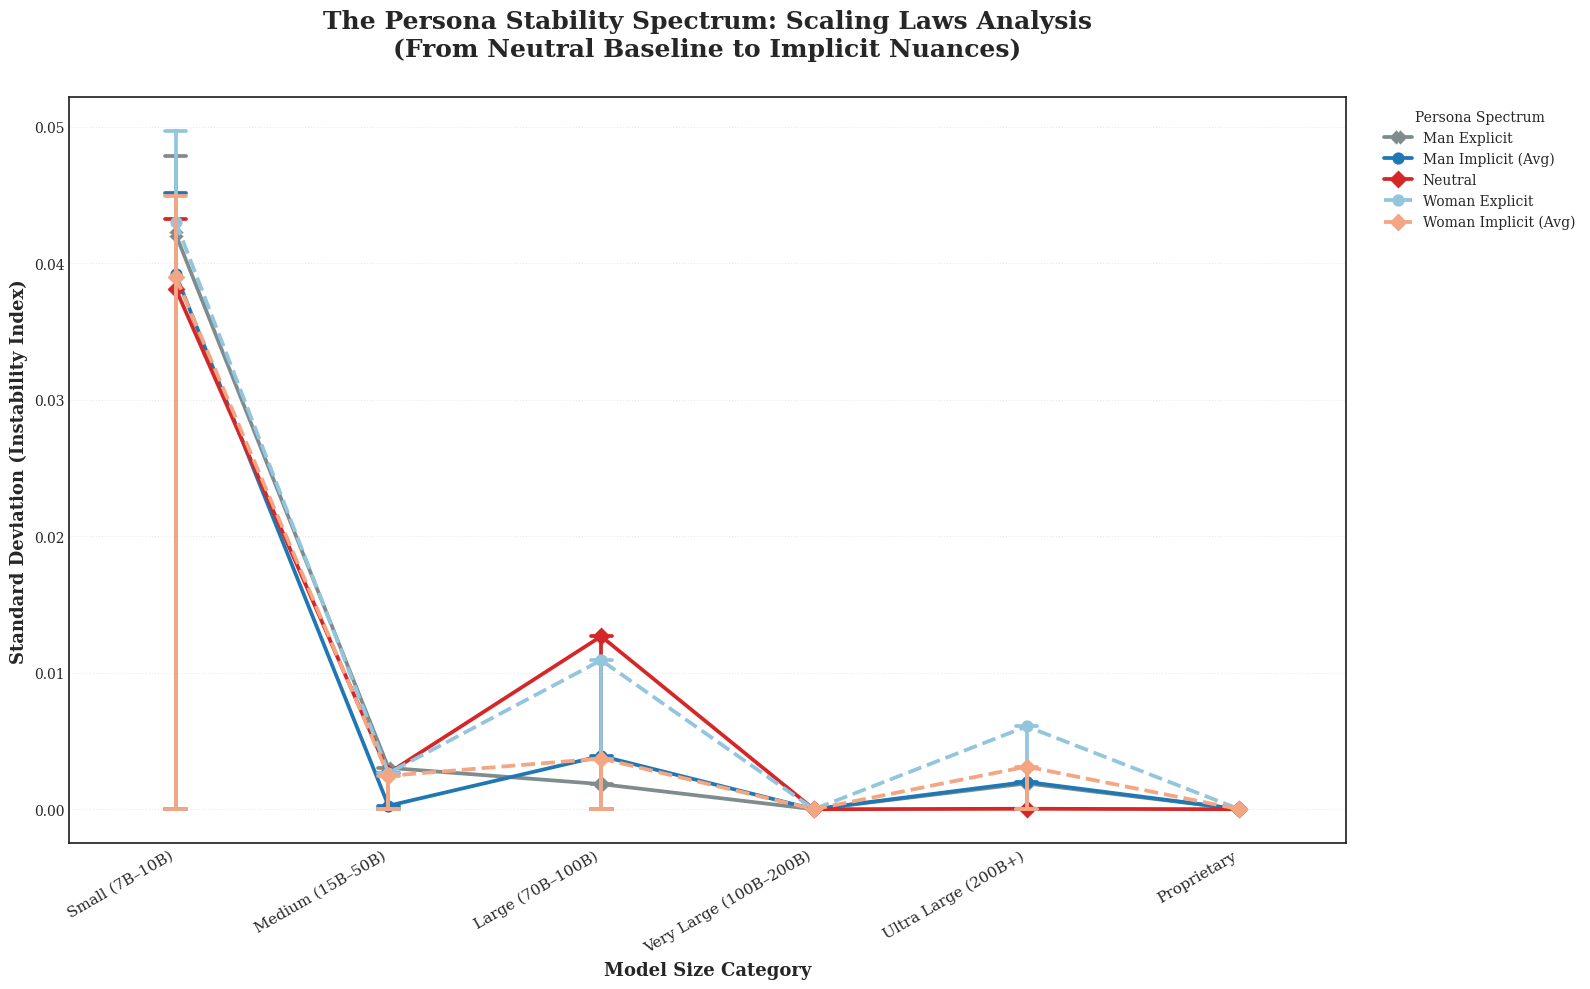

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Gunakan df_full (Raw Data) & Mapping Size
df_master = df_full.copy()
df_master['Size_Category'] = df_master['Model'].map(size_cat_map)

# 2. Filter 5 Kategori Utama (Spectrum Lengkap)
target_spectrum = [
    'Neutral',
    'Man Explicit', 'Woman Explicit',
    'Man Implicit (Avg)', 'Woman Implicit (Avg)'
]
df_master_filtered = df_master[df_master['Category'].isin(target_spectrum)]

# 3. Setup Urutan & Style
size_order = [
    'Small (7B–10B)', 'Medium (15B–50B)',
    'Large (70B–100B)', 'Very Large (100B–200B)', 'Ultra Large (200B+)', 'Proprietary'
]

# Palette Gradasi: Neutral (Abu), Explicit (Tegas), Implicit (Muda)
palette_5 = ['#7f8c8d', '#1f77b4', '#d62728', '#92c5de', '#f4a582']
markers_5 = ["X", "o", "D", "o", "D"]
lines_5 = ["-", "-", "-", "--", "--"] # Implicit dibikin putus-putus biar beda

# 4. Visualisasi
plt.figure(figsize=(16, 10), dpi=100)
plt.rcParams['font.family'] = 'serif'

sns.pointplot(
    data=df_master_filtered,
    x='Size_Category',
    y='Accuracy',           # Masukkan Accuracy mentah
    hue='Category',
    order=size_order,
    palette=palette_5,
    estimator=np.std,       # Biar Y-axis jadi Standard Deviation otomatis
    markers=markers_5,
    linestyles=lines_5,
    capsize=.1
)

# 5. Styling & Title
plt.title('The Persona Stability Spectrum: Scaling Laws Analysis\n(From Neutral Baseline to Implicit Nuances)',
          fontsize=18, fontweight='bold', pad=30)
plt.ylabel('Standard Deviation (Instability Index)', fontsize=13, fontweight='bold')
plt.xlabel('Model Size Category', fontsize=13, fontweight='bold')

plt.xticks(rotation=30, ha='right', fontsize=11)
plt.grid(axis='y', linestyle=':', alpha=0.4)
plt.legend(title='Persona Spectrum', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

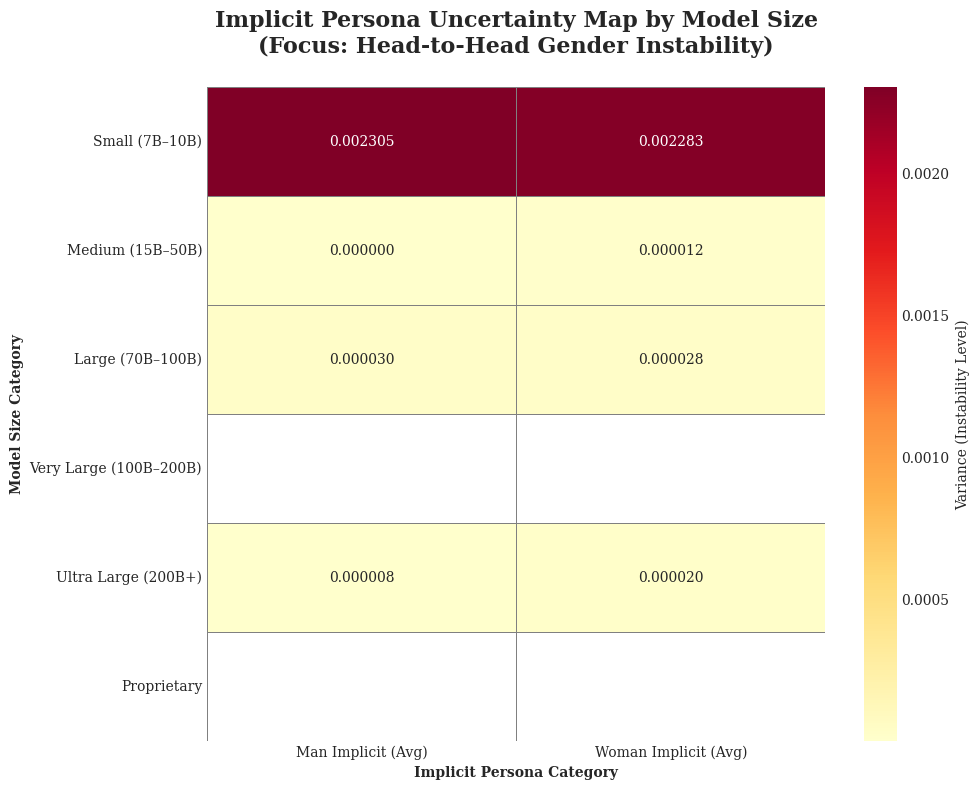

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Gunakan data mentah agar perhitungan varians valid
df_heatmap_raw = df_full.copy()
df_heatmap_raw['Size_Category'] = df_heatmap_raw['Model'].map(size_cat_map)

# 2. Hitung Varians (Accuracy) per Size dan per Category
# .var() di sini menghitung seberapa tidak stabil sebaran jawaban di kelas tersebut
df_var_grouped = df_heatmap_raw.groupby(['Size_Category', 'Category'])['Accuracy'].var().reset_index()

# 3. Filter: HANYA Implicit (Tanpa Neutral)
# Ini akan membuat perbandingan antar gender tersirat jadi lebih kontras
implicit_only = ['Man Implicit (Avg)', 'Woman Implicit (Avg)']
df_var_filtered = df_var_grouped[df_var_grouped['Category'].isin(implicit_only)]

# 4. Pivot & Reindex (Agar urutan ukuran model dari kecil ke besar)
pivot_var_size = df_var_filtered.pivot(index='Size_Category', columns='Category', values='Accuracy')
pivot_var_size = pivot_var_size.reindex(size_order)

# 5. Visualisasi Heatmap
plt.figure(figsize=(10, 8), dpi=100)
plt.rcParams['font.family'] = 'serif'

# Menggunakan YlOrRd: Semakin merah, semakin tinggi ketidakpastian/instabilitasnya
sns.heatmap(pivot_var_size,
            annot=True,
            cmap='YlOrRd',
            fmt='.6f',
            linewidths=0.5,
            linecolor='gray',
            cbar_kws={'label': 'Variance (Instability Level)'})

plt.title('Implicit Persona Uncertainty Map by Model Size\n(Focus: Head-to-Head Gender Instability)',
          fontsize=16, fontweight='bold', pad=25)
plt.ylabel('Model Size Category', fontweight='bold')
plt.xlabel('Implicit Persona Category', fontweight='bold')

plt.tight_layout()
plt.show()